# 77. Train pooled calibration-fault classifier: weighted K sampling and diagnostic checkpoints

**Purpose.** Train `PooledCalibrationClassifierModel` from random initialization with independently drawn fault counts, while allowing a single-switch time-only diagnostic. The 002.27-sized Transformer, KAIST datasets, augmentation pipeline, four optimizer LR groups, and existing evaluation workflow are preserved.

**Key changes:** `K_PROBABILITIES = (0.05, 0.85, 0.05, 0.05)` applies **only to stochastic training**; validation/test cover all K deliberately. `TRAINING_OBJECTIVE='joint'` trains the three outputs, while `'time_only'` trains the time output only, automatically changing loss weights, training modes, informative time bins, and checkpoint selection. A trained stochastic diagnostic **best and final checkpoint** is evaluated *before full training*, with per-K precision/recall/F1, AUROC and average precision for all three heads. Its optimizer never changes the full run's random initial weights.

**Interpretation:** A calibration mismatch label is not the same as sensor hardware unreliability. The per-sensor joint label is the physical OR of rotation/time faults by default. The earlier majority-override label policy remains available as an explicit opt-in, but is disabled by default to avoid rewarding a trivially all-positive classifier.


## 1. Imports and repository root

In [1]:
from pathlib import Path
import json
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.metrics import roc_auc_score, average_precision_score

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / 'src' / 'obscalib').is_dir():
        ROOT = candidate
        break
else:
    raise FileNotFoundError('Run inside nn-obs-calib or one of its subdirectories.')
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs, make_kaist_dataloader
from obscalib.augmentations.config import (AugmentationConfig, CalibrationEventConfig, CommonBodyFrameRandomizationConfig, FrameRandomizationConfig, NoiseAugmentationConfig, PerturbationMagnitudeConfig, PriorPerturbationConfig, SamplingRateAugmentationConfig, SensorTopologyAugmentationConfig, TrueCalibrationAugmentationConfig)
from obscalib.augmentations.pipeline import AugmentationPipeline
from obscalib.calibration.state import CalibrationState
from obscalib.config import CalibrationPoolerConfig, MLPConfig, PooledCalibrationHeadConfig, PooledCalibrationModelConfig, TransformerConfig, WindowingConfig
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.data.structures import SensorStreamBatch, WindowBatch
from obscalib.geometry.lie import so3_exp
from obscalib.geometry.processing import GeometryProcessor
from obscalib.models.pooled_calibration_classifier_model import PooledCalibrationClassifierModel, calibration_fault_loss
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.training.checkpoint import load_training_checkpoint, save_training_checkpoint

print('Repository:', ROOT, '| PyTorch:', torch.__version__, '| CUDA:', torch.cuda.is_available())

Repository: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib | PyTorch: 2.7.1+cu126 | CUDA: True


## 2. Experiment configuration, split and learning rates

In [ ]:
# Only TRAINING_OBJECTIVE needs changing to switch between all-head learning and a focused time-only diagnostic.
TRAINING_OBJECTIVE = 'joint'  # Options: 'joint', 'time_only'. Do NOT change FAULT_MODES separately for the standard diagnostic.
if TRAINING_OBJECTIVE not in ('joint', 'time_only'):
    raise ValueError(f'Unknown TRAINING_OBJECTIVE: {TRAINING_OBJECTIVE!r}')

RUN_NAME = f'kaist_pooled_calibration_classifier_005.1_{TRAINING_OBJECTIVE}_weighted_k'
RUN_DIR = ROOT / 'runs' / RUN_NAME
BEST_CHECKPOINT_PATH, LAST_CHECKPOINT_PATH = RUN_DIR / 'best.pt', RUN_DIR / 'last.pt'
STOCHASTIC_BEST_PATH, STOCHASTIC_FINAL_PATH = RUN_DIR / 'stochastic_best.pt', RUN_DIR / 'stochastic_final.pt'
RESUME_TRAINING = False  # Only checkpoints from this exact classifier training objective/config.
RUN_STOCHASTIC_TEST = True
RUN_STOCHASTIC_CHECKPOINT_EVALUATION = True
RUN_FULL_TRAINING = True
RUN_DETAILED_EVALUATION = True
RUN_TEST_EVALUATION = True  # Only after model selection/threshold tuning on validation.
REQUIRE_STOCHASTIC_IMPROVEMENT = False  # An advisory experiment, not a hard stop by default.

RANDOM_SEED = 77_0027
TRAIN_AUG_SEED, VALIDATION_AUG_SEED, TEST_AUG_SEED = 77_1001, 77_2002, 77_3003
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
MODEL_DTYPE = torch.float32
CALIBRATION_KEYS = ('imu', 'lidar', 'lidar_right')
TRAIN_NAMES = ('Urban08', 'Urban12', 'Urban13', 'Urban14', 'Urban15', 'Urban16')
VAL_NAMES = ('Urban26', 'Urban28')
TEST_NAMES = ('Urban38', 'Urban39')
assert len(set(TRAIN_NAMES + VAL_NAMES + TEST_NAMES)) == len(TRAIN_NAMES + VAL_NAMES + TEST_NAMES)

KAIST_DATASET_ROOT = Path('/mnt/d/Downloads/MobRobLab/KAISTDataset')
LIDAR_POSE_ROOT = Path('/home/camel/Skoltech/phd_proposal/data/KAISTDataset')
WINDOW_DURATION_S, WINDOW_STRIDE_S, MAX_SAMPLES_PER_SENSOR = 5.0, 5.0, 700
PHYSICAL_BATCH_SIZE, NUM_WORKERS = 16, 0
BATCH_SIZE = 32
MODEL_MICROBATCH_SIZE = BATCH_SIZE
PROFILE_FIRST_TRAIN_BATCH = False  # Print actual GPU memory and phase timings for the first optimizer update.
TRAIN_CASES_PER_PHYSICAL = 4  # Four independent K draws per physical window, not one copy of each K.
K_PROBABILITIES = (0.05, 0.85, 0.05, 0.05)  # P(K=0), P(K=1), P(K=2), P(K=3). TRAINING ONLY.
MONITOR_WINDOWS_PER_VAL_SEQUENCE = 64  # Evaluation is K-balanced, not sampled with K_PROBABILITIES.
DETAILED_WINDOWS_PER_SEQUENCE = 250
EVALUATION_PHYSICAL_BATCH_SIZE = 8
EVALUATION_MICROBATCH_SIZE = 16
NUM_EPOCHS = 200

# All weights begin random. Use independent LRs for the Transformer and the classifier head.
LR_TRANSFORMER = 1e-5
LR_POOLER = 2e-5
LR_SHARED_MLP = 2e-4
LR_CLASSIFIER_HEAD = 4e-4
WEIGHT_DECAY = 1e-4
GRADIENT_CLIP_NORM = 1.0
LR_REDUCTION_FACTOR, LR_PATIENCE_EPOCHS = 0.5, 10
CHECKPOINT_EVERY_EPOCHS, PRINT_EVERY_BATCHES = 3, 100

GT_ROT_TOL_DEG, GT_TAU_TOL_MS = 3.0, 10.0
MAJORITY_UNRELIABLE_WHEN_MOST_PERTURBED = False  # Recommended: true per-sensor fault labels, NOT the old K>=2 override.
# Train with positive supervision for time faults instead of only learning their class frequency.
# These are BCE logit losses (dimensionless); TIME_POS_WEIGHT reweights positives inside time BCE.
JOINT_LOSS_WEIGHT, ROTATION_LOSS_WEIGHT, TIME_LOSS_WEIGHT = (1.0, 0.5, 1.0) if TRAINING_OBJECTIVE == 'joint' else (0.0, 0.0, 1.0)
TIME_POS_WEIGHT = 1.0 if TRAINING_OBJECTIVE == 'joint' else 1.0
CHECKPOINT_TASK = 'joint' if TRAINING_OBJECTIVE == 'joint' else 'time'
CHECKPOINT_METRIC = 'f1' if TRAINING_OBJECTIVE == 'joint' else 'average_precision'
DEFAULT_DECISION_THRESHOLD = 0.5
PROBABILITY_THRESHOLDS = np.round(np.arange(0.05, 0.96, 0.05), 2)

TRUE_CALIBRATION_ROTATION_MAX_DEG, TRUE_CALIBRATION_TAU_MAX_S = 180.0, 0.030
ENABLE_SAMPLING_RATE_AUGMENTATION = False
ROTATION_BINS_DEG = ((2., 3.), (3., 4.), (4., 5.), (5., 15.), (15., 45.), (45., 90.), (90., 150.), (150., 179.))
# For the time-only diagnostic, all injected time faults exceed 50 ms. Modify this separately only if desired.
TIME_BINS_MS = ((10., 30.), (30., 50.), (50., 75.), (75., 100.), (100., 150.), (150., 500.)) if TRAINING_OBJECTIVE == 'joint' else ((75., 100.), (100., 150.), (150., 500.))
FAULT_MODES = ('rotation_only', 'time_only', 'both') if TRAINING_OBJECTIVE == 'joint' else ('time_only',)
FAULT_COUNTS = (0, 1, 2, 3)

MEASUREMENT_DIM, TOKEN_INPUT_DIM = 6, 8
D_MODEL, N_HEADS, NUM_TRANSFORMER_LAYERS, DIM_FEEDFORWARD = 128, 8, 12, 512
TRANSFORMER_DROPOUT, NUM_SUMMARY_TOKENS = 0.0, 1
POOLER_N_HEADS, POOLER_DROPOUT = 8, 0.0
MLP_HIDDEN_DIMS, SHARED_FEATURE_DIM, MLP_DROPOUT = (256, 128), 128, 0.0
HEAD_HIDDEN_DIMS, HEAD_DROPOUT = (128, 64), 0.0

# The stochastic preflight is independent of full training; always restore the random initial state.
SHOW_PLOTS, SAVE_PLOTS, PLOT_DPI = True, True, 150

if min(PHYSICAL_BATCH_SIZE, MODEL_MICROBATCH_SIZE, EVALUATION_MICROBATCH_SIZE, TRAIN_CASES_PER_PHYSICAL) < 1:
    raise ValueError('All batch sizes and cases per physical window must be positive.')
if len(K_PROBABILITIES) != len(FAULT_COUNTS) or any(p < 0 for p in K_PROBABILITIES) or not np.isclose(sum(K_PROBABILITIES), 1.0, atol=1e-10):
    raise ValueError('K_PROBABILITIES must be nonnegative, in K=0,1,2,3 order, and sum to 1.')
if not FAULT_MODES or not set(FAULT_MODES) <= {'rotation_only', 'time_only', 'both'}:
    raise ValueError(f'Unexpected FAULT_MODES: {FAULT_MODES}')
if hasattr(torch.backends, 'mha'):
    torch.backends.mha.set_fastpath_enabled(False)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if DEVICE.type == 'cuda':
    torch.cuda.manual_seed_all(RANDOM_SEED)
RUN_DIR.mkdir(parents=True, exist_ok=True)
print('Run:', RUN_NAME, '| Objective:', TRAINING_OBJECTIVE, '| Initialization:', 'RESUME classifier-only' if RESUME_TRAINING else 'SCRATCH all modules', '| Device:', DEVICE)
print('Training P(K=0,1,2,3):', K_PROBABILITIES, '| modes:', FAULT_MODES, '| time bins:', TIME_BINS_MS)
print('Loss weights (joint, rotation, time):', (JOINT_LOSS_WEIGHT, ROTATION_LOSS_WEIGHT, TIME_LOSS_WEIGHT), '| TIME_POS_WEIGHT:', TIME_POS_WEIGHT)
print('Checkpoint selection:', CHECKPOINT_TASK, CHECKPOINT_METRIC, '| majority policy:', MAJORITY_UNRELIABLE_WHEN_MOST_PERTURBED)
print('LRs:', dict(transformer=LR_TRANSFORMER, pooler=LR_POOLER, mlp=LR_SHARED_MLP, head=LR_CLASSIFIER_HEAD))

Run: kaist_pooled_calibration_classifier_005.1_joint_weighted_k | Objective: joint | Initialization: SCRATCH all modules | Device: cuda
Training P(K=0,1,2,3): (0.05, 0.85, 0.05, 0.05) | modes: ('rotation_only', 'time_only', 'both') | time bins: ((10.0, 30.0), (30.0, 50.0), (50.0, 75.0), (75.0, 100.0), (100.0, 150.0), (150.0, 500.0))
Loss weights (joint, rotation, time): (1.0, 0.5, 1.0) | TIME_POS_WEIGHT: 1.0
Checkpoint selection: joint f1 | majority policy: False
LRs: {'transformer': 1e-05, 'pooler': 2e-05, 'mlp': 0.0002, 'head': 0.0004}


## 3. KAIST calibration, physical train/validation/test datasets

In [3]:
T_B_L = np.array([
    [-0.514066, -0.702201, -0.492595, -0.440699],
    [ 0.486485, -0.711672,  0.506809,  0.397052],
    [-0.706447,  0.0208933, 0.707457,  1.90953],
    [0., 0., 0., 1.],
], dtype=float)
T_B_L_right = np.array([
    [-0.512152,  0.699241, -0.498761, -0.449885],
    [-0.494811, -0.714859, -0.494104, -0.416713],
    [-0.702041, -0.0062642, 0.712109, 1.91294],
    [0., 0., 0., 1.],
], dtype=float)
T_I_B = np.array([[1.,0.,0.,-0.07], [0.,1.,0.,0.], [0.,0.,1.,1.7], [0.,0.,0.,1.]])
rig_calibration = KAISTRigCalibration(
    T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, T_B_L_right=T_B_L_right,
    tau_imu_s=0.0, tau_lidar_s=-0.025, tau_lidar_right_s=-0.035,
)
windowing_config = WindowingConfig(window_duration_s=WINDOW_DURATION_S, window_stride_s=WINDOW_STRIDE_S, max_samples_per_sensor=MAX_SAMPLES_PER_SENSOR)
all_names = list(TRAIN_NAMES + VAL_NAMES + TEST_NAMES)
specs = build_kaist_sequence_specs(sequence_names=all_names, kaist_dataset_root=KAIST_DATASET_ROOT, lidar_pose_root=LIDAR_POSE_ROOT, lidar_right_pose_filename='lidar_map_poses_vlp_right.csv')
for spec in specs:
    if spec.lidar_right_pose_csv is None or not spec.lidar_right_pose_csv.is_file():
        raise FileNotFoundError(f'Missing right LiDAR odometry for {spec.name}: {spec.lidar_right_pose_csv}')
spec_by_name = {spec.name: spec for spec in specs}

def make_kaist_dataset(names):
    return KAISTCalibrationDataset([spec_by_name[name] for name in names], rig_calibration, windowing_config,
                                   measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)

train_dataset = make_kaist_dataset(TRAIN_NAMES)
val_dataset = make_kaist_dataset(VAL_NAMES)
test_dataset = make_kaist_dataset(TEST_NAMES)
for label, dataset in [('train', train_dataset), ('validation', val_dataset), ('test', test_dataset)]:
    assert tuple(dataset.calibration_keys) == CALIBRATION_KEYS, label
    print(label, 'windows=', len(dataset), '|', dataset.summary())

train_shuffle_generator = torch.Generator().manual_seed(RANDOM_SEED + 25)
train_loader = make_kaist_dataloader(train_dataset, batch_size=PHYSICAL_BATCH_SIZE, shuffle=True, drop_last=False, num_workers=NUM_WORKERS, generator=train_shuffle_generator)
print('Training physical batches:', len(train_loader))

# Validation indices are sampled once, then never shuffled between epochs.
# Use explicit split names, do not infer from dataset internal properties if unavailable.
def select_spread_indices_by_names(dataset, names, per_sequence, seed):
    rng = np.random.default_rng(seed)
    output = []
    for seq in names:
        available = np.asarray(dataset.window_indices_for_sequence(seq), dtype=int)
        count = len(available) if per_sequence is None else min(int(per_sequence), len(available))
        if not count:
            raise ValueError(f'No available windows for {seq}')
        if count == len(available):
            chosen = available
        else:
            edges = np.linspace(0, len(available), count + 1, dtype=int)
            chosen = available[[int(rng.integers(lo, hi)) for lo, hi in zip(edges[:-1], edges[1:])]]
        output.extend(chosen.tolist())
    return np.asarray(output, dtype=int)

monitor_val_indices = select_spread_indices_by_names(val_dataset, VAL_NAMES, MONITOR_WINDOWS_PER_VAL_SEQUENCE, RANDOM_SEED + 31)
detailed_val_indices = select_spread_indices_by_names(val_dataset, VAL_NAMES, DETAILED_WINDOWS_PER_SEQUENCE, RANDOM_SEED + 33)
detailed_test_indices = select_spread_indices_by_names(test_dataset, TEST_NAMES, DETAILED_WINDOWS_PER_SEQUENCE, RANDOM_SEED + 35)
print('Fixed validation monitor:', len(monitor_val_indices), '| detailed validation:', len(detailed_val_indices), '| final test:', len(detailed_test_indices))

train windows= 2006 | KAISTCalibrationDataset: 2006 windows from 6 sequences
approximate tensor storage: 44.0 MiB
  Urban08: windows=59, duration=297.8s, IMU=30800, LiDAR=2952, right LiDAR=2953
  Urban12: windows=473, duration=2478.6s, IMU=249198, LiDAR=23222, right LiDAR=23223
  Urban13: windows=223, duration=1446.5s, IMU=145492, LiDAR=10536, right LiDAR=10535
  Urban14: windows=286, duration=1737.0s, IMU=174681, LiDAR=13638, right LiDAR=13639
  Urban15: windows=184, duration=1034.3s, IMU=104795, LiDAR=9011, right LiDAR=9011
  Urban16: windows=781, duration=4458.1s, IMU=449215, LiDAR=37703, right LiDAR=37704
validation windows= 418 | KAISTCalibrationDataset: 418 windows from 2 sequences
approximate tensor storage: 9.2 MiB
  Urban26: windows=94, duration=566.9s, IMU=58371, LiDAR=4553, right LiDAR=4551
  Urban28: windows=324, duration=1958.5s, IMU=197456, LiDAR=15651, right LiDAR=15658
test windows= 699 | KAISTCalibrationDataset: 699 windows from 2 sequences
approximate tensor storage: 

## 4. Physical augmentation and the new scratch classifier

In [4]:
physical_config = AugmentationConfig(
    sensor_topology=SensorTopologyAugmentationConfig(enabled=False),
    sampling_rate=SamplingRateAugmentationConfig(enabled=ENABLE_SAMPLING_RATE_AUGMENTATION),
    frame_randomization=FrameRandomizationConfig(enabled=False),
    common_body_frame=CommonBodyFrameRandomizationConfig(enabled=False, probability=0.0),
    true_calibration=TrueCalibrationAugmentationConfig(
        enabled=True, probability=1.0, rotation_probability=1.0, translation_probability=0.0,
        time_offset_probability=1.0 if TRUE_CALIBRATION_TAU_MAX_S > 0 else 0.0,
        rotation=PerturbationMagnitudeConfig(maximum=np.deg2rad(TRUE_CALIBRATION_ROTATION_MAX_DEG)),
        time_offset=PerturbationMagnitudeConfig(maximum=TRUE_CALIBRATION_TAU_MAX_S),
    ),
    prior_perturbation=PriorPerturbationConfig(enabled=False),
    calibration_event=CalibrationEventConfig(enabled=False),
    noise=NoiseAugmentationConfig(enabled=False),
)
physical_augmenter = AugmentationPipeline(physical_config)
geometry_processor = GeometryProcessor()
tokenizer = Tokenizer(measurement_dim=MEASUREMENT_DIM, calibration_keys=CALIBRATION_KEYS)

model_config = PooledCalibrationModelConfig(
    transformer=TransformerConfig(input_dim=TOKEN_INPUT_DIM, d_model=D_MODEL, n_heads=N_HEADS, num_layers=NUM_TRANSFORMER_LAYERS, dim_feedforward=DIM_FEEDFORWARD, dropout=TRANSFORMER_DROPOUT, num_summary_tokens=NUM_SUMMARY_TOKENS, activation='gelu'),
    mlp=MLPConfig(hidden_dims=MLP_HIDDEN_DIMS, output_dim=SHARED_FEATURE_DIM, activation='gelu', dropout=MLP_DROPOUT),
    pooler=CalibrationPoolerConfig(n_heads=POOLER_N_HEADS, dropout=POOLER_DROPOUT, calibration_context_dim=0),
    head=PooledCalibrationHeadConfig(calibration_context_dim=0, hidden_dims=HEAD_HIDDEN_DIMS, activation='gelu', dropout=HEAD_DROPOUT),
)
model = PooledCalibrationClassifierModel(model_config).to(device=DEVICE, dtype=MODEL_DTYPE)
model.set_backbone_trainable(True)
if any(not p.requires_grad for p in model.parameters()):
    raise AssertionError('Scratch training must optimize all Transformer/pooler/MLP/head parameters.')

def make_optimizer(classifier):
    groups = [
        {'params': list(classifier.transformer_encoder.parameters()), 'lr': LR_TRANSFORMER, 'name': 'transformer'},
        {'params': list(classifier.pooler.parameters()), 'lr': LR_POOLER, 'name': 'pooler'},
        {'params': list(classifier.mlp_body.parameters()), 'lr': LR_SHARED_MLP, 'name': 'mlp_body'},
        {'params': list(classifier.head.parameters()), 'lr': LR_CLASSIFIER_HEAD, 'name': 'classifier_head'},
    ]
    expected = {id(p) for p in classifier.parameters() if p.requires_grad}
    actual = [id(p) for group in groups for p in group['params']]
    if len(actual) != len(set(actual)) or set(actual) != expected:
        raise AssertionError('Optimizer groups must cover each trainable parameter exactly once.')
    return torch.optim.AdamW(groups, weight_decay=WEIGHT_DECAY)

def make_generator(seed):
    return torch.Generator(device=DEVICE.type).manual_seed(int(seed))

print(type(model).__name__, 'parameters:', sum(p.numel() for p in model.parameters()))
print('Classifier output logits order: [joint operational fault, rotation fault, time fault]')
print('No regression checkpoint has been loaded.')

PooledCalibrationClassifierModel parameters: 2554115
Classifier output logits order: [joint operational fault, rotation fault, time fault]
No regression checkpoint has been loaded.


## 5. Weighted-K training sampler and physical fault labels

For every physical window, **training draws `TRAIN_CASES_PER_PHYSICAL` independent K values** using `K_PROBABILITIES` (by default, K=1 is 85% of cases; K=0,2,3 are each 5%). Active fault mode is sampled uniformly from `FAULT_MODES`. Every physically perturbed sensor gets an independent axis and/or time offset.

**Evaluation is different by design:** `balanced=True` produces one case per K for cheap fixed validation; `exhaustive=True` produces one clean plus every K×fault-mode case for detailed validation/test. These distributions are intentionally not reweighted to the training prior, so every difficult K remains visible. Rotation/time targets always mean actual tolerance violations; majority policy is optional for the joint output only.

In [5]:
def draw_magnitude(rng, bins):
    lower, upper = bins[int(rng.integers(len(bins)))]
    return float(rng.uniform(lower, upper))


def sample_fault_cases(batch_size, rng, *, exhaustive=False, balanced=False, original_indices=None, starting_id=0):
    """Training: weighted independent K draws. Validation: balanced or exhaustive coverage."""
    if exhaustive and balanced:
        raise ValueError('Choose at most one of exhaustive or balanced evaluation.')
    cases = []
    for row in range(batch_size):
        physical_id = int(original_indices[row]) if original_indices is not None else int(row)
        if exhaustive:
            variants = [(0, 'none')] + [(k, mode) for k in (1, 2, 3) for mode in FAULT_MODES]
        elif balanced:
            variants = [(0, 'none')] + [(k, FAULT_MODES[int(rng.integers(len(FAULT_MODES)))]) for k in (1, 2, 3)]
        else:
            ks = rng.choice(FAULT_COUNTS, size=TRAIN_CASES_PER_PHYSICAL, replace=True, p=K_PROBABILITIES)
            variants = [(int(k), 'none' if k == 0 else FAULT_MODES[int(rng.integers(len(FAULT_MODES)))]) for k in ks]
        for k, mode in variants:
            selected = tuple(sorted(rng.choice(CALIBRATION_KEYS, size=k, replace=False).tolist())) if k else ()
            rotations = {key: 0.0 for key in CALIBRATION_KEYS}
            tau_ms = {key: 0.0 for key in CALIBRATION_KEYS}
            axes = {key: np.zeros(3, dtype=float) for key in CALIBRATION_KEYS}
            for key in selected:
                if mode in ('rotation_only', 'both'):
                    rotations[key] = draw_magnitude(rng, ROTATION_BINS_DEG)
                    axis = rng.normal(size=3)
                    axes[key] = axis / np.linalg.norm(axis)
                if mode in ('time_only', 'both'):
                    tau_ms[key] = draw_magnitude(rng, TIME_BINS_MS) * float(rng.choice((-1, 1)))
            cases.append(dict(case_id=starting_id + len(cases), source_row=row, physical_id=physical_id, fault_count=k, fault_mode=mode,
                              injected_keys=selected, rotations=rotations, tau_ms=tau_ms, axes=axes))
    return cases


def faulted_window_from_cases(physical, cases):
    """Vectorized prior perturbation; ordinary tensors safe for training autograd (NOT inference_mode)."""
    indices = torch.as_tensor([c['source_row'] for c in cases], device=DEVICE, dtype=torch.long)
    streams = {}
    for key, stream in physical.streams.items():
        streams[key] = SensorStreamBatch(
            values=stream.values.index_select(0, indices),
            timestamps=stream.timestamps.index_select(0, indices),
            sample_mask=stream.sample_mask.index_select(0, indices),
            interval_start_timestamps=None if stream.interval_start_timestamps is None else stream.interval_start_timestamps.index_select(0, indices),
        )
    states = {}
    for key, truth_state in physical.current_calibration.items():
        R_truth = truth_state.transform.index_select(0, indices)
        tau_truth = truth_state.time_offset.index_select(0, indices)
        angles = torch.as_tensor([c['rotations'][key] for c in cases], device=DEVICE, dtype=MODEL_DTYPE)
        axes = torch.as_tensor(np.stack([c['axes'][key] for c in cases]), device=DEVICE, dtype=MODEL_DTYPE)
        delta_R = so3_exp(torch.deg2rad(angles)[:, None] * axes)
        transform = R_truth.clone()
        transform[:, :3, :3] = delta_R @ R_truth[:, :3, :3]
        dt = torch.as_tensor([c['tau_ms'][key] * 1e-3 for c in cases], device=DEVICE, dtype=MODEL_DTYPE)
        states[key] = CalibrationState(transform=transform, time_offset=tau_truth + dt.reshape_as(tau_truth))
    return WindowBatch(streams=streams, current_calibration=states, metadata=dict(physical.metadata), targets=None, dataset_indices=None)


def labels_from_cases(cases, calibration_keys=CALIBRATION_KEYS):
    """Return [B,C] targets for physical joint OR, rotation, and time (majority override optional)."""
    y_rotation = torch.as_tensor([[float(c['rotations'][key] > GT_ROT_TOL_DEG) for key in calibration_keys] for c in cases], device=DEVICE, dtype=MODEL_DTYPE)
    y_time = torch.as_tensor([[float(abs(c['tau_ms'][key]) > GT_TAU_TOL_MS) for key in calibration_keys] for c in cases], device=DEVICE, dtype=MODEL_DTYPE)
    y_joint = torch.maximum(y_rotation, y_time)
    if MAJORITY_UNRELIABLE_WHEN_MOST_PERTURBED:
        if any(c['fault_count'] != len(c['injected_keys']) for c in cases):
            raise ValueError('fault_count must match the number of actually injected sensors.')
        majority = torch.as_tensor([len(c['injected_keys']) > len(calibration_keys) / 2 for c in cases], device=DEVICE, dtype=torch.bool)
        y_joint = torch.where(majority[:, None], torch.ones_like(y_joint), y_joint)
    return y_joint, y_rotation, y_time


def tokenize_window(window):
    streams = geometry_processor(window.streams, window.metadata, window.current_calibration)
    return tokenizer(streams, calibration_keys=tuple(window.current_calibration))


def classifier_loss(output, rotation_targets, time_targets, *, joint_targets=None):
    """The only loss adapter. No .py module changes needed for time-only / weighted BCE."""
    logits = output.logits
    if logits.ndim != 3 or logits.shape[-1] != 3 or logits.shape[:2] != rotation_targets.shape or time_targets.shape != rotation_targets.shape:
        raise ValueError('Classifier logits/targets have incompatible shapes.')
    if joint_targets is None:
        joint_targets = torch.maximum(rotation_targets, time_targets)
    if joint_targets.shape != rotation_targets.shape:
        raise ValueError('joint_targets has an unexpected shape.')
    losses = {
        'joint': torch.nn.functional.binary_cross_entropy_with_logits(logits[..., 0], joint_targets),
        'rotation': torch.nn.functional.binary_cross_entropy_with_logits(logits[..., 1], rotation_targets),
        'time': torch.nn.functional.binary_cross_entropy_with_logits(logits[..., 2], time_targets, pos_weight=logits.new_tensor(TIME_POS_WEIGHT)),
    }
    total = JOINT_LOSS_WEIGHT * losses['joint'] + ROTATION_LOSS_WEIGHT * losses['rotation'] + TIME_LOSS_WEIGHT * losses['time']
    return total, losses


# Cheap sampler verification, independent of model inference.
probe_cases = sample_fault_cases(500, np.random.default_rng(RANDOM_SEED + 99))
probe_distribution = np.bincount([c['fault_count'] for c in probe_cases], minlength=4) / len(probe_cases)
print('Sampler probe P(K=0,1,2,3):', np.round(probe_distribution, 3), '| expected:', K_PROBABILITIES)
assert len(probe_cases) == 500 * TRAIN_CASES_PER_PHYSICAL
assert np.all(np.abs(probe_distribution - np.asarray(K_PROBABILITIES)) < 0.04), 'Weighted-K sampler differs unexpectedly from configured probabilities.'
print('Sampler ready: weighted training; balanced validation; exhaustive detailed evaluation.')

Sampler probe P(K=0,1,2,3): [0.046 0.851 0.054 0.048] | expected: (0.05, 0.85, 0.05, 0.05)
Sampler ready: weighted training; balanced validation; exhaustive detailed evaluation.


## 6. One-batch routing, label, and gradient smoke test

The smoke test uses balanced K coverage, **even though training samples K with configured probabilities**. This guarantees the entire pipeline sees K=0/1/2/3 in its basic checks.

In [6]:
raw_smoke = window_batch_to(collate_windows([train_dataset[0]]), DEVICE, dtype=MODEL_DTYPE)
physical_smoke = physical_augmenter(raw_smoke, generator=make_generator(RANDOM_SEED + 201)).augmented_window
smoke_cases = sample_fault_cases(1, np.random.default_rng(RANDOM_SEED + 202), balanced=True, original_indices=[0])
assert len(smoke_cases) == 4
assert {case['fault_count'] for case in smoke_cases} == set(FAULT_COUNTS)
smoke_window = faulted_window_from_cases(physical_smoke, smoke_cases)
smoke_tokens = tokenize_window(smoke_window)
smoke_y_joint, smoke_y_rot, smoke_y_tau = labels_from_cases(smoke_cases, smoke_tokens.calibration_keys)
for i, case in enumerate(smoke_cases):
    expected_joint = torch.ones_like(smoke_y_joint[i]) if (MAJORITY_UNRELIABLE_WHEN_MOST_PERTURBED and case['fault_count'] > len(CALIBRATION_KEYS) / 2) else torch.maximum(smoke_y_rot[i], smoke_y_tau[i])
    assert torch.equal(smoke_y_joint[i], expected_joint), f"Joint-label policy failed for K={case['fault_count']}"

model.train()
model.zero_grad(set_to_none=True)
smoke_output = model(smoke_tokens)
assert smoke_output.logits.shape == (4, 3, 3), smoke_output.logits.shape
assert tuple(smoke_output.calibration_keys) == CALIBRATION_KEYS
smoke_loss, smoke_parts = classifier_loss(smoke_output, smoke_y_rot, smoke_y_tau, joint_targets=smoke_y_joint)
smoke_loss.backward()
for name in ('transformer_encoder', 'pooler', 'mlp_body', 'head'):
    parameters = tuple(getattr(model, name).parameters())
    grad_norm = sum(float(p.grad.norm().item()) for p in parameters if p.grad is not None)
    assert np.isfinite(grad_norm) and grad_norm > 0, f'{name}: no nonzero gradient'
    print(f'Gradient smoke {name:20s}: norm sum {grad_norm:.6f}')
assert torch.isfinite(smoke_loss)
print('Smoke PASS | loss:', round(float(smoke_loss.item()), 5), '| parts:', {k: round(float(v.item()), 4) for k, v in smoke_parts.items()})
print('Positive labels (joint / rotation / time):', int(smoke_y_joint.sum()), int(smoke_y_rot.sum()), int(smoke_y_tau.sum()))
model.zero_grad(set_to_none=True)
del smoke_output, smoke_window, smoke_tokens

Gradient smoke transformer_encoder : norm sum 0.111469
Gradient smoke pooler              : norm sum 0.013446
Gradient smoke mlp_body            : norm sum 0.048090
Gradient smoke head                : norm sum 0.751213
Smoke PASS | loss: 1.73178 | parts: {'joint': 0.6934, 'rotation': 0.694, 'time': 0.6914}
Positive labels (joint / rotation / time): 6 6 1


## 7. Batched optimizer steps and precision/recall/F1 helpers

In [16]:
def train_case_batch(classifier, optimizer, physical, cases, *, microbatch_size, profile=False):
    """One optimizer update, with exact case weighting under gradient accumulation.

    When profile=True, synchronize CUDA between phases to measure first-batch preprocessing,
    forward, backward, and optimizer timings. Normal training has no additional syncs.
    """
    classifier.train()
    optimizer.zero_grad(set_to_none=True)
    accum = {'joint': 0.0, 'rotation': 0.0, 'time': 0.0}
    total = 0.0
    profile_times = {'preprocess': 0.0, 'forward_loss': 0.0, 'backward': 0.0, 'optimizer': 0.0}
    first_token_shape = None
    if profile:
        if DEVICE.type == 'cuda':
            torch.cuda.synchronize()
            torch.cuda.reset_peak_memory_stats()
        last_tick = time.perf_counter()
    for pos in range(0, len(cases), microbatch_size):
        mini = cases[pos:pos + microbatch_size]
        window = faulted_window_from_cases(physical, mini)
        tokens = tokenize_window(window)
        y_joint, y_rotation, y_time = labels_from_cases(mini, tokens.calibration_keys)
        if profile:
            if DEVICE.type == 'cuda':
                torch.cuda.synchronize()
            now = time.perf_counter()
            profile_times['preprocess'] += now - last_tick
            last_tick = now
            if first_token_shape is None:
                first_token_shape = tuple(tokens.x.shape)
        output = classifier(tokens)
        loss, parts = classifier_loss(output, y_rotation, y_time, joint_targets=y_joint)
        if profile:
            if DEVICE.type == 'cuda':
                torch.cuda.synchronize()
            now = time.perf_counter()
            profile_times['forward_loss'] += now - last_tick
            last_tick = now
        fraction = len(mini) / len(cases)
        (loss * fraction).backward()
        if profile:
            if DEVICE.type == 'cuda':
                torch.cuda.synchronize()
            now = time.perf_counter()
            profile_times['backward'] += now - last_tick
            last_tick = now
        total += float(loss.detach()) * fraction
        for k, v in parts.items():
            accum[k] += float(v.detach()) * fraction
    gradient_norm = float(torch.nn.utils.clip_grad_norm_(classifier.parameters(), max_norm=GRADIENT_CLIP_NORM))
    if not np.isfinite(gradient_norm):
        raise FloatingPointError('Non-finite gradient norm in classifier training.')
    optimizer.step()
    result = {'loss_total': total, **{f'loss_{k}': v for k, v in accum.items()}, 'gradient_norm': gradient_norm}
    if profile:
        if DEVICE.type == 'cuda':
            torch.cuda.synchronize()
        profile_times['optimizer'] = time.perf_counter() - last_tick
        result['profile_times'] = profile_times
        result['profile_microbatches'] = (len(cases) + microbatch_size - 1) // microbatch_size
        result['profile_first_token_shape'] = first_token_shape
        if DEVICE.type == 'cuda':
            result['profile_peak_allocated_gib'] = torch.cuda.max_memory_allocated() / 2**30
            result['profile_peak_reserved_gib'] = torch.cuda.max_memory_reserved() / 2**30
            result['profile_device_total_gib'] = torch.cuda.get_device_properties(DEVICE).total_memory / 2**30
    return result


def classification_counts(truth, alarm):
    tp = int(np.count_nonzero(alarm & truth))
    fp = int(np.count_nonzero(alarm & ~truth))
    fn = int(np.count_nonzero(~alarm & truth))
    tn = int(np.count_nonzero(~alarm & ~truth))
    precision = tp / (tp + fp) if (tp + fp) else np.nan
    recall = tp / (tp + fn) if (tp + fn) else np.nan
    f1 = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else np.nan
    specificity = tn / (tn + fp) if (tn + fp) else np.nan
    return dict(n=tp + fp + fn + tn, tp=tp, fp=fp, fn=fn, tn=tn,
                precision=precision, recall=recall, f1=f1, specificity=specificity,
                accuracy=(tp + tn) / (tp + fp + fn + tn), prevalence=(tp + fn) / (tp + fp + fn + tn))


def score_metrics(df, probability_threshold, *, task='joint'):
    target_field = {'joint':'target_joint', 'rotation':'target_rotation', 'time':'target_time'}[task]
    probability_field = {'joint':'prob_joint', 'rotation':'prob_rotation', 'time':'prob_time'}[task]
    y = df[target_field].to_numpy(dtype=bool)
    p = df[probability_field].to_numpy(dtype=float)
    metrics = classification_counts(y, p >= probability_threshold)
    metrics['prob_mean_positive'] = float(np.mean(p[y])) if y.any() else np.nan
    metrics['prob_mean_negative'] = float(np.mean(p[~y])) if (~y).any() else np.nan
    if y.any() and (~y).any():
        metrics['auroc'] = float(roc_auc_score(y, p))
        metrics['average_precision'] = float(average_precision_score(y, p))
    else:
        metrics['auroc'], metrics['average_precision'] = np.nan, np.nan
    return metrics


def grouped_metrics(df, threshold, *, task='joint'):
    groups = [('all', 'all', df)]
    groups += [('K', str(k), df[df.fault_count == k]) for k in (0, 1, 2, 3)]
    groups += [('sensor', sensor, df[df.sensor == sensor]) for sensor in CALIBRATION_KEYS]
    groups += [('fault_mode', mode, df[df.fault_mode == mode]) for mode in ('none', *FAULT_MODES)]
    groups += [('K_sensor', f'{k}|{sensor}', df[(df.fault_count == k) & (df.sensor == sensor)]) for k in (0, 1, 2, 3) for sensor in CALIBRATION_KEYS]
    rows = []
    for name, value, subset in groups:
        if not subset.empty:
            rows.append({'group': name, 'value': value, 'task': task, 'threshold': threshold, **score_metrics(subset, threshold, task=task)})
    return pd.DataFrame(rows)


def fixed_seeded_physical(raw, seed):
    # No inference_mode: tensors can safely be used later in backward in the training phase.
    with torch.no_grad():
        return physical_augmenter(raw, generator=make_generator(seed)).augmented_window

print('Optimizer and metric helpers ready.')


Optimizer and metric helpers ready.


In [18]:
# Optional batch-size benchmark. Run explicitly before full training (no optimizer step is taken).
# It uses one actual train_loader batch and restores the DataLoader's shuffle RNG state.
# It does NOT mutate model parameters or optimizer state. It only creates/clears gradients.
RUN_MICROBATCH_BENCHMARK = True
MICROBATCH_CANDIDATES = (8, 16, 32)  # Try 64 only if the earlier candidates fit comfortably.


def benchmark_classifier_microbatches(candidate_sizes=MICROBATCH_CANDIDATES):
    import gc

    shuffle_state = train_shuffle_generator.get_state()
    cpu_state = torch.get_rng_state()
    cuda_states = torch.cuda.get_rng_state_all() if DEVICE.type == 'cuda' else None
    try:
        raw_cpu = next(iter(train_loader))
        raw = window_batch_to(raw_cpu, DEVICE, dtype=MODEL_DTYPE)
        physical = fixed_seeded_physical(raw, TRAIN_AUG_SEED + 500123)
        rng = np.random.default_rng(RANDOM_SEED + 500123)
        cases = sample_fault_cases(next(iter(raw.current_calibration.values())).transform.shape[0], rng)
        print(f'Benchmark: {len(cases)} identical fault cases at every candidate microbatch size; no optimizer steps.')

        def evaluate_candidate(batch_size):
            # A separate scope ensures large graphs/activations are released even after CUDA OOM.
            model.zero_grad(set_to_none=True)
            if DEVICE.type == 'cuda':
                torch.cuda.synchronize()
                torch.cuda.reset_peak_memory_stats()
            start = time.perf_counter()
            for pos in range(0, len(cases), batch_size):
                mini = cases[pos:pos + batch_size]
                window = faulted_window_from_cases(physical, mini)
                tokens = tokenize_window(window)
                yj, yr, yt = labels_from_cases(mini, tokens.calibration_keys)
                loss, _ = classifier_loss(model(tokens), yr, yt, joint_targets=yj)
                (loss * (len(mini) / len(cases))).backward()
            if DEVICE.type == 'cuda':
                torch.cuda.synchronize()
            elapsed = time.perf_counter() - start
            peak_allocated = torch.cuda.max_memory_allocated() / 2**30 if DEVICE.type == 'cuda' else np.nan
            peak_reserved = torch.cuda.max_memory_reserved() / 2**30 if DEVICE.type == 'cuda' else np.nan
            return elapsed, peak_allocated, peak_reserved

        results = []
        model.train()
        for batch_size in candidate_sizes:
            model.zero_grad(set_to_none=True)
            gc.collect()
            if DEVICE.type == 'cuda':
                torch.cuda.empty_cache()
            try:
                elapsed, peak_allocated, peak_reserved = evaluate_candidate(int(batch_size))
                success, reason = True, ''
            except torch.cuda.OutOfMemoryError:
                success, reason = False, 'CUDA OOM'
                elapsed, peak_allocated, peak_reserved = np.nan, np.nan, np.nan
            finally:
                model.zero_grad(set_to_none=True)
                gc.collect()
                if DEVICE.type == 'cuda':
                    torch.cuda.empty_cache()
            results.append({'microbatch': batch_size, 'passes': (len(cases) + batch_size - 1)//batch_size,
                            'seconds_per_64_cases': elapsed * 64 / len(cases) if success else np.nan,
                            'peak_allocated_gib': peak_allocated, 'peak_reserved_gib': peak_reserved,
                            'status': 'OK' if success else reason})
        return pd.DataFrame(results)
    finally:
        model.zero_grad(set_to_none=True)
        train_shuffle_generator.set_state(shuffle_state)
        torch.set_rng_state(cpu_state)
        if cuda_states is not None:
            torch.cuda.set_rng_state_all(cuda_states)
        if DEVICE.type == 'cuda':
            torch.cuda.empty_cache()


if RUN_MICROBATCH_BENCHMARK:
    display(benchmark_classifier_microbatches().round(3))
else:
    print('Microbatch benchmark available. Set RUN_MICROBATCH_BENCHMARK=True here to compare 8, 16, 32 on your GPU.')


Benchmark: 256 identical fault cases at every candidate microbatch size; no optimizer steps.


,microbatch,passes,seconds_per_64_cases,peak_allocated_gib,peak_reserved_gib,status
0,8,32,2.022,0.999,1.105,OK
1,16,16,1.857,1.903,2.139,OK
2,32,8,1.812,3.766,3.973,OK


## 8. Deterministic batched validation/test runner

On the fixed validation monitor, every physical window supplies one case for **each K** (`balanced=True`), independent of the weighted training prior. The detailed evaluation visits K=0 and every K×active fault-mode combination (`exhaustive=True`), so none of the rare cases disappear from the statistics.

In [8]:
@torch.inference_mode()
def evaluate_cases(classifier, dataset, indices, *, split_seed, exhaustive, physical_batch_size=EVALUATION_PHYSICAL_BATCH_SIZE, inference_batch_size=EVALUATION_MICROBATCH_SIZE):
    classifier.eval()
    rows = []
    loss_numerator, case_count = 0.0, 0
    for start in range(0, len(indices), physical_batch_size):
        original_indices = np.asarray(indices[start:start + physical_batch_size], dtype=int)
        raw = window_batch_to(collate_windows([dataset[int(i)] for i in original_indices]), DEVICE, dtype=MODEL_DTYPE)
        physical = physical_augmenter(raw, generator=make_generator(split_seed + start * 1009)).augmented_window
        rng = np.random.default_rng(split_seed + start * 7919 + 97)
        cases = sample_fault_cases(len(original_indices), rng, exhaustive=exhaustive, balanced=not exhaustive, original_indices=original_indices, starting_id=start * 20)
        for pos in range(0, len(cases), inference_batch_size):
            mini = cases[pos:pos + inference_batch_size]
            tokens = tokenize_window(faulted_window_from_cases(physical, mini))
            yj, yr, yt = labels_from_cases(mini, tokens.calibration_keys)
            output = classifier(tokens)
            loss, _ = classifier_loss(output, yr, yt, joint_targets=yj)
            loss_numerator += float(loss.detach()) * len(mini)
            case_count += len(mini)
            prob = output.logits.sigmoid().detach().cpu().numpy()
            yj_cpu, yr_cpu, yt_cpu = yj.detach().cpu().numpy(), yr.detach().cpu().numpy(), yt.detach().cpu().numpy()
            for bi, item in enumerate(mini):
                for ci, key in enumerate(tokens.calibration_keys):
                    rows.append(dict(case_id=item['case_id'], physical_index=item['physical_id'], fault_count=item['fault_count'], fault_mode=item['fault_mode'], sensor=key,
                                     injected=int(key in item['injected_keys']), true_rotation_deg=item['rotations'][key], true_tau_ms=item['tau_ms'][key],
                                     target_rotation=int(yr_cpu[bi, ci]), target_time=int(yt_cpu[bi, ci]), target_joint_operational=int(max(yr_cpu[bi, ci], yt_cpu[bi, ci])),
                                     target_joint=int(yj_cpu[bi, ci]), majority_override=int(MAJORITY_UNRELIABLE_WHEN_MOST_PERTURBED and item['fault_count'] > len(tokens.calibration_keys) / 2),
                                     prob_joint=float(prob[bi, ci, 0]), prob_rotation=float(prob[bi, ci, 1]), prob_time=float(prob[bi, ci, 2])))
    if not rows:
        raise RuntimeError('Evaluation produced zero sensor rows.')
    df = pd.DataFrame(rows)
    if df.groupby('case_id').sensor.nunique().ne(3).any():
        raise AssertionError('One or more cases do not have exactly three classification heads.')
    return df, loss_numerator / case_count


def log_case_report(df, title, *, threshold=DEFAULT_DECISION_THRESHOLD):
    print(f'\n{title} | task={CHECKPOINT_TASK} | {df.case_id.nunique():,} cases | {len(df):,} sensor classifications | threshold={threshold:.2f}')
    summary = grouped_metrics(df, threshold, task=CHECKPOINT_TASK)
    display(summary[summary.group.isin(['all', 'K'])][['group', 'value', 'n', 'tp', 'fp', 'fn', 'tn', 'precision', 'recall', 'f1']].round(3))
    return summary

print('Deterministic evaluation helper ready.')


Deterministic evaluation helper ready.


## 9. Independent stochastic learnability diagnostic (trained checkpoints retained)

Train fresh augmentations and weighted K cases from a small pool of 16 training windows. Select the best **stochastic** checkpoint by fixed, held-out validation BCE. Save *both* `stochastic_best.pt` and `stochastic_final.pt` before restoring the original scratch weights. A new evaluation section below loads each checkpoint into a separate temporary model, reporting joint/rotation/time F1, AUROC, average precision, and positive-label prevalence. This is independent of full training.

Stochastic initial held-out loss=1.7357 | joint F1=0.7335 AP=0.5828
step    1/1000 train=1.7504 fixed-val=1.7352 jointF1=0.734 rotF1=0.537 timeF1=0.000 timeAP=0.412 grad=0.320
step   25/1000 train=1.5547 fixed-val=1.7697 jointF1=0.000 rotF1=0.000 timeF1=0.000 timeAP=0.360 grad=0.524
step   50/1000 train=1.5940 fixed-val=1.8977 jointF1=0.000 rotF1=0.000 timeF1=0.000 timeAP=0.383 grad=0.831
step   75/1000 train=1.4242 fixed-val=1.8761 jointF1=0.000 rotF1=0.000 timeF1=0.000 timeAP=0.380 grad=0.113
step  100/1000 train=1.3916 fixed-val=1.8341 jointF1=0.000 rotF1=0.000 timeF1=0.000 timeAP=0.377 grad=0.491
step  125/1000 train=1.4251 fixed-val=1.9021 jointF1=0.000 rotF1=0.000 timeF1=0.000 timeAP=0.376 grad=0.323
step  150/1000 train=1.3648 fixed-val=1.9246 jointF1=0.000 rotF1=0.000 timeF1=0.000 timeAP=0.400 grad=0.243
step  175/1000 train=1.4842 fixed-val=1.8141 jointF1=0.000 rotF1=0.000 timeF1=0.000 timeAP=0.404 grad=0.403
step  200/1000 train=1.3647 fixed-val=1.9260 jointF1=0.000 rotF1=0.0

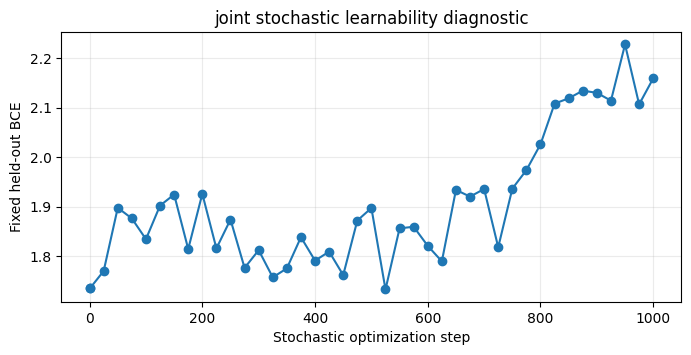

In [ ]:

STOCHASTIC_STEPS = 1000
STOCHASTIC_PHYSICAL_WINDOWS = 8
STOCHASTIC_EVAL_WINDOWS = 8
STOCHASTIC_PRINT_EVERY = 25
STOCHASTIC_CHECKPOINT_EVAL_WINDOWS = 64  # Further held-out validation windows, not used for the stochastic checkpoint selection.
STOCHASTIC_DIAGNOSTIC_PASSED = None
stochastic_history = []
if RUN_STOCHASTIC_TEST and not RESUME_TRAINING:
    initial_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
    diagnostic_optimizer = make_optimizer(model)
    diag_train_indices = np.arange(min(STOCHASTIC_PHYSICAL_WINDOWS, len(train_dataset)), dtype=int)
    diag_eval_indices = monitor_val_indices[:min(STOCHASTIC_EVAL_WINDOWS, len(monitor_val_indices))]
    diag_fixed, initial_eval_loss = evaluate_cases(model, val_dataset, diag_eval_indices, split_seed=VALIDATION_AUG_SEED + 119, exhaustive=True)
    initial_metrics = score_metrics(diag_fixed, DEFAULT_DECISION_THRESHOLD, task=CHECKPOINT_TASK)
    print(f'Stochastic initial held-out loss={initial_eval_loss:.4f} | {CHECKPOINT_TASK} F1={initial_metrics["f1"]:.4f} AP={initial_metrics["average_precision"]:.4f}')
    best_stochastic_loss = float('inf')
    try:
        for step in range(1, STOCHASTIC_STEPS + 1):
            rng = np.random.default_rng(RANDOM_SEED + 777_000 + step)
            chosen = rng.choice(diag_train_indices, size=min(PHYSICAL_BATCH_SIZE, len(diag_train_indices)), replace=False)
            raw = window_batch_to(collate_windows([train_dataset[int(i)] for i in chosen]), DEVICE, dtype=MODEL_DTYPE)
            physical = fixed_seeded_physical(raw, TRAIN_AUG_SEED + step * 7)
            cases = sample_fault_cases(len(chosen), rng, original_indices=chosen)
            train_result = train_case_batch(model, diagnostic_optimizer, physical, cases, microbatch_size=MODEL_MICROBATCH_SIZE)
            if step == 1 or step % STOCHASTIC_PRINT_EVERY == 0 or step == STOCHASTIC_STEPS:
                diag_eval, eval_loss = evaluate_cases(model, val_dataset, diag_eval_indices, split_seed=VALIDATION_AUG_SEED + 119, exhaustive=True)
                measurements = {task: score_metrics(diag_eval, DEFAULT_DECISION_THRESHOLD, task=task) for task in ('joint', 'rotation', 'time')}
                selected = measurements[CHECKPOINT_TASK]
                stochastic_history.append(dict(step=step, train_loss=train_result['loss_total'], eval_loss=eval_loss, eval_f1=selected['f1'],
                                               eval_ap=selected['average_precision'], eval_rot_f1=measurements['rotation']['f1'],
                                               eval_time_f1=measurements['time']['f1'], eval_time_ap=measurements['time']['average_precision'],
                                               grad_norm=train_result['gradient_norm']))
                print(f'step {step:4d}/{STOCHASTIC_STEPS} train={train_result["loss_total"]:.4f} fixed-val={eval_loss:.4f} '
                      f'{CHECKPOINT_TASK}F1={selected["f1"]:.3f} rotF1={measurements["rotation"]["f1"]:.3f} '
                      f'timeF1={measurements["time"]["f1"]:.3f} timeAP={measurements["time"]["average_precision"]:.3f} grad={train_result["gradient_norm"]:.3f}')
                if np.isfinite(eval_loss) and eval_loss < best_stochastic_loss:
                    best_stochastic_loss = eval_loss
                    torch.save({'model_state_dict': {name: tensor.detach().cpu().clone() for name, tensor in model.state_dict().items()},
                                'step': step, 'eval_loss': eval_loss, 'objective': TRAINING_OBJECTIVE}, STOCHASTIC_BEST_PATH)
        torch.save({'model_state_dict': {name: tensor.detach().cpu().clone() for name, tensor in model.state_dict().items()},
                    'step': STOCHASTIC_STEPS, 'eval_loss': eval_loss, 'objective': TRAINING_OBJECTIVE}, STOCHASTIC_FINAL_PATH)
        STOCHASTIC_DIAGNOSTIC_PASSED = best_stochastic_loss < initial_eval_loss
        print('Stochastic diagnostic:', 'IMPROVED' if STOCHASTIC_DIAGNOSTIC_PASSED else 'NO FIXED-VAL LOSS IMPROVEMENT')
        print('Saved diagnostic checkpoints:', STOCHASTIC_BEST_PATH.name, STOCHASTIC_FINAL_PATH.name)
    finally:
        model.load_state_dict(initial_state, strict=True)
        model.zero_grad(set_to_none=True)
        del diagnostic_optimizer, initial_state
        if DEVICE.type == 'cuda':
            torch.cuda.empty_cache()
    pd.DataFrame(stochastic_history).to_csv(RUN_DIR / 'stochastic_diagnostic.csv', index=False)
    if stochastic_history:
        fig, ax = plt.subplots(figsize=(8, 3.5))
        ax.plot([0] + [r['step'] for r in stochastic_history], [initial_eval_loss] + [r['eval_loss'] for r in stochastic_history], marker='o')
        ax.set(xlabel='Stochastic optimization step', ylabel='Fixed held-out BCE', title=f'{TRAINING_OBJECTIVE} stochastic learnability diagnostic')
        ax.grid(alpha=0.25)
        if SAVE_PLOTS: fig.savefig(RUN_DIR / 'stochastic_diagnostic.png', dpi=PLOT_DPI, bbox_inches='tight')
        if SHOW_PLOTS: plt.show()
        else: plt.close(fig)
else:
    print('Stochastic diagnostic skipped; no regression initialization is used.')

In [30]:
def inspect_stochastic_predictions():
    rows = []

    for stage, df in [("initial", diag_fixed), ("final", diag_eval)]:
        for task in ("joint", "rotation", "time"):
            y = df[f"target_{task}"].to_numpy(dtype=bool)
            p = df[f"prob_{task}"].to_numpy(dtype=float)

            metrics = score_metrics(df, 0.5, task=task)
            thresholds = [
                (float(t), score_metrics(df, float(t), task=task))
                for t in PROBABILITY_THRESHOLDS
            ]
            best_t, best = max(
                thresholds,
                key=lambda item: np.nan_to_num(item[1]["f1"], nan=-1.0),
            )

            prevalence = y.mean()
            always_positive_f1 = 2 * prevalence / (1 + prevalence)

            rows.append({
                "stage": stage,
                "task": task,
                "GT_positive_fraction": prevalence,
                "predicted_positive_fraction_05": (p >= 0.5).mean(),
                "mean_probability": p.mean(),
                "p10": np.quantile(p, 0.1),
                "p50": np.median(p),
                "p90": np.quantile(p, 0.9),
                "F1_05": metrics["f1"],
                "always_positive_F1": always_positive_f1,
                "AUROC": metrics["auroc"],
                "AP": metrics["average_precision"],
                "best_threshold": best_t,
                "best_F1": best["f1"],
            })

    return pd.DataFrame(rows)


display(inspect_stochastic_predictions().round(3))

,stage,task,GT_positive_fraction,predicted_positive_fraction_05,mean_probability,p10,p50,p90,F1_05,always_positive_F1,AUROC,AP,best_threshold,best_F1
0,initial,joint,0.579,1.000,0.510,0.510,0.510,0.510,0.734,0.734,0.484,0.583,0.05,0.734
1,initial,rotation,0.367,1.000,0.521,0.521,0.521,0.521,0.537,0.537,0.360,0.352,0.05,0.537
2,initial,time,0.400,0.000,0.499,0.499,0.499,0.499,0.000,0.571,0.532,0.422,0.05,0.571
3,final,joint,0.579,0.442,0.492,0.133,0.418,0.933,0.563,0.734,0.560,0.655,0.10,0.730
4,final,rotation,0.367,0.358,0.383,0.049,0.248,0.851,0.368,0.537,0.570,0.464,0.15,0.538
5,final,time,0.400,0.150,0.296,0.105,0.265,0.520,0.288,0.571,0.525,0.463,0.10,0.580


## 9a. Evaluate trained stochastic checkpoints before full training

Loads **both** stochastic checkpoints into a separate classifier. Measures every head at 0.5, plus threshold-free **AUROC and average precision** against each task's positive-label fraction, and the best achievable validation F1 over a probability sweep. Breakdowns for K=0,1,2,3 expose whether time fault recognition works specifically for K=1. Uses additional validation physical windows beyond the 8-window checkpoint-selection probe. The full-training model stays at its original random initialization.

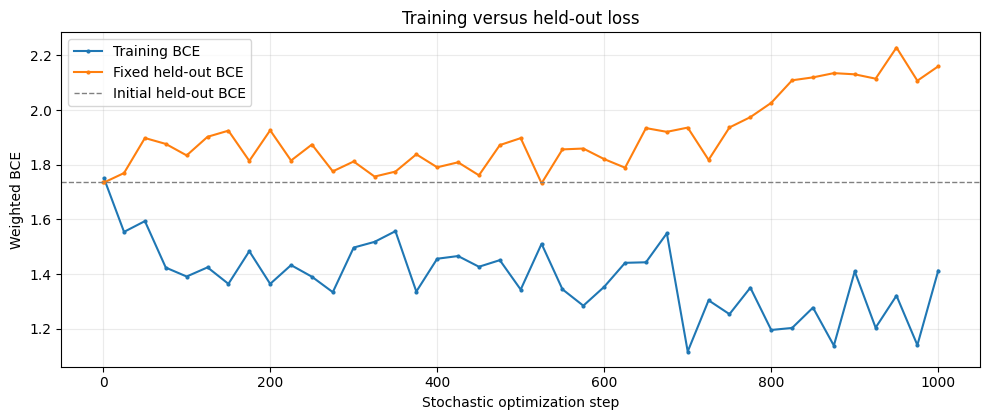

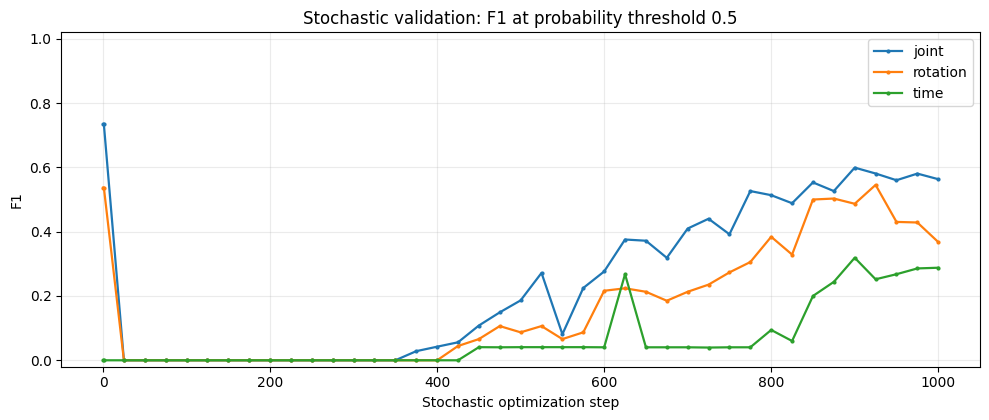

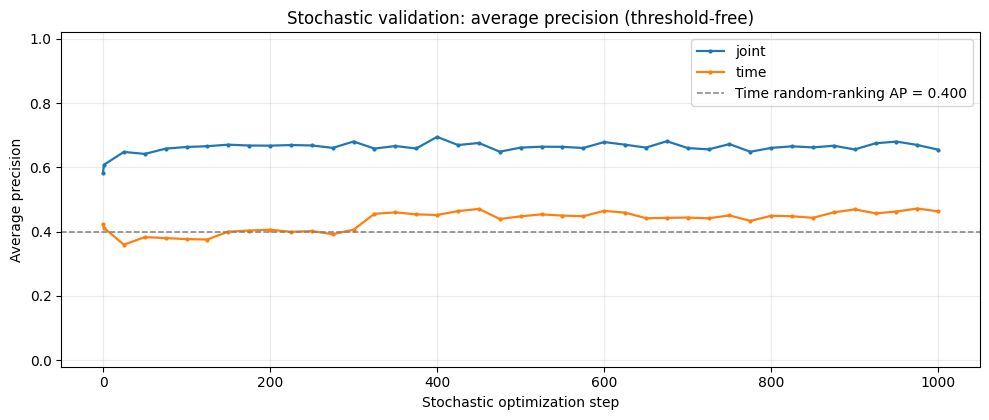

Note: rotation AP was not logged over time in this run; no rotation AP curve can be reconstructed from the two checkpoints.


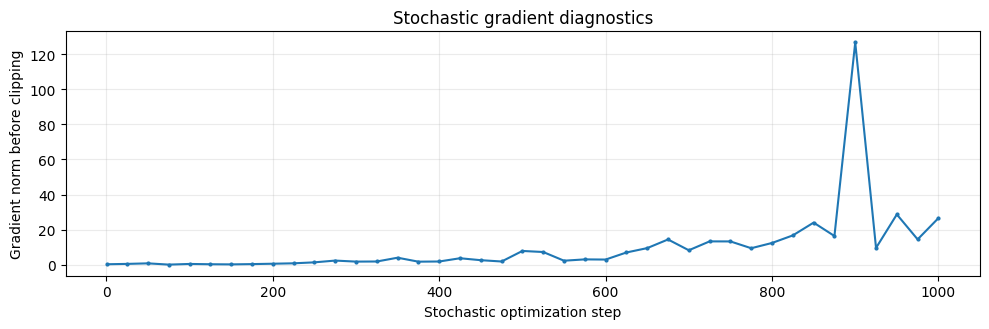

Checkpoint sanity check on 64 additional held-out validation windows.
ACTIVE time settings: GT_TAU_TOL_MS = 10.0 | TIME_BINS_MS = ((10.0, 30.0), (30.0, 50.0), (50.0, 75.0), (75.0, 100.0), (100.0, 150.0), (150.0, 500.0)) | modes = ('rotation_only', 'time_only', 'both')

STOCHASTIC BEST | step=525 | held-out BCE=1.7292


,task,K,n,prevalence,f1_05,auroc,average_precision,best_val_threshold,best_val_f1
0,joint,all,1920,0.573,0.242,0.610,0.666,0.05,0.728
1,joint,0,192,0.000,0.000,NaN,NaN,0.05,0.000
2,joint,1,576,0.323,0.300,0.618,0.480,0.05,0.488
3,joint,2,576,0.637,0.281,0.614,0.737,0.05,0.778
4,joint,3,576,0.950,0.197,0.566,0.964,0.05,0.974
5,rotation,all,1920,0.349,0.107,0.684,0.511,0.30,0.582
6,rotation,0,192,0.000,0.000,NaN,NaN,0.05,0.000
7,rotation,1,576,0.201,0.190,0.709,0.434,0.35,0.455
8,rotation,2,576,0.394,0.142,0.678,0.566,0.25,0.607
9,rotation,3,576,0.569,0.047,0.676,0.685,0.25,0.746


Time-target prevalence: observed=0.400, expected≈0.400

STOCHASTIC FINAL | step=1000 | held-out BCE=1.9911


,task,K,n,prevalence,f1_05,auroc,average_precision,best_val_threshold,best_val_f1
0,joint,all,1920,0.573,0.535,0.624,0.706,0.05,0.727
1,joint,0,192,0.000,0.000,NaN,NaN,0.05,0.000
2,joint,1,576,0.323,0.543,0.706,0.572,0.55,0.556
3,joint,2,576,0.637,0.549,0.671,0.778,0.10,0.778
4,joint,3,576,0.950,0.557,0.676,0.976,0.05,0.957
5,rotation,all,1920,0.349,0.453,0.633,0.502,0.15,0.518
6,rotation,0,192,0.000,0.000,NaN,NaN,0.05,0.000
7,rotation,1,576,0.201,0.456,0.745,0.484,0.40,0.502
8,rotation,2,576,0.394,0.497,0.659,0.548,0.05,0.580
9,rotation,3,576,0.569,0.451,0.570,0.650,0.05,0.673


Time-target prevalence: observed=0.400, expected≈0.400
Saved checkpoint steps: {'best': 525, 'final': 1000}
Maximum absolute parameter/buffer change between best and final: 0.199415
Stochastic diagnostic model discarded; full-training model remains at its original initialization.


In [31]:
def summarize_checkpoint_heads(df, checkpoint_name):
    """Summarize checkpoint predictions at P>=0.5 and with post-hoc threshold sweeps."""
    rows = []
    for task in ('joint', 'rotation', 'time'):
        for k in ('all', 0, 1, 2, 3):
            subset = df if k == 'all' else df[df.fault_count == k]
            if subset.empty:
                continue
            base = score_metrics(subset, 0.5, task=task)
            candidates = [(float(t), score_metrics(subset, float(t), task=task)) for t in PROBABILITY_THRESHOLDS]
            best_threshold, best = max(candidates, key=lambda pair: (np.nan_to_num(pair[1]['f1'], nan=-1.0), np.nan_to_num(pair[1]['recall'], nan=-1.0), -pair[0]))
            rows.append(dict(checkpoint=checkpoint_name, task=task, K=k, n=base['n'], prevalence=base['prevalence'],
                             precision_05=base['precision'], recall_05=base['recall'], f1_05=base['f1'], specificity_05=base['specificity'],
                             tp_05=base['tp'], fp_05=base['fp'], fn_05=base['fn'], tn_05=base['tn'],
                             auroc=base['auroc'], average_precision=base['average_precision'],
                             p_positive_mean=base['prob_mean_positive'], p_negative_mean=base['prob_mean_negative'],
                             best_val_threshold=best_threshold, best_val_f1=best['f1']))
    return pd.DataFrame(rows)


def stochastic_history_dataframe():
    """Read existing logged training metrics. No neural inference is needed for these curves."""
    if 'stochastic_history' in globals() and len(stochastic_history):
        history = pd.DataFrame(stochastic_history)
    elif (RUN_DIR / 'stochastic_diagnostic.csv').is_file():
        history = pd.read_csv(RUN_DIR / 'stochastic_diagnostic.csv')
    else:
        raise FileNotFoundError('No stochastic history found. Run section 9 or restore stochastic_diagnostic.csv.')
    if history.empty or 'step' not in history.columns:
        raise ValueError('Stochastic history must include numeric step values.')
    history = history.sort_values('step').drop_duplicates('step', keep='last')
    return history


def plot_stochastic_learning_curves(history):
    """Draw actual step-wise learning curves, not a two-checkpoint comparison."""
    x = history['step'].to_numpy(dtype=int)
    init_scores = None
    if 'diag_fixed' in globals() and isinstance(diag_fixed, pd.DataFrame) and not diag_fixed.empty:
        init_scores = {task: score_metrics(diag_fixed, 0.5, task=task) for task in ('joint', 'rotation', 'time')}

    def plot_series(curves, title, ylabel, filename, *, baseline=None):
        fig, ax = plt.subplots(figsize=(10, 4.3))
        count = 0
        for label, column, init_value in curves:
            if column not in history.columns:
                continue
            y = pd.to_numeric(history[column], errors='coerce').to_numpy(dtype=float)
            xx = x
            if init_scores is not None and init_value is not None and np.isfinite(init_value):
                xx = np.r_[0, x]
                y = np.r_[init_value, y]
            ax.plot(xx, y, marker='.', markersize=4, linewidth=1.6, label=label)
            count += 1
        if baseline is not None and np.isfinite(baseline):
            ax.axhline(baseline, color='gray', linestyle='--', linewidth=1.1, label=f'Time random-ranking AP = {baseline:.3f}')
        ax.set(xlabel='Stochastic optimization step', ylabel=ylabel, title=title)
        if ylabel in ('F1', 'Average precision'):
            ax.set_ylim(-0.02, 1.02)
        ax.grid(alpha=0.25)
        if count or baseline is not None:
            ax.legend(loc='best')
        fig.tight_layout()
        if SAVE_PLOTS:
            fig.savefig(RUN_DIR / filename, dpi=PLOT_DPI, bbox_inches='tight')
        if SHOW_PLOTS:
            plt.show()
        else:
            plt.close(fig)

    init_loss = float(initial_eval_loss) if 'initial_eval_loss' in globals() else None
    fig, ax = plt.subplots(figsize=(10, 4.3))
    ax.plot(x, history['train_loss'], marker='.', markersize=4, label='Training BCE')
    if 'eval_loss' in history:
        xx = np.r_[0, x] if init_loss is not None else x
        yy = np.r_[init_loss, history['eval_loss'].to_numpy(dtype=float)] if init_loss is not None else history['eval_loss'].to_numpy(dtype=float)
        ax.plot(xx, yy, marker='.', markersize=4, label='Fixed held-out BCE')
        if init_loss is not None:
            ax.axhline(init_loss, color='gray', linestyle='--', linewidth=1, label='Initial held-out BCE')
    ax.set(xlabel='Stochastic optimization step', ylabel='Weighted BCE', title='Training versus held-out loss')
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()
    if SAVE_PLOTS:
        fig.savefig(RUN_DIR / 'stochastic_learning_loss.png', dpi=PLOT_DPI, bbox_inches='tight')
    if SHOW_PLOTS:
        plt.show()
    else:
        plt.close(fig)

    # Backward-compatible with the existing history schema. New schema can log all heads.
    f1_columns = {
        'joint': 'eval_joint_f1' if 'eval_joint_f1' in history else ('eval_f1' if CHECKPOINT_TASK == 'joint' else None),
        'rotation': 'eval_rot_f1',
        'time': 'eval_time_f1',
    }
    plot_series([(task, column, init_scores[task]['f1'] if init_scores is not None else None)
                 for task, column in f1_columns.items() if column is not None],
                'Stochastic validation: F1 at probability threshold 0.5', 'F1', 'stochastic_learning_f1.png')

    ap_columns = {
        'joint': 'eval_joint_ap' if 'eval_joint_ap' in history else ('eval_ap' if CHECKPOINT_TASK == 'joint' else None),
        'rotation': 'eval_rot_ap',
        'time': 'eval_time_ap',
    }
    time_baseline = float(diag_fixed['target_time'].mean()) if init_scores is not None else None
    plot_series([(task, column, init_scores[task]['average_precision'] if init_scores is not None else None)
                 for task, column in ap_columns.items() if column is not None],
                'Stochastic validation: average precision (threshold-free)', 'Average precision', 'stochastic_learning_ap.png',
                baseline=time_baseline)

    if 'eval_rot_ap' not in history.columns:
        print('Note: rotation AP was not logged over time in this run; no rotation AP curve can be reconstructed from the two checkpoints.')

    if 'grad_norm' in history.columns:
        fig, ax = plt.subplots(figsize=(10, 3.4))
        ax.plot(x, history['grad_norm'], marker='.', markersize=4)
        ax.set(xlabel='Stochastic optimization step', ylabel='Gradient norm before clipping', title='Stochastic gradient diagnostics')
        ax.grid(alpha=0.25)
        fig.tight_layout()
        if SAVE_PLOTS:
            fig.savefig(RUN_DIR / 'stochastic_learning_grad_norm.png', dpi=PLOT_DPI, bbox_inches='tight')
        if SHOW_PLOTS:
            plt.show()
        else:
            plt.close(fig)


if RUN_STOCHASTIC_CHECKPOINT_EVALUATION and not RESUME_TRAINING:
    # The learning curves use the history recorded during section 9. They do not rerun the model.
    history = stochastic_history_dataframe()
    plot_stochastic_learning_curves(history)

    if not RUN_STOCHASTIC_TEST:
        print('Checkpoint evaluation skipped because RUN_STOCHASTIC_TEST=False; history plots were loaded from CSV.')
    else:
        assessment_pool = monitor_val_indices[STOCHASTIC_EVAL_WINDOWS:]
        assessment_count = min(STOCHASTIC_CHECKPOINT_EVAL_WINDOWS, len(assessment_pool))
        if assessment_count < 4:
            raise ValueError('Not enough disjoint validation windows for stochastic checkpoint evaluation.')
        diag_assessment_indices = assessment_pool[np.linspace(0, len(assessment_pool) - 1, assessment_count, dtype=int)]
        print(f'Checkpoint sanity check on {len(diag_assessment_indices)} additional held-out validation windows.')
        print('ACTIVE time settings:', 'GT_TAU_TOL_MS =', GT_TAU_TOL_MS, '| TIME_BINS_MS =', TIME_BINS_MS, '| modes =', FAULT_MODES)

        diagnostic_model = PooledCalibrationClassifierModel(model_config).to(device=DEVICE, dtype=MODEL_DTYPE)
        evaluation_reports, checkpoint_states = [], {}
        for checkpoint_name, path in (('best', STOCHASTIC_BEST_PATH), ('final', STOCHASTIC_FINAL_PATH)):
            if not path.is_file():
                raise FileNotFoundError(f'Missing stochastic checkpoint: {path}')
            state = torch.load(path, map_location='cpu', weights_only=True)
            if state.get('objective') != TRAINING_OBJECTIVE:
                raise ValueError(f'{path} has objective {state.get("objective")!r}, expected {TRAINING_OBJECTIVE!r}')
            checkpoint_states[checkpoint_name] = state
            diagnostic_model.load_state_dict(state['model_state_dict'], strict=True)
            detailed, loss = evaluate_cases(diagnostic_model, val_dataset, diag_assessment_indices, split_seed=VALIDATION_AUG_SEED + 431, exhaustive=True)
            report = summarize_checkpoint_heads(detailed, checkpoint_name)
            evaluation_reports.append(report)
            detailed.to_csv(RUN_DIR / f'stochastic_{checkpoint_name}_validation_scores.csv', index=False)
            print(f'\nSTOCHASTIC {checkpoint_name.upper()} | step={state["step"]} | held-out BCE={loss:.4f}')
            display(report[['task', 'K', 'n', 'prevalence', 'f1_05', 'auroc', 'average_precision', 'best_val_threshold', 'best_val_f1']].round(3))

            # With all nonzero time bins above the operational threshold, prevalence is known analytically.
            if all(lo >= GT_TAU_TOL_MS for lo, hi in TIME_BINS_MS):
                n_sensors = len(CALIBRATION_KEYS)
                n_cases = 1 + 3 * len(FAULT_MODES)
                expected_time_prevalence = sum(k for k in (1, 2, 3) for mode in FAULT_MODES if mode in ('time_only', 'both')) / (n_sensors * n_cases)
                observed_time_prevalence = float(detailed['target_time'].mean())
                print(f'Time-target prevalence: observed={observed_time_prevalence:.3f}, expected≈{expected_time_prevalence:.3f}')
                if abs(observed_time_prevalence - expected_time_prevalence) > 0.06:
                    raise AssertionError('Time targets contradict active TIME_BINS_MS/GT_TAU_TOL_MS; rerun configuration and sampler cells in order.')

        stochastic_checkpoint_report = pd.concat(evaluation_reports, ignore_index=True)
        stochastic_checkpoint_report.to_csv(RUN_DIR / 'stochastic_checkpoint_evaluation.csv', index=False)
        steps = {name: int(state['step']) for name, state in checkpoint_states.items()}
        print('Saved checkpoint steps:', steps)
        best_sd = checkpoint_states['best']['model_state_dict']
        final_sd = checkpoint_states['final']['model_state_dict']
        maximum_weight_change = max(float((best_sd[key].float() - final_sd[key].float()).abs().max()) for key in best_sd)
        print(f'Maximum absolute parameter/buffer change between best and final: {maximum_weight_change:.6g}')
        if steps['best'] != steps['final'] and maximum_weight_change == 0:
            raise AssertionError('Best and final checkpoints report different steps but contain identical model weights.')
        del diagnostic_model, checkpoint_states
        if DEVICE.type == 'cuda':
            torch.cuda.empty_cache()
        print('Stochastic diagnostic model discarded; full-training model remains at its original initialization.')
else:
    print('Post-stochastic learning plots/checkpoint evaluation skipped.')


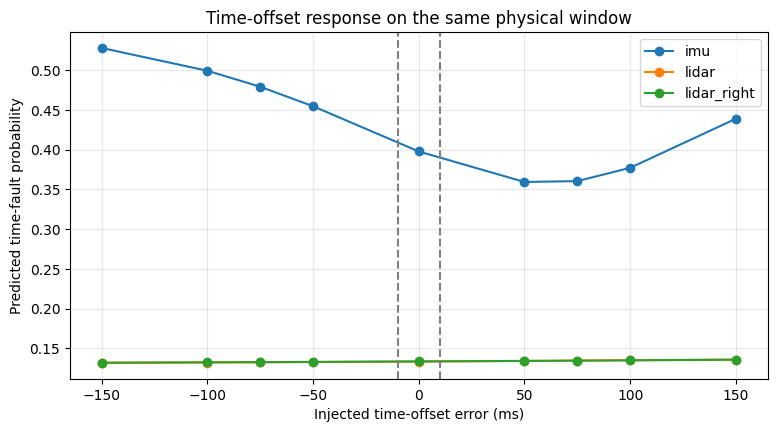

In [32]:
import copy

time_probe_model = PooledCalibrationClassifierModel(model_config).to(
    device=DEVICE, dtype=MODEL_DTYPE
)

checkpoint = torch.load(
    STOCHASTIC_FINAL_PATH,
    map_location="cpu",
    weights_only=True,
)
time_probe_model.load_state_dict(checkpoint["model_state_dict"], strict=True)
time_probe_model.eval()

raw = window_batch_to(
    collate_windows([val_dataset[0]]),
    DEVICE,
    dtype=MODEL_DTYPE,
)
physical = fixed_seeded_physical(raw, VALIDATION_AUG_SEED + 451)

base_case = sample_fault_cases(
    1, np.random.default_rng(12345), balanced=True
)[0]

offsets_ms = [-150, -100, -75, -50, 0, 50, 75, 100, 150]
rows = []

for sensor in CALIBRATION_KEYS:
    cases = []

    for tau_ms in offsets_ms:
        case = copy.deepcopy(base_case)
        case["tau_ms"][sensor] = float(tau_ms)
        case["fault_count"] = int(tau_ms != 0)
        case["fault_mode"] = "time_only" if tau_ms != 0 else "none"
        case["injected_keys"] = (sensor,) if tau_ms != 0 else ()
        cases.append(case)

    with torch.inference_mode():
        tokens = tokenize_window(faulted_window_from_cases(physical, cases))
        probabilities = time_probe_model(tokens).logits.sigmoid()
        sensor_index = CALIBRATION_KEYS.index(sensor)
        scores = probabilities[:, sensor_index, 2].cpu().numpy()

    for tau_ms, probability in zip(offsets_ms, scores):
        rows.append({
            "sensor": sensor,
            "tau_ms": tau_ms,
            "p_time_fault": probability,
        })

time_probe_df = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(9, 4.5))

for sensor, group in time_probe_df.groupby("sensor"):
    ax.plot(group.tau_ms, group.p_time_fault, marker="o", label=sensor)

ax.axvline(-GT_TAU_TOL_MS, color="gray", linestyle="--")
ax.axvline(GT_TAU_TOL_MS, color="gray", linestyle="--")
ax.set(
    xlabel="Injected time-offset error (ms)",
    ylabel="Predicted time-fault probability",
    title="Time-offset response on the same physical window",
)
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## 10. Full-training optimizer, scheduler, and checkpoint state

The full training run uses independently initialized weights. In joint mode, `best.pt` is selected by **validation joint F1**. In time-only mode, the checkpoint is selected by **validation time average precision (AP)**, which still detects useful ranking when all time probabilities are below 0.5.

In [11]:
# Construct AFTER the stochastic checkpoint test. Never inherit its optimizer or parameters.
if RUN_FULL_TRAINING and REQUIRE_STOCHASTIC_IMPROVEMENT and STOCHASTIC_DIAGNOSTIC_PASSED is not True and not RESUME_TRAINING:
    raise RuntimeError('Stochastic improvement gate did not pass; set REQUIRE_STOCHASTIC_IMPROVEMENT=False to continue.')
optimizer = make_optimizer(model)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=LR_REDUCTION_FACTOR, patience=LR_PATIENCE_EPOCHS)
start_epoch, global_step, best_validation_score = 0, 0, -1.0
if RESUME_TRAINING:
    if not LAST_CHECKPOINT_PATH.is_file():
        raise FileNotFoundError(f'Resume checkpoint missing: {LAST_CHECKPOINT_PATH}')
    prior_config_path = RUN_DIR / 'experiment_config.json'
    if not prior_config_path.is_file():
        raise FileNotFoundError(f'Resume requires the original configuration: {prior_config_path}')
    prior_settings = json.loads(prior_config_path.read_text(encoding='utf-8'))
    current_signature = {'objective': TRAINING_OBJECTIVE, 'k_probabilities': list(K_PROBABILITIES), 'fault_modes': list(FAULT_MODES),
                         'time_bins_ms': [list(pair) for pair in TIME_BINS_MS], 'loss_weights': [JOINT_LOSS_WEIGHT, ROTATION_LOSS_WEIGHT, TIME_LOSS_WEIGHT],
                         'time_pos_weight': TIME_POS_WEIGHT, 'majority': MAJORITY_UNRELIABLE_WHEN_MOST_PERTURBED}
    if prior_settings.get('training_signature') != current_signature:
        raise ValueError('Cannot resume: objective, K probabilities, modes, loss or labels differ from the saved run.')
    info = load_training_checkpoint(LAST_CHECKPOINT_PATH, model=model, optimizer=optimizer, scheduler=scheduler, map_location=DEVICE,
                                    restore_rng_state=True, generators={'train_shuffle': train_shuffle_generator})
    start_epoch = int(info.get('epoch', 0))
    global_step = int(info.get('global_step', 0))
    best_validation_score = float(info.get('extra_state', {}).get('best_validation_score', -1.0))
    print('Resumed CLASSIFIER ONLY:', LAST_CHECKPOINT_PATH, 'epoch:', start_epoch)
else:
    if RUN_FULL_TRAINING and (BEST_CHECKPOINT_PATH.exists() or LAST_CHECKPOINT_PATH.exists()):
        raise FileExistsError(f'New scratch run must not overwrite checkpoints in {RUN_DIR}; change RUN_NAME or enable RESUME_TRAINING.')
    print('Full-training optimizer starts from random scratch model state restored after stochastic preflight.')

experiment_settings = {
    'run_name': RUN_NAME, 'scratch_all_modules': not RESUME_TRAINING, 'architecture': 'PooledCalibrationClassifierModel_00227_dimensions',
    'training_signature': {'objective': TRAINING_OBJECTIVE, 'k_probabilities': list(K_PROBABILITIES), 'fault_modes': list(FAULT_MODES),
                           'time_bins_ms': [list(pair) for pair in TIME_BINS_MS], 'loss_weights': [JOINT_LOSS_WEIGHT, ROTATION_LOSS_WEIGHT, TIME_LOSS_WEIGHT],
                           'time_pos_weight': TIME_POS_WEIGHT, 'majority': MAJORITY_UNRELIABLE_WHEN_MOST_PERTURBED},
    'checkpoint_task': CHECKPOINT_TASK, 'checkpoint_metric': CHECKPOINT_METRIC,
    'train_sequences': TRAIN_NAMES, 'validation_sequences': VAL_NAMES, 'test_sequences': TEST_NAMES,
    'operational_tolerances': {'rotation_deg': GT_ROT_TOL_DEG, 'time_ms': GT_TAU_TOL_MS},
    'learning_rates': {g['name']:g['lr'] for g in optimizer.param_groups},
    'train_cases_per_window': TRAIN_CASES_PER_PHYSICAL, 'validation_monitor_windows': len(monitor_val_indices),
    'model_dims': {'d_model':D_MODEL, 'layers':NUM_TRANSFORMER_LAYERS, 'heads':N_HEADS, 'shared_dim':SHARED_FEATURE_DIM},
    'rotation_bins_deg': ROTATION_BINS_DEG,
}
(RUN_DIR / 'experiment_config.json').write_text(json.dumps(experiment_settings, indent=2), encoding='utf-8')
print('Optimizer groups:', [(group['name'], group['lr'], len(group['params'])) for group in optimizer.param_groups])

Full-training optimizer starts from random scratch model state restored after stochastic preflight.
Optimizer groups: [('transformer', 1e-05, 147), ('pooler', 2e-05, 5), ('mlp_body', 0.0002, 6), ('classifier_head', 0.0004, 10)]


## 11. Full stochastic training epoch runner and fixed validation

In [19]:
def run_classifier_train_epoch(epoch, *, global_step):
    k_counts = np.zeros(4, dtype=np.int64)
    time_positives, time_total = 0, 0
    sums = {'loss_total':0.0, 'loss_joint':0.0, 'loss_rotation':0.0, 'loss_time':0.0, 'gradient_norm':0.0}
    total_cases, updates = 0, 0
    start_time = time.monotonic()
    for batch_idx, raw_cpu in enumerate(train_loader):
        profile_this_batch = PROFILE_FIRST_TRAIN_BATCH and epoch == start_epoch and batch_idx == 0
        if profile_this_batch:
            if DEVICE.type == 'cuda':
                torch.cuda.synchronize()
            physical_start = time.perf_counter()
        raw = window_batch_to(raw_cpu, DEVICE, dtype=MODEL_DTYPE)
        physical = fixed_seeded_physical(raw, TRAIN_AUG_SEED + epoch * 1_000_003 + batch_idx * 1009)
        if profile_this_batch:
            if DEVICE.type == 'cuda':
                torch.cuda.synchronize()
            physical_prep_seconds = time.perf_counter() - physical_start
        rng = np.random.default_rng(RANDOM_SEED + epoch * 1_000_003 + batch_idx * 7919)
        cases = sample_fault_cases(next(iter(raw.current_calibration.values())).transform.shape[0], rng, exhaustive=False)
        k_counts += np.bincount([item['fault_count'] for item in cases], minlength=4)
        time_positives += sum(abs(item['tau_ms'][key]) > GT_TAU_TOL_MS for item in cases for key in CALIBRATION_KEYS)
        time_total += len(cases) * len(CALIBRATION_KEYS)
        result = train_case_batch(model, optimizer, physical, cases, microbatch_size=MODEL_MICROBATCH_SIZE, profile=profile_this_batch)
        if profile_this_batch:
            print(f'FIRST TRAIN UPDATE: {len(cases)} cases from {len(raw.current_calibration[CALIBRATION_KEYS[0]].transform)} physical windows; '
                  f'{result["profile_microbatches"]} GPU forward/backward microbatches of at most {MODEL_MICROBATCH_SIZE} cases.')
            print(f'Physical augmentation + CUDA transfer: {physical_prep_seconds:.3f} s (excludes DataLoader retrieval)')
            print('First GPU token tensor:', result['profile_first_token_shape'], '(batch, padded tokens, token features)')
            print('First update phase times (s):', {k:round(v, 3) for k,v in result['profile_times'].items()})
            if DEVICE.type == 'cuda':
                print(f'CUDA peak memory: allocated {result["profile_peak_allocated_gib"]:.2f} GiB, '
                      f'reserved {result["profile_peak_reserved_gib"]:.2f} GiB, '
                      f'device total {result["profile_device_total_gib"]:.2f} GiB')
        for key in sums:
            sums[key] += result[key] * len(cases)
        total_cases += len(cases)
        updates += 1
        global_step += 1
        if (batch_idx + 1) % PRINT_EVERY_BATCHES == 0:
            print(f'  update={batch_idx+1}/{len(train_loader)} loss={sums["loss_total"]/total_cases:.4f} grad={result["gradient_norm"]:.3f} elapsed={time.monotonic()-start_time:.1f}s', flush=True)
    if not total_cases:
        raise RuntimeError('No training cases were generated.')
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    averages = {key: value / total_cases for key, value in sums.items()}
    averages.update({f'k{k}_fraction': k_counts[k] / k_counts.sum() for k in FAULT_COUNTS})
    averages['time_positive_fraction'] = time_positives / time_total
    return averages, global_step


def run_monitor_validation():
    monitor_df, monitor_loss = evaluate_cases(model, val_dataset, monitor_val_indices, split_seed=VALIDATION_AUG_SEED, exhaustive=False)
    summary = score_metrics(monitor_df, DEFAULT_DECISION_THRESHOLD, task=CHECKPOINT_TASK)
    parts = {name:score_metrics(monitor_df, DEFAULT_DECISION_THRESHOLD, task=name) for name in ('joint', 'rotation', 'time')}
    
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    selection_score = summary[CHECKPOINT_METRIC]
    return {'loss': monitor_loss, 'precision': summary['precision'], 'recall': summary['recall'], 'f1': summary['f1'],
            'selection_score': selection_score, 'joint_f1': parts['joint']['f1'],
            'rotation_f1': parts['rotation']['f1'], 'time_f1': parts['time']['f1'],
            'rotation_auroc': parts['rotation']['auroc'], 'time_auroc': parts['time']['auroc'],
            'rotation_ap': parts['rotation']['average_precision'], 'time_ap': parts['time']['average_precision'],
            'time_prevalence': parts['time']['prevalence']}, monitor_df

print('Full-training epoch and fixed monitor validation runners ready.')

Full-training epoch and fixed monitor validation runners ready.


## 12. Full training, best/last classifier checkpoints

The training sampler draws K independently with the configured probabilities. Fixed validation is deliberately balanced across K. In joint mode, the best checkpoint uses **joint F1 at 0.5**. In time-only mode, it uses **time average precision** so predictions below 0.5 still have a meaningful training-selection signal. The final validation probability threshold is chosen later, without using test data.

In [20]:
if DEVICE.type == 'cuda':
    torch.cuda.empty_cache()

In [21]:
training_history = []
if RUN_FULL_TRAINING:
    for epoch in range(start_epoch, NUM_EPOCHS):
        print(f'\n{"="*90}\nEpoch {epoch+1}/{NUM_EPOCHS}')
        train_results, global_step = run_classifier_train_epoch(epoch, global_step=global_step)
        validation_results, monitor_df = run_monitor_validation()

        # Use K=0 and K=1 for checkpoint selection.
        selection_df = monitor_df[monitor_df["fault_count"].isin((0, 1))]

        if selection_df.empty:
            raise ValueError("No K=0 or K=1 validation cases.")

        # Calculate threshold-independent metrics for each classifier head.
        selection_ap = {}

        for task in ("joint", "rotation", "time"):
            metrics = score_metrics(selection_df, 0.5, task=task)
            selection_ap[task] = float(metrics["average_precision"])

            validation_results[f"selection_{task}_ap"] = selection_ap[task]

        # Select the appropriate objective automatically.
        if TRAINING_OBJECTIVE == "time_only":
            selection_score = selection_ap["time"]

        elif TRAINING_OBJECTIVE == "rotation_only":
            selection_score = selection_ap["rotation"]

        elif TRAINING_OBJECTIVE == "joint":
            selection_score = (
                0.2 * selection_ap["joint"]
                + 0.4 * selection_ap["rotation"]
                + 0.4 * selection_ap["time"]
            )

        else:
            raise ValueError(f"Unsupported training objective: {TRAINING_OBJECTIVE}")

        if not np.isfinite(selection_score):
            raise ValueError(f"Invalid checkpoint selection score: {selection_ap}")

        validation_results["selection_score"] = float(selection_score)

        # Keep the scheduler based on validation BCE.
        scheduler.step(validation_results["loss"])
        
        row = {'epoch':epoch+1, 'global_step':global_step,
               **{f'train_{key}':value for key, value in train_results.items()},
               **{f'val_{key}':value for key,value in validation_results.items()},
               **{f'lr_{group["name"]}':group['lr'] for group in optimizer.param_groups}}
        training_history.append(row)
        pd.DataFrame(training_history).to_csv(RUN_DIR / 'training_history_session.csv', index=False)
        print(f'train BCE={train_results["loss_total"]:.4f} | val BCE={validation_results["loss"]:.4f} '
              f'| P={validation_results["precision"]:.3f} R={validation_results["recall"]:.3f} F1={validation_results["f1"]:.3f} '
              f'| jointF1={validation_results["joint_f1"]:.3f} rotF1={validation_results["rotation_f1"]:.3f} '
              f'timeF1={validation_results["time_f1"]:.3f} timeAP={validation_results["time_ap"]:.3f} '
              f'timeAUC={validation_results["time_auroc"]:.3f} selection={validation_results["selection_score"]:.3f}')
        # print('Train K fractions:', {k: round(train_results[f'k{k}_fraction'], 3) for k in FAULT_COUNTS},
        #       '| time positive fraction:', round(train_results['time_positive_fraction'], 3))
        print('LR:', {g['name']:f'{g["lr"]:.2e}' for g in optimizer.param_groups})
        extra_state = {'best_validation_score':max(best_validation_score, float(validation_results['selection_score'])), 'checkpoint_task':CHECKPOINT_TASK,
                       'operational_time_ms':GT_TAU_TOL_MS, 'majority_unreliable_when_most_perturbed':MAJORITY_UNRELIABLE_WHEN_MOST_PERTURBED, 'scratch_classifier':True}
        if np.isfinite(validation_results['selection_score']) and validation_results['selection_score'] > best_validation_score:
            best_validation_score = float(validation_results['selection_score'])
            save_training_checkpoint(BEST_CHECKPOINT_PATH, model=model, optimizer=optimizer, scheduler=scheduler, epoch=epoch+1, global_step=global_step,
                                     metrics=validation_results, generators={'train_shuffle':train_shuffle_generator}, extra_state=extra_state)
            print(
                f"Saved best.pt | objective={TRAINING_OBJECTIVE} "
                f"selection AP={best_validation_score:.4f}"
            )
        if (epoch + 1) % CHECKPOINT_EVERY_EPOCHS == 0 or epoch + 1 == NUM_EPOCHS:
            save_training_checkpoint(LAST_CHECKPOINT_PATH, model=model, optimizer=optimizer, scheduler=scheduler, epoch=epoch+1, global_step=global_step,
                                     metrics=validation_results, generators={'train_shuffle':train_shuffle_generator}, extra_state=extra_state)
            print('Saved last.pt.')
else:
    print('Full training disabled. Existing classifier checkpoint may still be evaluated if selected below.')



Epoch 1/200
FIRST TRAIN UPDATE: 256 cases from 64 physical windows; 8 GPU forward/backward microbatches of at most 32 cases.
Physical augmentation + CUDA transfer: 1.406 s (excludes DataLoader retrieval)
First GPU token tensor: (32, 1100, 8) (batch, padded tokens, token features)
First update phase times (s): {'preprocess': 0.231, 'forward_loss': 2.13, 'backward': 5.506, 'optimizer': 0.013}
CUDA peak memory: allocated 3.77 GiB, reserved 3.98 GiB, device total 8.00 GiB
train BCE=1.4600 | val BCE=1.6895 | P=nan R=0.000 F1=0.000 | jointF1=0.000 rotF1=0.000 timeF1=0.000 timeAP=0.405 timeAUC=0.552 selection=0.165
LR: {'transformer': '1.00e-05', 'pooler': '2.00e-05', 'mlp_body': '2.00e-04', 'classifier_head': '4.00e-04'}
Saved best.pt | objective=joint selection AP=0.1646

Epoch 2/200
train BCE=1.4592 | val BCE=1.6790 | P=nan R=0.000 F1=0.000 | jointF1=0.000 rotF1=0.000 timeF1=0.000 timeAP=0.397 timeAUC=0.538 selection=0.165
LR: {'transformer': '1.00e-05', 'pooler': '2.00e-05', 'mlp_body': 

KeyboardInterrupt: 

## 13. Training curves: loss, per-head validation metrics and independent learning rates

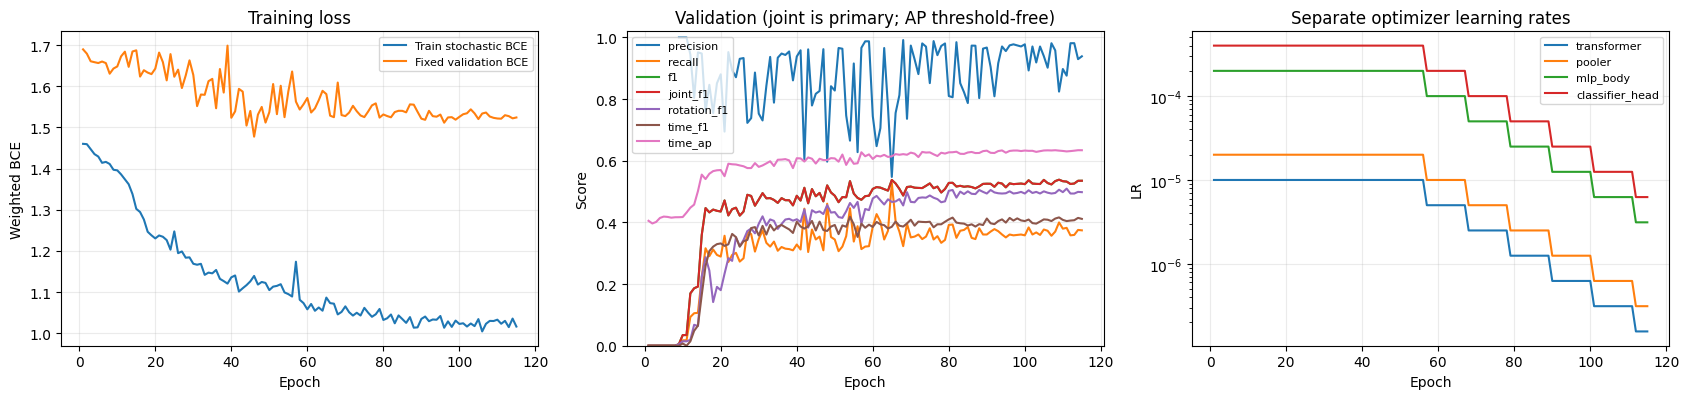

In [22]:
if training_history:
    h = pd.DataFrame(training_history)
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.1))
    axes[0].plot(h.epoch, h.train_loss_total, label='Train stochastic BCE')
    axes[0].plot(h.epoch, h.val_loss, label='Fixed validation BCE')
    axes[0].set(title='Training loss', xlabel='Epoch', ylabel='Weighted BCE')
    for name in ('precision', 'recall', 'f1', 'joint_f1', 'rotation_f1', 'time_f1', 'time_ap'):
        axes[1].plot(h.epoch, h[f'val_{name}'], label=name)
    axes[1].set(title=f'Validation ({CHECKPOINT_TASK} is primary; AP threshold-free)', xlabel='Epoch', ylabel='Score', ylim=(0, 1.02))
    for name in ('transformer', 'pooler', 'mlp_body', 'classifier_head'):
        axes[2].plot(h.epoch, h[f'lr_{name}'], label=name)
    axes[2].set(title='Separate optimizer learning rates', xlabel='Epoch', ylabel='LR', yscale='log')
    for ax in axes:
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)
    fig.tight_layout()
    if SAVE_PLOTS: fig.savefig(RUN_DIR / 'training_curves.png', dpi=PLOT_DPI, bbox_inches='tight')
    if SHOW_PLOTS: plt.show()
    else: plt.close(fig)
else:
    print('No history from this session. If resuming, older history is stored in earlier session CSVs/checkpoints.')

## 14. Load the best classifier checkpoint for all subsequent evaluations

`best.pt` belongs to this same scratch classification run; in `time_only` mode it was selected by time AP, not the joint head.

In [23]:
if RUN_DETAILED_EVALUATION:
    if not BEST_CHECKPOINT_PATH.is_file():
        raise FileNotFoundError(f'No classifier best.pt available: {BEST_CHECKPOINT_PATH}')
    checkpoint = load_training_checkpoint(BEST_CHECKPOINT_PATH, model=model, map_location=DEVICE, restore_rng_state=False)
    model.eval()
    print('Loaded classifier checkpoint:', BEST_CHECKPOINT_PATH, '| epoch:', checkpoint.get('epoch'))

Loaded classifier checkpoint: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_classifier_005.1_joint_weighted_k/best.pt | epoch: 114


## 15. Exhaustive held-out validation: choose separate probability thresholds for each head

Evaluate each K and active fault mode on held-out validation. Choose a probability threshold **separately** for joint, rotation and time classification by validation F1, without using test data. In `time_only` mode, the primary threshold and plots use `prob_time/target_time`. This prevents the old error of selecting a joint threshold and applying it to the time head.

Detailed validation BCE: 1.6715807310370512
Validation joint threshold=0.10; best F1=0.764; AUROC=0.731; AP=0.817; prevalence=0.575
Validation rotation threshold=0.25; best F1=0.565; AUROC=0.729; AP=0.700; prevalence=0.349
Validation time threshold=0.05; best F1=0.621; AUROC=0.685; AP=0.652; prevalence=0.400
Selected primary joint threshold: 0.1


,threshold,precision,recall,f1,auroc,average_precision,tp,fp,fn,tn
0,0.10,0.644,0.941,0.764,0.731,0.817,5585,3094,348,1293
1,0.05,0.603,0.977,0.745,0.731,0.817,5795,3820,138,567
2,0.15,0.665,0.817,0.733,0.731,0.817,4848,2440,1085,1947
3,0.20,0.680,0.679,0.679,0.731,0.817,4027,1896,1906,2491
4,0.25,0.695,0.608,0.649,0.731,0.817,3608,1583,2325,2804
5,0.30,0.710,0.561,0.627,0.731,0.817,3330,1359,2603,3028
6,0.35,0.743,0.514,0.607,0.731,0.817,3047,1053,2886,3334
7,0.40,0.814,0.455,0.583,0.731,0.817,2698,617,3235,3770
8,0.45,0.883,0.414,0.564,0.731,0.817,2457,326,3476,4061
9,0.50,0.948,0.383,0.545,0.731,0.817,2270,124,3663,4263



DETAILED VALIDATION | task=joint | 3,440 cases | 10,320 sensor classifications | threshold=0.10


,group,value,n,tp,fp,fn,tn,precision,recall,f1
0,all,all,10320,5585,3094,348,1293,0.644,0.941,0.764
1,K,0,1032,0,749,0,283,0.000,NaN,0.000
2,K,1,3096,969,1466,22,639,0.398,0.978,0.566
3,K,2,3096,1865,793,113,325,0.702,0.943,0.805
4,K,3,3096,2751,86,213,46,0.970,0.928,0.948


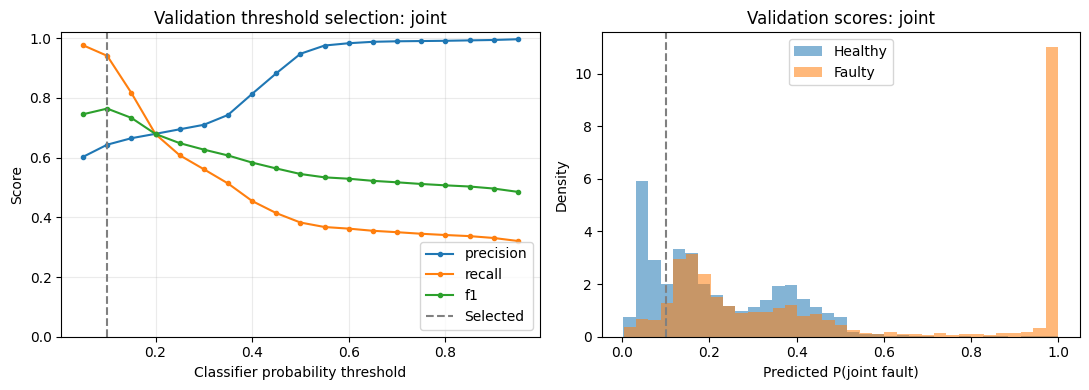

In [24]:
VALIDATION_SCORES_PATH = RUN_DIR / 'detailed_validation_scores.csv'
if RUN_DETAILED_EVALUATION:
    validation_df, detailed_validation_bce = evaluate_cases(model, val_dataset, detailed_val_indices, split_seed=VALIDATION_AUG_SEED + 801,
                                                            exhaustive=True, physical_batch_size=EVALUATION_PHYSICAL_BATCH_SIZE)
    validation_df.to_csv(VALIDATION_SCORES_PATH, index=False)
    print('Detailed validation BCE:', detailed_validation_bce)
else:
    validation_df = pd.read_csv(VALIDATION_SCORES_PATH)

threshold_sweeps = []
SELECTED_THRESHOLDS = {}
for task in ('joint', 'rotation', 'time'):
    task_df = pd.DataFrame([{'task': task, 'threshold': float(t), **score_metrics(validation_df, float(t), task=task)} for t in PROBABILITY_THRESHOLDS])
    task_df = task_df.sort_values(['f1', 'recall', 'threshold'], ascending=[False, False, True])
    SELECTED_THRESHOLDS[task] = float(task_df.iloc[0].threshold)
    threshold_sweeps.append(task_df)
    print(f'Validation {task} threshold={SELECTED_THRESHOLDS[task]:.2f}; best F1={task_df.iloc[0].f1:.3f}; AUROC={task_df.iloc[0].auroc:.3f}; AP={task_df.iloc[0].average_precision:.3f}; prevalence={task_df.iloc[0].prevalence:.3f}')
threshold_df = pd.concat(threshold_sweeps, ignore_index=True)
threshold_df.to_csv(RUN_DIR / 'validation_probability_threshold_sweep.csv', index=False)
(RUN_DIR / 'selected_probability_thresholds.json').write_text(json.dumps(SELECTED_THRESHOLDS, indent=2), encoding='utf-8')
SELECTED_PROBABILITY_THRESHOLD = SELECTED_THRESHOLDS[CHECKPOINT_TASK]
print(f'Selected primary {CHECKPOINT_TASK} threshold:', SELECTED_PROBABILITY_THRESHOLD)
display(threshold_df[threshold_df.task == CHECKPOINT_TASK][['threshold', 'precision', 'recall', 'f1', 'auroc', 'average_precision', 'tp', 'fp', 'fn', 'tn']].head(10).round(3))
validation_summary = log_case_report(validation_df, 'DETAILED VALIDATION', threshold=SELECTED_PROBABILITY_THRESHOLD)
validation_summary.to_csv(RUN_DIR / 'detailed_validation_metrics.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
by_threshold = threshold_df[threshold_df.task == CHECKPOINT_TASK].sort_values('threshold')
for metric in ('precision', 'recall', 'f1'):
    axes[0].plot(by_threshold.threshold, by_threshold[metric], marker='.', label=metric)
axes[0].axvline(SELECTED_PROBABILITY_THRESHOLD, color='grey', linestyle='--', label='Selected')
axes[0].set(xlabel='Classifier probability threshold', ylabel='Score', title=f'Validation threshold selection: {CHECKPOINT_TASK}', ylim=(0, 1.02))
axes[0].grid(alpha=0.25)
axes[0].legend()
for truth, label in ((0, 'Healthy'), (1, 'Faulty')):
    subset = validation_df[validation_df[f'target_{CHECKPOINT_TASK}'] == truth]
    axes[1].hist(subset[f'prob_{CHECKPOINT_TASK}'], bins=35, alpha=0.55, density=True, label=label)
axes[1].axvline(SELECTED_PROBABILITY_THRESHOLD, color='grey', linestyle='--')
axes[1].set(xlabel=f'Predicted P({CHECKPOINT_TASK} fault)', ylabel='Density', title=f'Validation scores: {CHECKPOINT_TASK}')
axes[1].legend()
fig.tight_layout()
if SAVE_PLOTS: fig.savefig(RUN_DIR / 'validation_probability_diagnostics.png', dpi=PLOT_DPI, bbox_inches='tight')
if SHOW_PLOTS: plt.show()
else: plt.close(fig)

## 16. Untouched test evaluation: each head uses its own validation-selected threshold

Test K=0..3 and sensor/mode breakdowns with probability thresholds fixed entirely on validation. Metrics from heads whose loss weight is zero are displayed for completeness, **not as trained capabilities**.

In [25]:
TEST_SCORES_PATH = RUN_DIR / 'detailed_test_scores.csv'
if RUN_TEST_EVALUATION:
    test_df, detailed_test_bce = evaluate_cases(model, test_dataset, detailed_test_indices, split_seed=TEST_AUG_SEED + 801,
                                                exhaustive=True, physical_batch_size=EVALUATION_PHYSICAL_BATCH_SIZE)
    test_df.to_csv(TEST_SCORES_PATH, index=False)
    print('Detailed test BCE:', detailed_test_bce)
else:
    test_df = pd.read_csv(TEST_SCORES_PATH)

metrics_all_tasks = []
for task in ('joint','rotation','time'):
    report = grouped_metrics(test_df, SELECTED_THRESHOLDS[task], task=task)
    metrics_all_tasks.append(report)
    print(f'\n{task.upper()} | validation-selected threshold={SELECTED_THRESHOLDS[task]:.2f} | optimized loss weight={dict(joint=JOINT_LOSS_WEIGHT, rotation=ROTATION_LOSS_WEIGHT, time=TIME_LOSS_WEIGHT)[task]}')
    display(report[report.group.isin(['all','K'])][['group','value','n','tp','fp','fn','tn','precision','recall','f1','specificity']].round(3))
test_report = pd.concat(metrics_all_tasks, ignore_index=True)
test_report.to_csv(RUN_DIR / 'detailed_test_metrics.csv', index=False)
print('Sensor and fault mode breakdown:')
display(test_report[(test_report.task == CHECKPOINT_TASK) & test_report.group.isin(['sensor','fault_mode','K_sensor'])].round(3))
print('Saved:', TEST_SCORES_PATH, '|', RUN_DIR / 'detailed_test_metrics.csv')

Detailed test BCE: 1.6490296249389649

JOINT | validation-selected threshold=0.10 | optimized loss weight=1.0


,group,value,n,tp,fp,fn,tn,precision,recall,f1,specificity
0,all,all,15000,8159,4303,473,2065,0.655,0.945,0.774,0.324
1,K,0,1500,0,1043,0,457,0.000,NaN,0.000,0.305
2,K,1,4500,1400,2054,31,1015,0.405,0.978,0.573,0.331
3,K,2,4500,2742,1103,142,513,0.713,0.951,0.815,0.317
4,K,3,4500,4017,103,300,80,0.975,0.931,0.952,0.437



ROTATION | validation-selected threshold=0.25 | optimized loss weight=0.5


,group,value,n,tp,fp,fn,tn,precision,recall,f1,specificity
0,all,all,15000,2468,897,2777,8858,0.733,0.471,0.573,0.908
1,K,0,1500,0,195,0,1305,0.000,NaN,0.000,0.870
2,K,1,4500,573,323,296,3308,0.640,0.659,0.649,0.911
3,K,2,4500,858,198,881,2563,0.812,0.493,0.614,0.928
4,K,3,4500,1037,181,1600,1682,0.851,0.393,0.538,0.903



TIME | validation-selected threshold=0.05 | optimized loss weight=1.0


,group,value,n,tp,fp,fn,tn,precision,recall,f1,specificity
0,all,all,15000,5846,6675,154,2325,0.467,0.974,0.631,0.258
1,K,0,1500,0,1033,0,467,0.000,NaN,0.000,0.311
2,K,1,4500,993,2459,7,1041,0.288,0.993,0.446,0.297
3,K,2,4500,1953,1927,47,573,0.503,0.976,0.664,0.229
4,K,3,4500,2900,1256,100,244,0.698,0.967,0.811,0.163


Sensor and fault mode breakdown:


,group,value,task,threshold,n,tp,fp,fn,tn,precision,recall,f1,specificity,accuracy,prevalence,prob_mean_positive,prob_mean_negative,auroc,average_precision
5,sensor,imu,joint,0.1,5000,2647,273,239,1841,0.907,0.917,0.912,0.871,0.898,0.577,0.840,0.073,0.957,0.976
6,sensor,lidar,joint,0.1,5000,2750,2022,125,103,0.576,0.957,0.719,0.048,0.571,0.575,0.340,0.282,0.512,0.656
7,sensor,lidar_right,joint,0.1,5000,2762,2008,109,121,0.579,0.962,0.723,0.057,0.577,0.574,0.340,0.282,0.512,0.653
8,fault_mode,none,joint,0.1,1500,0,1043,0,457,0.000,NaN,0.000,0.305,0.305,0.000,NaN,0.290,NaN,NaN
9,fault_mode,rotation_only,joint,0.1,4500,2354,1167,278,701,0.669,0.894,0.765,0.375,0.679,0.585,0.508,0.187,0.758,0.845
10,fault_mode,time_only,joint,0.1,4500,2944,1102,56,398,0.728,0.981,0.836,0.265,0.743,0.667,0.475,0.205,0.738,0.860
11,fault_mode,both,joint,0.1,4500,2861,991,139,509,0.743,0.954,0.835,0.339,0.749,0.667,0.539,0.174,0.800,0.899
12,K_sensor,0|imu,joint,0.1,500,0,43,0,457,0.000,NaN,0.000,0.914,0.914,0.000,NaN,0.062,NaN,NaN
13,K_sensor,0|lidar,joint,0.1,500,0,500,0,0,0.000,NaN,0.000,0.000,0.000,0.000,NaN,0.405,NaN,NaN
14,K_sensor,0|lidar_right,joint,0.1,500,0,500,0,0,0.000,NaN,0.000,0.000,0.000,0.000,NaN,0.403,NaN,NaN


Saved: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_classifier_005.1_joint_weighted_k/detailed_test_scores.csv | /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_classifier_005.1_joint_weighted_k/detailed_test_metrics.csv


## 17. Visualization: per-K metrics, per-sensor heatmap and confusion matrices

The plotted head is `CHECKPOINT_TASK` (joint in joint training; time in time-only training). K-balanced test coverage is not weighted to the K=1-heavy training distribution.

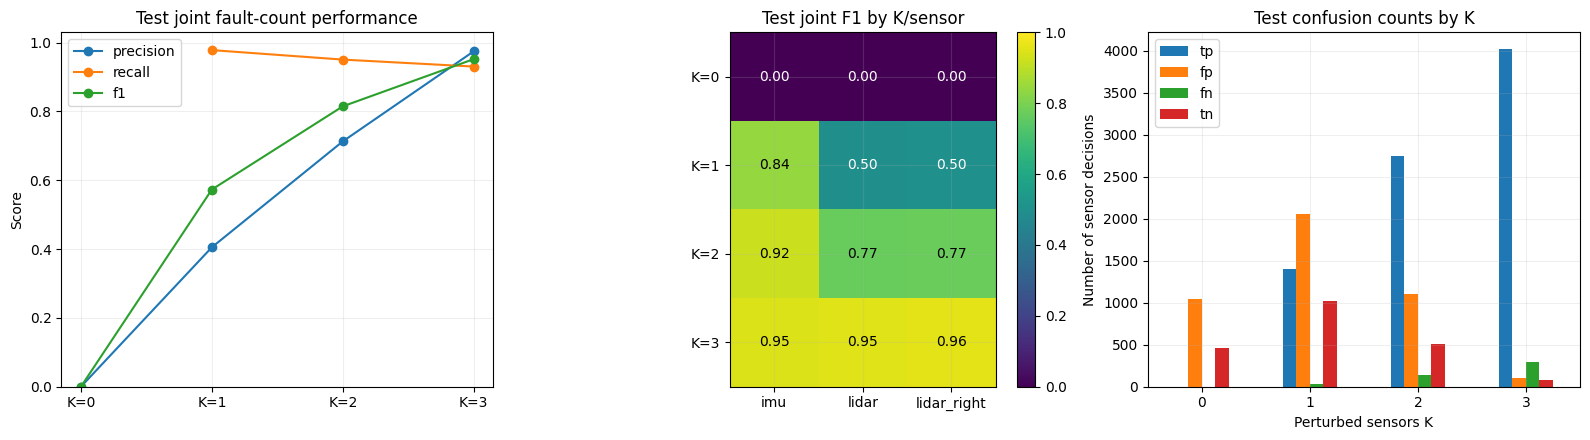

In [26]:
selected = test_report[test_report.task == CHECKPOINT_TASK]
per_k = selected[selected.group == 'K'].set_index('value')
per_k_sensor = selected[selected.group == 'K_sensor'].copy()
per_k_sensor[['K','sensor_key']] = per_k_sensor.value.str.split('|', expand=True)
heatmap = per_k_sensor.pivot(index='K', columns='sensor_key', values='f1').reindex(index=['0','1','2','3'], columns=list(CALIBRATION_KEYS))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
labels = ['K=0', 'K=1', 'K=2', 'K=3']
x = np.arange(4)
for name in ('precision', 'recall', 'f1'):
    axes[0].plot(x, per_k.reindex(['0','1','2','3'])[name], marker='o', label=name)
axes[0].set(xticks=x, xticklabels=labels, title=f'Test {CHECKPOINT_TASK} fault-count performance', ylabel='Score', ylim=(0,1.03))
axes[0].legend()
im = axes[1].imshow(heatmap.to_numpy(float), vmin=0, vmax=1, cmap='viridis')
axes[1].set(xticks=range(3), xticklabels=CALIBRATION_KEYS, yticks=range(4), yticklabels=labels, title=f'Test {CHECKPOINT_TASK} F1 by K/sensor')
for (i,j), value in np.ndenumerate(heatmap.to_numpy(float)):
    if np.isfinite(value):
        axes[1].text(j, i, f'{value:.2f}', ha='center', va='center', color='white' if value < 0.7 else 'black')
fig.colorbar(im, ax=axes[1], fraction=0.045)
conf = per_k.reindex(['0','1','2','3'])[['tp','fp','fn','tn']]
conf.plot(kind='bar', ax=axes[2], rot=0)
axes[2].set(title='Test confusion counts by K', xlabel='Perturbed sensors K', ylabel='Number of sensor decisions')
for ax in axes:
    ax.grid(alpha=0.2)
fig.tight_layout()
if SAVE_PLOTS: fig.savefig(RUN_DIR / 'test_by_k_and_sensor.png', dpi=PLOT_DPI, bbox_inches='tight')
if SHOW_PLOTS: plt.show()
else: plt.close(fig)

## 18. Detection rate versus actual rotation and time fault magnitude

The left panel uses the **rotation** head and rotation tolerance; the right panel uses the **time** head and time tolerance. A near-100% joint alarm rate no longer disguises an untrained time head. In time-only mode, the rotation panel is a non-trained reference, not an intended result.

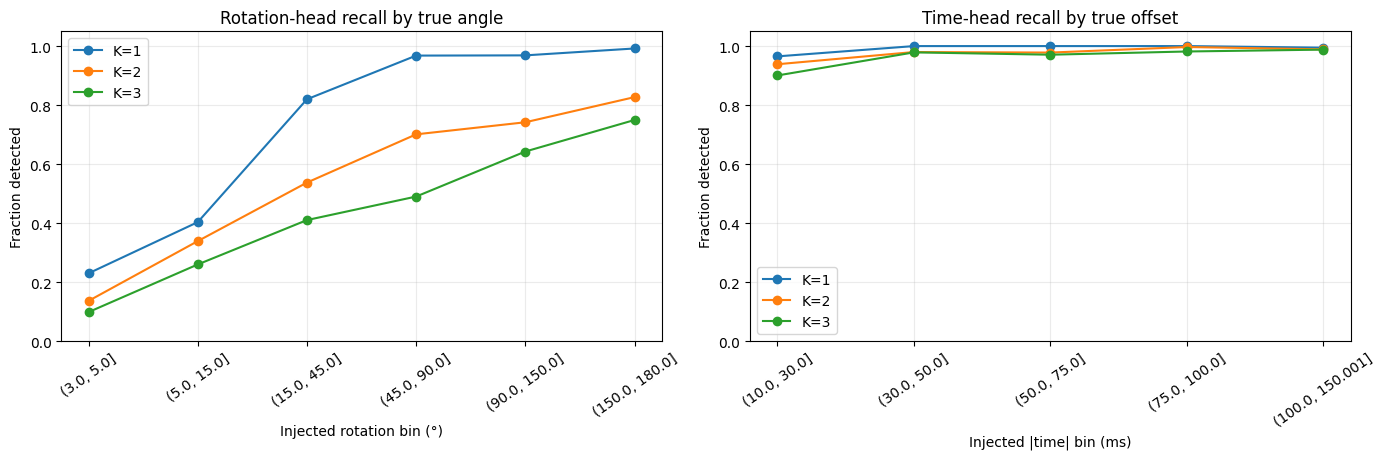

In [27]:
rotation_bins = (-0.01, 0.01, 1., 3., 5., 15., 45., 90., 150., 180.)
time_bins = (-0.01, 0.01, 10., 30., 50., 75., 100., 150.001)
plot_df = test_df.copy()
plot_df['detected_rotation'] = plot_df.prob_rotation >= SELECTED_THRESHOLDS['rotation']
plot_df['detected_time'] = plot_df.prob_time >= SELECTED_THRESHOLDS['time']
plot_df['rotation_bin'] = pd.cut(plot_df.true_rotation_deg, bins=rotation_bins)
plot_df['time_bin'] = pd.cut(plot_df.true_tau_ms.abs(), bins=time_bins)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.7))
for k in (1, 2, 3):
    rot = plot_df[(plot_df.fault_count == k) & (plot_df.true_rotation_deg > GT_ROT_TOL_DEG)]
    tim = plot_df[(plot_df.fault_count == k) & (plot_df.true_tau_ms.abs() > GT_TAU_TOL_MS)]
    for ax, subset, bin_col, alarm_col in ((axes[0], rot, 'rotation_bin', 'detected_rotation'), (axes[1], tim, 'time_bin', 'detected_time')):
        grouped = subset.groupby(bin_col, observed=True)[alarm_col].agg(['size', 'mean'])
        if len(grouped):
            ax.plot([str(v) for v in grouped.index], grouped['mean'], marker='o', label=f'K={k}')
axes[0].set(title='Rotation-head recall by true angle', xlabel='Injected rotation bin (°)', ylabel='Fraction detected', ylim=(0, 1.05))
axes[1].set(title='Time-head recall by true offset', xlabel='Injected |time| bin (ms)', ylabel='Fraction detected', ylim=(0, 1.05))
for ax in axes:
    ax.grid(alpha=0.25)
    ax.tick_params(axis='x', labelrotation=35)
    ax.legend()
fig.tight_layout()
if SAVE_PLOTS: fig.savefig(RUN_DIR / 'test_alarm_by_fault_magnitude.png', dpi=PLOT_DPI, bbox_inches='tight')
if SHOW_PLOTS: plt.show()
else: plt.close(fig)

## 19. Optional physical-window cluster bootstrap confidence intervals

The bootstrap reports `CHECKPOINT_TASK` with its validation-selected threshold; time-only runs therefore bootstrap *time* fault detection, not an untrained joint head.

In [28]:
BOOTSTRAP_REPEATS = 300
BOOTSTRAP_SEED = RANDOM_SEED + 999
rng_boot = np.random.default_rng(BOOTSTRAP_SEED)
rows = []
for k in (1, 2, 3, 'all'):
    df_k = test_df if k == 'all' else test_df[test_df.fault_count == k]
    alarms = df_k[f'prob_{CHECKPOINT_TASK}'].to_numpy(float) >= SELECTED_PROBABILITY_THRESHOLD
    truth = df_k[f'target_{CHECKPOINT_TASK}'].to_numpy(dtype=bool)
    work = df_k[['physical_index']].copy()
    work['tp'] = (alarms & truth).astype(int)
    work['fp'] = (alarms & ~truth).astype(int)
    work['fn'] = (~alarms & truth).astype(int)
    work['tn'] = (~alarms & ~truth).astype(int)
    # Different KAIST sequences can reuse local indices; dataset's physical indices are global within this split.
    counts = work.groupby('physical_index')[['tp','fp','fn','tn']].sum().to_numpy(dtype=int)
    n = len(counts)
    samples = {metric:[] for metric in ('precision','recall','f1')}
    for _ in range(BOOTSTRAP_REPEATS):
        drawn = counts[rng_boot.integers(0, n, size=n)].sum(axis=0)
        tp,fp,fn,tn = map(int,drawn)
        met = classification_counts(np.r_[np.ones(tp+fn,dtype=bool),np.zeros(fp+tn,dtype=bool)],
                                    np.r_[np.ones(tp,dtype=bool),np.zeros(fn,dtype=bool),np.ones(fp,dtype=bool),np.zeros(tn,dtype=bool)])
        for metric in samples:
            samples[metric].append(met[metric])
    point = score_metrics(df_k, SELECTED_PROBABILITY_THRESHOLD, task=CHECKPOINT_TASK)
    for metric, values in samples.items():
        arr = np.asarray(values, dtype=float)
        arr = arr[np.isfinite(arr)]
        lower,upper = np.percentile(arr, (2.5,97.5)) if len(arr) else (np.nan,np.nan)
        rows.append({'task':CHECKPOINT_TASK, 'K':k, 'metric':metric, 'estimate':point[metric], 'ci_low':lower, 'ci_high':upper, 'physical_windows':n, 'sensor_decisions':len(df_k)})
bootstrap_df = pd.DataFrame(rows)
display(bootstrap_df.round(3))
bootstrap_df.to_csv(RUN_DIR / 'test_cluster_bootstrap.csv', index=False)

,task,K,metric,estimate,ci_low,ci_high,physical_windows,sensor_decisions
0,joint,1,precision,0.405,0.398,0.413,500,4500
1,joint,1,recall,0.978,0.970,0.985,500,4500
2,joint,1,f1,0.573,0.566,0.582,500,4500
3,joint,2,precision,0.713,0.706,0.720,500,4500
4,joint,2,recall,0.951,0.943,0.958,500,4500
5,joint,2,f1,0.815,0.809,0.820,500,4500
6,joint,3,precision,0.975,0.971,0.979,500,4500
7,joint,3,recall,0.931,0.923,0.939,500,4500
8,joint,3,f1,0.952,0.948,0.957,500,4500
9,joint,all,precision,0.655,0.651,0.659,500,15000


## 20. Interpretation and next experiments

* **Training K distribution:** By default, 85% of all training cases use K=1; 5% each use K=0/2/3. Inspect the logged `k*_fraction` to verify the actual drawn proportions. Fixed validation and detailed evaluation intentionally remain balanced/exhaustive, making the rare K visible.
* **To run time-only diagnostic:** change only **`TRAINING_OBJECTIVE = 'time_only'`** in section 2. This automatically switches `FAULT_MODES` to time-only, sets non-time losses to zero, restricts injected time magnitudes to 75–150 ms, and chooses the time-AP checkpoint. Its `RUN_NAME` is distinct from joint training. No `.py` file needs changing.
* **Time-only objective is deliberately easier:** it should establish whether temporal alignment information is learnable at K=1 before introducing mixed rotation/time perturbations. In joint mode, `TIME_POS_WEIGHT=4.0` can be adjusted independently. Positive-class weighting cannot replace missing information.
* **TimeF1=0 at 0.5 does not by itself prove no learning:** inspect AUROC/AP and best-F1 thresholds from post-stochastic checkpoint evaluation. AUROC≈0.5 and AP≈positive fraction indicate little discrimination.
* **K=0 false positives:** judge specificity and FP rate; F1 with no positive labels is not a meaningful K=0 success criterion.
* **Majority trust policy:** disabled by default for physically meaningful per-sensor joint labels. If you enable it, all K=2/3 heads become positive regardless of which sensors actually have calibration faults, and joint F1 may be inflated.
* **No regression checkpoint:** all weights are initialized from scratch. `stochastic_best.pt`/`stochastic_final.pt` are independent diagnostic files, while `best.pt`/`last.pt` belong to full training only.
* **Selection protocol:** select checkpoints and thresholds on validation; use untouched test sequences only for the final report. Whole-window bootstrap intervals are more defensible than treating each synthetic case as independent.

In [29]:
torch.cuda.empty_cache()

In [52]:
# Appendix controls. All probe generation is held-out validation only; no model updates.
APPENDIX_REPORT_SPLIT = 'validation'  # Validation by default. Use 'test' only for final descriptive checks, never threshold tuning.
APPENDIX_RUN_INFERENCE = True  # Set False to reload the cached controlled sweep without model inference.
APPENDIX_WINDOWS_PER_VAL_SEQUENCE = 40  # 8 physical validation windows total by default.
APPENDIX_AXIS_REPEATS = 2  # Independent SO(3) axes; SAME axis for every angle in one sweep.
APPENDIX_ANGLES_DEG = (0., 1., 2., 3., 4., 5., 10., 20., 45., 60., 90., 120., 150., 175., 179.)
APPENDIX_RUN_TIME_SWEEP = True
APPENDIX_SIGNED_TIME_MS = (-300., -150., -100., -50., -30., -15., -10., -5., 0., 5., 10., 15., 30., 50., 100., 150., 300.)
APPENDIX_COMPARE_REGRESSOR = True  # Optional direct 002.27 regression correction-amplitude comparison.
APPENDIX_REGRESSOR_CHECKPOINT = ROOT / 'runs' / 'kaist_pooled_calibration_6d_002.27_full_rotation_regression' / 'best.pt'
APPENDIX_SEED = RANDOM_SEED + 775_991
APPENDIX_DIR = RUN_DIR / 'appendix_k1_fault_localization'
APPENDIX_DIR.mkdir(parents=True, exist_ok=True)
APPENDIX_SCORE_PATH = APPENDIX_DIR / 'controlled_k1_scores.csv'
APPENDIX_SCORE_META_PATH = APPENDIX_DIR / 'controlled_k1_scores_meta.json'

if 'SELECTED_THRESHOLDS' not in globals():
    threshold_path = RUN_DIR / 'selected_probability_thresholds.json'
    if not threshold_path.is_file():
        raise FileNotFoundError(f'Missing validation-selected thresholds: {threshold_path}. Run section 15 first.')
    SELECTED_THRESHOLDS = json.loads(threshold_path.read_text(encoding='utf-8'))
APPENDIX_THRESHOLDS = {task: float(SELECTED_THRESHOLDS[task]) for task in ('joint', 'rotation', 'time')}
if any(not 0 < v < 1 for v in APPENDIX_THRESHOLDS.values()):
    raise ValueError(f'Invalid classification thresholds: {APPENDIX_THRESHOLDS}')
print('Appendix thresholds (selected earlier on validation):', APPENDIX_THRESHOLDS)
print('Ground-truth tolerances:', GT_ROT_TOL_DEG, 'deg,', GT_TAU_TOL_MS, 'ms')
print('Classifier checkpoint:', BEST_CHECKPOINT_PATH)

Appendix thresholds (selected earlier on validation): {'joint': 0.1, 'rotation': 0.25, 'time': 0.05}
Ground-truth tolerances: 3.0 deg, 10.0 ms
Classifier checkpoint: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_classifier_005.1_joint_weighted_k/best.pt



VALIDATION K=1 JOINT | 1032 cases, 991 true-positive cases | threshold=0.100
Selected-sensor recall= 0.978 | top-1= 0.759 | exact-one-correct= 0.077 | mean healthy false alarms per case= 1.388
By fault mode and selected sensor:


n   top1  exact  true_sensor_recall  \
fault_mode    selected_sensor                                          
both          imu              117  0.983  0.000               1.000   
              lidar            113  0.832  0.177               1.000   
              lidar_right      114  0.763  0.158               1.000   
rotation_only imu              108  0.769  0.019               0.852   
              lidar            100  0.790  0.150               1.000   
              lidar_right       95  0.726  0.221               1.000   
time_only     imu              123  0.927  0.000               0.951   
              lidar            112  0.500  0.000               1.000   
              lidar_right      109  0.505  0.000               1.000   

                               healthy_alarms_per_case  mean_score_margin  
fault_mode    selected_sensor                                              
both          imu                                2.000              0.783  
              lidar                              1.018              0.303  
              lidar_right                        1.000              0.283  
rotation_only imu                                1.963              0.515  
              lidar                              1.000              0.300  
              lidar_right                        0.916              0.290  
time_only     imu                                2.000              0.710  
              lidar                              1.196             -0.010  
              lidar_right                        1.229             -0.025


VALIDATION K=1 ROTATION | 1032 cases, 607 true-positive cases | threshold=0.250
Selected-sensor recall= 0.639 | top-1= 0.819 | exact-one-correct= 0.557 | mean healthy false alarms per case= 0.117
By fault mode and selected sensor:


n   top1  exact  true_sensor_recall  \
fault_mode    selected_sensor                                          
both          imu              106  0.953  0.830               0.858   
              lidar            102  0.833  0.451               0.598   
              lidar_right       96  0.833  0.510               0.573   
rotation_only imu              108  0.778  0.704               0.722   
              lidar            100  0.790  0.440               0.540   
              lidar_right       95  0.716  0.368               0.516   

                               healthy_alarms_per_case  mean_score_margin  
fault_mode    selected_sensor                                              
both          imu                                0.075              0.640  
              lidar                              0.157              0.342  
              lidar_right                        0.094              0.336  
rotation_only imu                                0.074              0.584  
              lidar                              0.130              0.307  
              lidar_right                        0.179              0.290


VALIDATION K=1 TIME | 1032 cases, 688 true-positive cases | threshold=0.050
Selected-sensor recall= 0.991 | top-1= 0.76 | exact-one-correct= 0.045 | mean healthy false alarms per case= 1.42
By fault mode and selected sensor:


n   top1  exact  true_sensor_recall  \
fault_mode selected_sensor                                          
both       imu              117  0.974  0.000               0.991   
           lidar            113  0.841  0.150               1.000   
           lidar_right      114  0.763  0.123               1.000   
time_only  imu              123  0.919  0.000               0.959   
           lidar            112  0.527  0.000               1.000   
           lidar_right      109  0.505  0.000               1.000   

                            healthy_alarms_per_case  mean_score_margin  
fault_mode selected_sensor                                              
both       imu                                2.000              0.530  
           lidar                              1.035              0.144  
           lidar_right                        1.000              0.130  
time_only  imu                                2.000              0.745  
           lidar                              1.188             -0.003  
           lidar_right                        1.220             -0.009

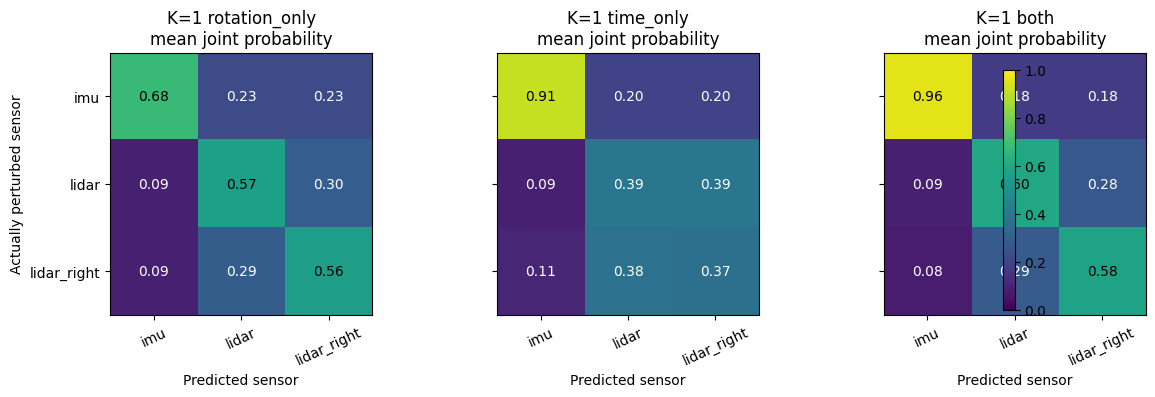

In [53]:
if APPENDIX_REPORT_SPLIT not in ('validation', 'test'):
    raise ValueError('APPENDIX_REPORT_SPLIT must be validation or test')
appendix_source_df = globals().get('validation_df' if APPENDIX_REPORT_SPLIT == 'validation' else 'test_df')
if not isinstance(appendix_source_df, pd.DataFrame):
    source_name = 'detailed_validation_scores.csv' if APPENDIX_REPORT_SPLIT == 'validation' else 'detailed_test_scores.csv'
    appendix_source_path = RUN_DIR / source_name
    if not appendix_source_path.is_file():
        raise FileNotFoundError(f'No cached detailed scores for {APPENDIX_REPORT_SPLIT}: {appendix_source_path}')
    appendix_source_df = pd.read_csv(appendix_source_path)
appendix_k1_df = appendix_source_df[appendix_source_df.fault_count == 1].copy()
if appendix_k1_df.empty:
    raise ValueError('Existing detailed evaluation has no K=1 cases.')
if appendix_k1_df.groupby('case_id').size().ne(len(CALIBRATION_KEYS)).any():
    raise ValueError('K=1 cases must each have exactly three sensor rows')

def summarize_k1_cases(df, task, threshold):
    """One row per K=1 case, preserving its two healthy sensor predictions."""
    if df.groupby('case_id').size().ne(len(CALIBRATION_KEYS)).any():
        raise ValueError('Every case must have exactly one row for each sensor')
    rows = []
    for case_id, group in df.groupby('case_id', sort=False):
        injected = group[group.injected.astype(bool)]
        if len(injected) != 1:
            raise AssertionError(f'K=1 case {case_id} has {len(injected)} injected sensor rows')
        selected = injected.iloc[0]
        other = group[group.sensor != selected.sensor]
        p_selected = float(selected[f'prob_{task}'])
        p_other = other[f'prob_{task}'].to_numpy(dtype=float)
        labels = group[f'target_{task}'].to_numpy(dtype=int)
        positives = int(labels.sum())
        selected_is_positive = bool(selected[f'target_{task}'])
        rows.append(dict(case_id=case_id, physical_index=selected.physical_index, fault_mode=selected.fault_mode,
                         selected_sensor=selected.sensor, rotation_deg=float(selected.true_rotation_deg),
                         abs_time_ms=abs(float(selected.true_tau_ms)), selected_is_positive=selected_is_positive,
                         n_positive=positives, p_selected=p_selected, p_other_max=float(p_other.max()),
                         margin=p_selected-float(p_other.max()), top1_correct=bool(p_selected > p_other.max()),
                         selected_detected=bool(p_selected >= threshold), healthy_false_alarms=int(np.count_nonzero(p_other >= threshold)),
                         exact_one_correct=bool(selected_is_positive and p_selected >= threshold and not np.any(p_other >= threshold))))
    return pd.DataFrame(rows)

appendix_k1_reports = {}
for task in ('joint', 'rotation', 'time'):
    report = summarize_k1_cases(appendix_k1_df, task, APPENDIX_THRESHOLDS[task])
    appendix_k1_reports[task] = report
    positives = report[report.selected_is_positive]
    print(f'\n{APPENDIX_REPORT_SPLIT.upper()} K=1 {task.upper()} | {len(report)} cases, {len(positives)} true-positive cases | threshold={APPENDIX_THRESHOLDS[task]:.3f}')
    if not positives.empty:
        print('Selected-sensor recall=',round(float(positives.selected_detected.mean()),3),
              '| top-1=',round(float(positives.top1_correct.mean()),3),
              '| exact-one-correct=',round(float(positives.exact_one_correct.mean()),3),
              '| mean healthy false alarms per case=',round(float(positives.healthy_false_alarms.mean()),3))
    print('By fault mode and selected sensor:')
    if not positives.empty:
        display(positives.groupby(['fault_mode','selected_sensor'], observed=True).agg(
            n=('case_id','size'), top1=('top1_correct','mean'), exact=('exact_one_correct','mean'),
            true_sensor_recall=('selected_detected','mean'), healthy_alarms_per_case=('healthy_false_alarms','mean'),
            mean_score_margin=('margin','mean')).round(3))

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.1), sharex=True, sharey=True)
for ax, mode in zip(axes, ('rotation_only', 'time_only', 'both')):
    sub = appendix_k1_df[appendix_k1_df.fault_mode == mode].copy()
    injected_sensor = sub[sub.injected == 1].set_index('case_id').sensor
    sub['selected_sensor'] = sub.case_id.map(injected_sensor)
    mat = sub.pivot_table(index='selected_sensor', columns='sensor', values='prob_joint', aggfunc='mean').reindex(index=CALIBRATION_KEYS, columns=CALIBRATION_KEYS)
    img = ax.imshow(mat.to_numpy(dtype=float), vmin=0, vmax=1, cmap='viridis')
    for (ri, ci), value in np.ndenumerate(mat.to_numpy(dtype=float)):
        if np.isfinite(value):
            ax.text(ci, ri, f'{value:.2f}', ha='center', va='center', color='white' if value < 0.50 else 'black', fontsize=10)
    ax.set(xticks=range(3), xticklabels=CALIBRATION_KEYS, yticks=range(3), yticklabels=CALIBRATION_KEYS,
           xlabel='Predicted sensor', title=f'K=1 {mode}\nmean joint probability')
    ax.tick_params(axis='x', labelrotation=25)
axes[0].set_ylabel('Actually perturbed sensor')
fig.colorbar(img, ax=axes.tolist(), shrink=0.76, pad=0.025)
fig.subplots_adjust(left=0.07, right=0.89, bottom=0.19, wspace=0.16, top=0.83)
if SAVE_PLOTS: fig.savefig(APPENDIX_DIR / f'{APPENDIX_REPORT_SPLIT}_k1_sensor_confusion_probability.png', dpi=PLOT_DPI, bbox_inches='tight')
if SHOW_PLOTS: plt.show()
else: plt.close(fig)

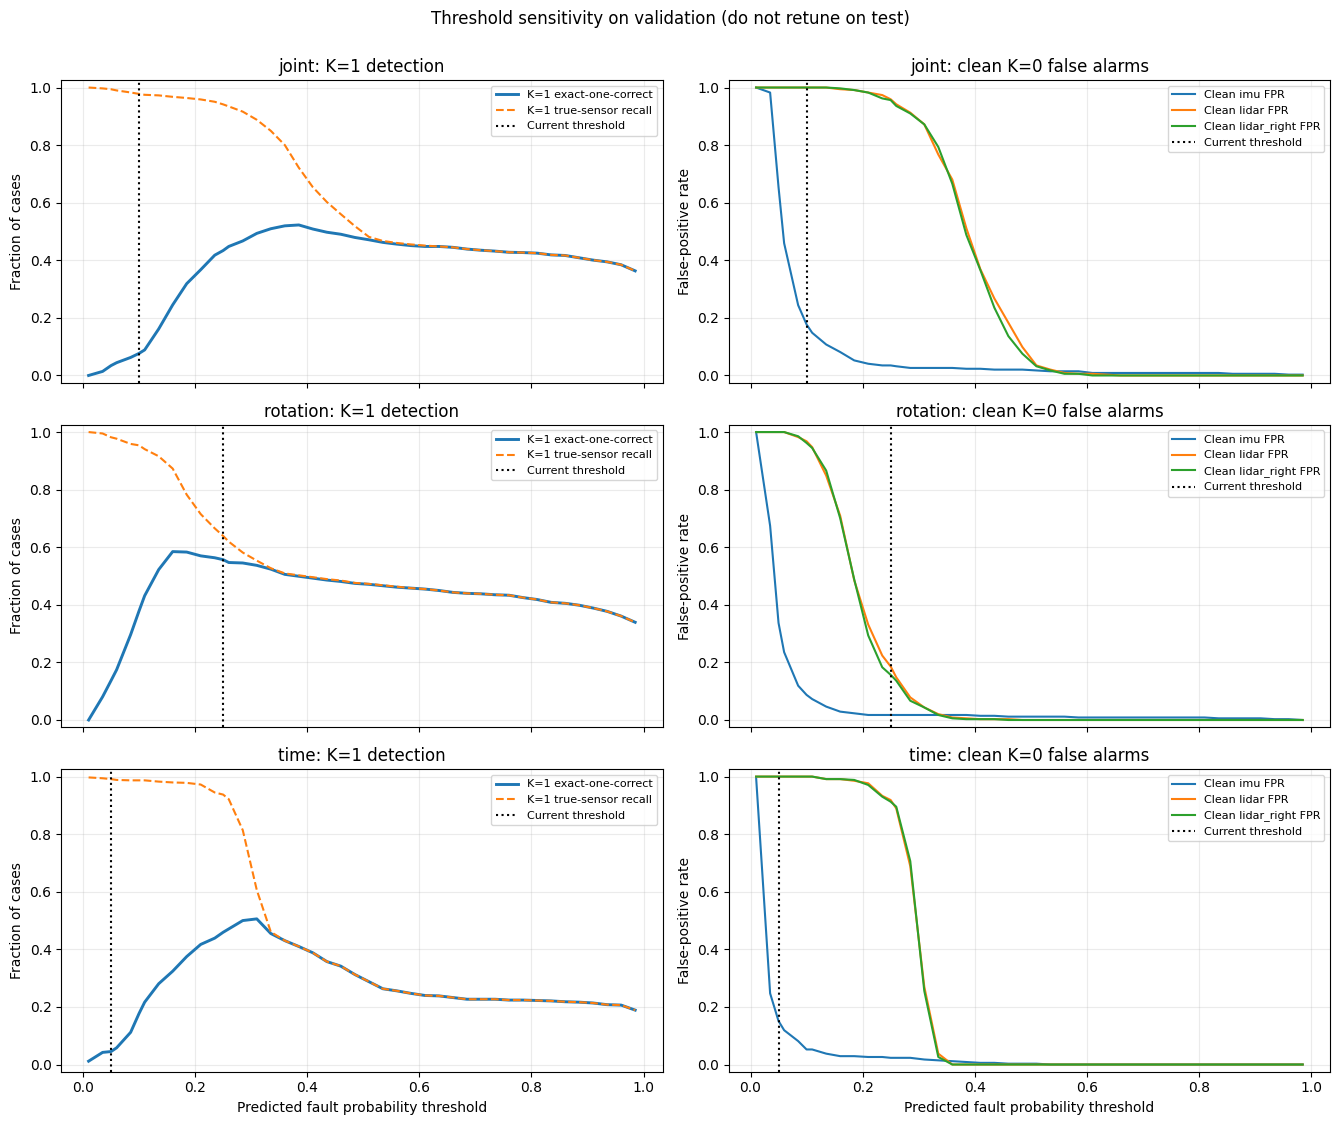

In [54]:
threshold_grid = np.unique(np.r_[np.arange(0.01, 0.991, 0.025), list(APPENDIX_THRESHOLDS.values())])
clean_cases = appendix_source_df[appendix_source_df.fault_count == 0]
fig, axes = plt.subplots(3, 2, figsize=(13.5, 11.2), sharex='col')
for ri, task in enumerate(('joint','rotation','time')):
    positive = appendix_k1_reports[task]
    positive = positive[positive.selected_is_positive]
    correct = []
    recall = []
    for threshold in threshold_grid:
        correct.append(float(((positive.p_selected >= threshold) & (positive.p_other_max < threshold)).mean()) if not positive.empty else np.nan)
        recall.append(float((positive.p_selected >= threshold).mean()) if not positive.empty else np.nan)
    axes[ri,0].plot(threshold_grid, correct, label='K=1 exact-one-correct', linewidth=2.1)
    axes[ri,0].plot(threshold_grid, recall, label='K=1 true-sensor recall', linestyle='--')
    for sensor in CALIBRATION_KEYS:
        clean_sensor = clean_cases[clean_cases.sensor == sensor]
        fpr = [(clean_sensor[f'prob_{task}'].to_numpy(float) >= threshold).mean() for threshold in threshold_grid]
        axes[ri,1].plot(threshold_grid, fpr, label=f'Clean {sensor} FPR')
    for ci in (0,1):
        axes[ri,ci].axvline(APPENDIX_THRESHOLDS[task], linestyle=':', color='black', label='Current threshold')
        axes[ri,ci].set_ylim(-0.025,1.025)
        axes[ri,ci].grid(alpha=0.25)
        axes[ri,ci].legend(loc='best', fontsize=8)
    axes[ri,0].set(title=f'{task}: K=1 detection', ylabel='Fraction of cases')
    axes[ri,1].set(title=f'{task}: clean K=0 false alarms', ylabel='False-positive rate')
axes[2,0].set_xlabel('Predicted fault probability threshold')
axes[2,1].set_xlabel('Predicted fault probability threshold')
fig.suptitle(f'Threshold sensitivity on {APPENDIX_REPORT_SPLIT} (do not retune on test)', y=1.00)
fig.tight_layout()
if SAVE_PLOTS: fig.savefig(APPENDIX_DIR / f'{APPENDIX_REPORT_SPLIT}_k1_exact_vs_clean_fpr_by_threshold.png', dpi=PLOT_DPI, bbox_inches='tight')
if SHOW_PLOTS: plt.show()
else: plt.close(fig)

K=0 predictions by sensor, no calibration error injected:


,n,mean_joint,median_joint,mean_rotation,mean_time,joint_only_alarm_fraction,joint_lower_bound_violation_fraction
sensor,,,,,,,
imu,344,0.086,0.057,0.062,0.039,0.026,0.0
lidar,344,0.388,0.388,0.194,0.292,0.000,0.0
lidar_right,344,0.385,0.383,0.191,0.291,0.000,0.0


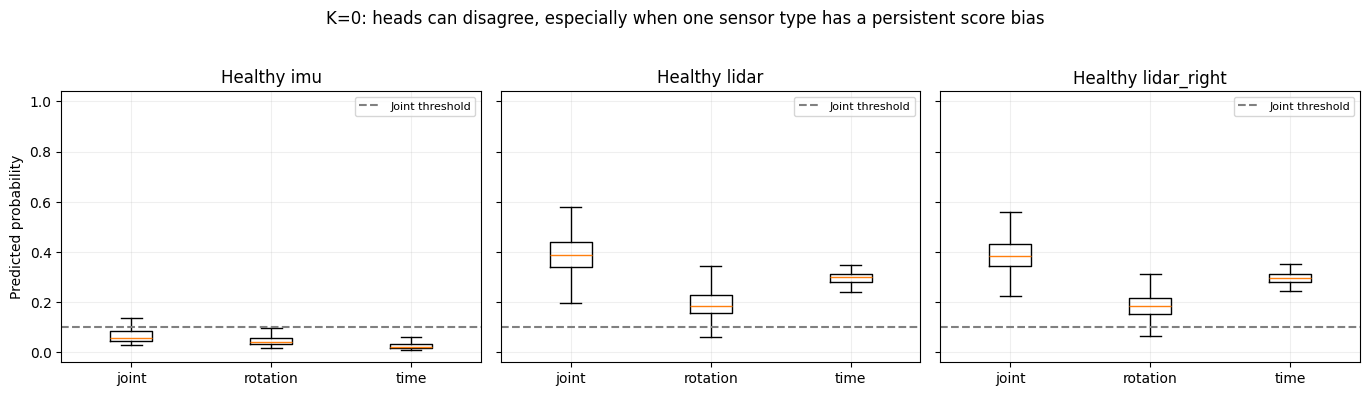

In [55]:
clean_scores = appendix_source_df[appendix_source_df.fault_count == 0].copy()
clean_scores['component_max_probability'] = clean_scores[['prob_rotation','prob_time']].max(axis=1)
clean_scores['joint_probability_lower_bound_violated'] = clean_scores.prob_joint + 1e-6 < clean_scores.component_max_probability
clean_scores['joint_only_alarm'] = ((clean_scores.prob_joint >= APPENDIX_THRESHOLDS['joint']) &
                                    (clean_scores.prob_rotation < APPENDIX_THRESHOLDS['rotation']) &
                                    (clean_scores.prob_time < APPENDIX_THRESHOLDS['time']))
print('K=0 predictions by sensor, no calibration error injected:')
display(clean_scores.groupby('sensor').agg(n=('case_id','size'),
    mean_joint=('prob_joint','mean'), median_joint=('prob_joint','median'),
    mean_rotation=('prob_rotation','mean'), mean_time=('prob_time','mean'),
    joint_only_alarm_fraction=('joint_only_alarm','mean'),
    joint_lower_bound_violation_fraction=('joint_probability_lower_bound_violated','mean')).round(3))

fig, axes = plt.subplots(1, 3, figsize=(13.8, 3.8), sharey=True)
for ax, sensor in zip(axes, CALIBRATION_KEYS):
    group = clean_scores[clean_scores.sensor == sensor]
    ax.boxplot([group[f'prob_{head}'].to_numpy(dtype=float) for head in ('joint','rotation','time')], showfliers=False)
    ax.set_xticks([1,2,3], ['joint','rotation','time'])
    ax.axhline(APPENDIX_THRESHOLDS['joint'], color='gray', linestyle='--', label='Joint threshold')
    ax.set(title=f'Healthy {sensor}', ylabel='Predicted probability' if sensor == CALIBRATION_KEYS[0] else '', ylim=(-0.04,1.04))
    ax.grid(alpha=0.20)
    ax.legend(fontsize=8)
fig.suptitle('K=0: heads can disagree, especially when one sensor type has a persistent score bias', y=1.03)
fig.tight_layout()
if SAVE_PLOTS: fig.savefig(APPENDIX_DIR / f'{APPENDIX_REPORT_SPLIT}_clean_head_disagreement.png',dpi=PLOT_DPI,bbox_inches='tight')
if SHOW_PLOTS: plt.show()
else: plt.close(fig)

In [56]:
import gc

APPENDIX_PROBE_INDICES = select_spread_indices_by_names(val_dataset, VAL_NAMES, APPENDIX_WINDOWS_PER_VAL_SEQUENCE, APPENDIX_SEED)
if len(APPENDIX_PROBE_INDICES) == 0:
    raise ValueError('No held-out validation windows for appendix.')

def appendix_case(case_id, physical_index, selected_sensor, *, angle_deg=0.0, tau_ms=0.0, axis=None, axis_id=0, sweep='rotation'):
    """Construct exactly one K=1 fault or a truly clean K=0 control."""
    perturbed = float(angle_deg) != 0.0 or float(tau_ms) != 0.0
    mode = 'both' if float(angle_deg) != 0.0 and float(tau_ms) != 0.0 else ('rotation_only' if float(angle_deg) != 0.0 else ('time_only' if float(tau_ms) != 0.0 else 'none'))
    rotations = {key: 0.0 for key in CALIBRATION_KEYS}
    tau_offsets = {key: 0.0 for key in CALIBRATION_KEYS}
    axes = {key: np.zeros(3, dtype=float) for key in CALIBRATION_KEYS}
    rotations[selected_sensor] = float(angle_deg)
    tau_offsets[selected_sensor] = float(tau_ms)
    if axis is not None:
        a = np.asarray(axis, dtype=float)
        if not np.isclose(np.linalg.norm(a), 1.0, atol=1e-5):
            raise ValueError('Rotation axis must be unit length')
        axes[selected_sensor] = a
    return dict(case_id=int(case_id), physical_id=int(physical_index), source_row=0, fault_count=int(perturbed),
                fault_mode=mode, injected_keys=(selected_sensor,) if perturbed else (), rotations=rotations,
                tau_ms=tau_offsets, axes=axes, selected_sensor=selected_sensor, axis_id=int(axis_id), sweep=sweep)

def appendix_angle_distance_deg(R):
    """Stable distance of an SO(3) rotation from identity near 0 and pi."""
    skew = torch.stack((R[..., 2, 1] - R[..., 1, 2], R[..., 0, 2] - R[..., 2, 0], R[..., 1, 0] - R[..., 0, 1]), dim=-1)
    return torch.rad2deg(torch.atan2(0.5 * torch.linalg.vector_norm(skew, dim=-1), 0.5 * (R.diagonal(dim1=-2, dim2=-1).sum(-1) - 1.0)))

def appendix_signature():
    return dict(checkpoint=str(BEST_CHECKPOINT_PATH.resolve()), checkpoint_mtime_ns=BEST_CHECKPOINT_PATH.stat().st_mtime_ns,
                model_objective=TRAINING_OBJECTIVE, validation_indices=APPENDIX_PROBE_INDICES.tolist(),
                angles=list(APPENDIX_ANGLES_DEG), signed_time_ms=list(APPENDIX_SIGNED_TIME_MS) if APPENDIX_RUN_TIME_SWEEP else [],
                axes_per_window=APPENDIX_AXIS_REPEATS, with_regressor=APPENDIX_COMPARE_REGRESSOR,
                regressor_path=str(APPENDIX_REGRESSOR_CHECKPOINT) if APPENDIX_COMPARE_REGRESSOR else None,
                rot_tolerance=GT_ROT_TOL_DEG, time_tolerance_ms=GT_TAU_TOL_MS)

@torch.inference_mode()
def collect_appendix_k1_sweep():
    if not BEST_CHECKPOINT_PATH.is_file():
        raise FileNotFoundError(f'Classifier best.pt not found: {BEST_CHECKPOINT_PATH}')
    probe_classifier = PooledCalibrationClassifierModel(model_config).to(device=DEVICE, dtype=MODEL_DTYPE)
    load_training_checkpoint(BEST_CHECKPOINT_PATH, model=probe_classifier, map_location=DEVICE, restore_rng_state=False)
    probe_classifier.eval().requires_grad_(False)
    probe_regressor = None
    if APPENDIX_COMPARE_REGRESSOR:
        if not APPENDIX_REGRESSOR_CHECKPOINT.is_file():
            raise FileNotFoundError(f'Optional 002.27 regression checkpoint missing: {APPENDIX_REGRESSOR_CHECKPOINT}')
        from obscalib.models.pooled_calibration_6d_model import PooledCalibration6DModel
        probe_regressor = PooledCalibration6DModel(model_config).to(device=DEVICE, dtype=MODEL_DTYPE)
        load_training_checkpoint(APPENDIX_REGRESSOR_CHECKPOINT, model=probe_regressor, map_location=DEVICE, restore_rng_state=False)
        probe_regressor.eval().requires_grad_(False)

    records, next_id = [], 0
    for wi, physical_index in enumerate(APPENDIX_PROBE_INDICES):
        raw = window_batch_to(collate_windows([val_dataset[int(physical_index)]]), DEVICE, dtype=MODEL_DTYPE)
        physical = fixed_seeded_physical(raw, APPENDIX_SEED + 1009 * int(physical_index))
        cases = []
        for selected_sensor in CALIBRATION_KEYS:
            for axis_id in range(APPENDIX_AXIS_REPEATS):
                local_rng = np.random.default_rng(APPENDIX_SEED + CALIBRATION_KEYS.index(selected_sensor) * 1009 + axis_id)
                axis = local_rng.normal(size=3)
                axis /= np.linalg.norm(axis)
                for angle_deg in APPENDIX_ANGLES_DEG:
                    cases.append(appendix_case(next_id, physical_index, selected_sensor, angle_deg=angle_deg, axis=axis, axis_id=axis_id, sweep='rotation'))
                    next_id += 1
            if APPENDIX_RUN_TIME_SWEEP:
                for tau_ms in APPENDIX_SIGNED_TIME_MS:
                    cases.append(appendix_case(next_id, physical_index, selected_sensor, tau_ms=tau_ms, axis_id=0, sweep='time'))
                    next_id += 1

        for pos in range(0, len(cases), BATCH_SIZE):
            subset = cases[pos:pos + BATCH_SIZE]
            window = faulted_window_from_cases(physical, subset)
            tokens = tokenize_window(window)
            y_joint, y_rot, y_time = labels_from_cases(subset, tokens.calibration_keys)
            p = probe_classifier(tokens).logits.sigmoid().cpu().numpy()
            ys = dict(joint=y_joint.cpu().numpy(), rotation=y_rot.cpu().numpy(), time=y_time.cpu().numpy())
            reg = {}
            if probe_regressor is not None:
                predictions = probe_regressor(tokens).predictions
                for sensor in CALIBRATION_KEYS:
                    pr = predictions[sensor]
                    delta_tau = pr.delta_tau
                    if delta_tau is None:
                        raise AttributeError('Regression model must output delta_tau for fair comparison')
                    reg[sensor] = (appendix_angle_distance_deg(pr.delta_rotation).cpu().numpy().reshape(-1),
                                   (1000.0 * delta_tau.abs()).cpu().numpy().reshape(-1))
            for ri, case in enumerate(subset):
                for si, sensor in enumerate(tokens.calibration_keys):
                    row = dict(case_id=case['case_id'], physical_index=case['physical_id'], sweep=case['sweep'],
                               mode=case['fault_mode'], selected_sensor=case['selected_sensor'], axis_id=case['axis_id'],
                               sensor=sensor, injected=int(sensor in case['injected_keys']),
                               angle_deg=float(case['rotations'][case['selected_sensor']]), tau_ms=float(case['tau_ms'][case['selected_sensor']]),
                               target_joint=int(ys['joint'][ri,si]), target_rotation=int(ys['rotation'][ri,si]), target_time=int(ys['time'][ri,si]),
                               prob_joint=float(p[ri,si,0]), prob_rotation=float(p[ri,si,1]), prob_time=float(p[ri,si,2]))
                    if probe_regressor is not None:
                        row['reg_rotation_deg'] = float(reg[sensor][0][ri])
                        row['reg_abs_tau_ms'] = float(reg[sensor][1][ri])
                    records.append(row)
        print(f'Appendix K=1 sweep: {wi+1}/{len(APPENDIX_PROBE_INDICES)} physical validation windows; {len(cases)} cases/window', flush=True)
        del physical, raw
    del probe_classifier, probe_regressor
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    df = pd.DataFrame(records)
    if df.groupby('case_id').sensor.nunique().ne(len(CALIBRATION_KEYS)).any():
        raise AssertionError('Controlled sweep has duplicated or missing sensor heads')
    df.to_csv(APPENDIX_SCORE_PATH, index=False)
    APPENDIX_SCORE_META_PATH.write_text(json.dumps(appendix_signature(), indent=2), encoding='utf-8')
    return df

if not BEST_CHECKPOINT_PATH.is_file():
    raise FileNotFoundError('The classifier best.pt is required for controlled appendix probes')
if APPENDIX_RUN_INFERENCE:
    appendix_probe_df = collect_appendix_k1_sweep()
else:
    if not APPENDIX_SCORE_PATH.is_file() or not APPENDIX_SCORE_META_PATH.is_file():
        raise FileNotFoundError('Cached K=1 probe missing. Set APPENDIX_RUN_INFERENCE=True once.')
    cached = json.loads(APPENDIX_SCORE_META_PATH.read_text(encoding='utf-8'))
    if cached != appendix_signature():
        raise ValueError('Cached sweep was generated with different checkpoint or settings; rerun inference.')
    appendix_probe_df = pd.read_csv(APPENDIX_SCORE_PATH)
print('Controlled sweep:', len(appendix_probe_df)//3, 'K=0/K=1 cases over',
      appendix_probe_df.physical_index.nunique(), 'physical validation windows')
display(appendix_probe_df.groupby(['sweep','selected_sensor']).case_id.nunique().rename('cases').to_frame())


Appendix K=1 sweep: 1/80 physical validation windows; 141 cases/window
Appendix K=1 sweep: 2/80 physical validation windows; 141 cases/window
Appendix K=1 sweep: 3/80 physical validation windows; 141 cases/window
Appendix K=1 sweep: 4/80 physical validation windows; 141 cases/window
Appendix K=1 sweep: 5/80 physical validation windows; 141 cases/window
Appendix K=1 sweep: 6/80 physical validation windows; 141 cases/window
Appendix K=1 sweep: 7/80 physical validation windows; 141 cases/window
Appendix K=1 sweep: 8/80 physical validation windows; 141 cases/window
Appendix K=1 sweep: 9/80 physical validation windows; 141 cases/window
Appendix K=1 sweep: 10/80 physical validation windows; 141 cases/window
Appendix K=1 sweep: 11/80 physical validation windows; 141 cases/window
Appendix K=1 sweep: 12/80 physical validation windows; 141 cases/window
Appendix K=1 sweep: 13/80 physical validation windows; 141 cases/window
Appendix K=1 sweep: 14/80 physical validation windows; 141 cases/window
A

cases
sweep    selected_sensor       
rotation imu               2400
         lidar             2400
         lidar_right       2400
time     imu               1360
         lidar             1360
         lidar_right       1360

Rotation-only controlled K=1: selected sensor versus both healthy sensors


,value,n_cases,n_positive_cases,selected_recall,top1,exact,healthy_any_false_alarm,f1
0,0.0,480,0,NaN,NaN,NaN,0.179,0.000
1,1.0,480,0,NaN,NaN,NaN,0.173,0.000
2,2.0,480,0,NaN,NaN,NaN,0.165,0.000
3,3.0,480,0,NaN,NaN,NaN,0.154,0.000
4,4.0,480,480,0.183,0.612,0.094,0.146,0.270
5,5.0,480,480,0.246,0.669,0.158,0.146,0.347
6,10.0,480,480,0.346,0.869,0.269,0.110,0.470
7,20.0,480,480,0.573,0.933,0.517,0.073,0.696
8,45.0,480,480,0.956,0.948,0.900,0.067,0.945
9,60.0,480,480,0.965,0.967,0.900,0.067,0.950


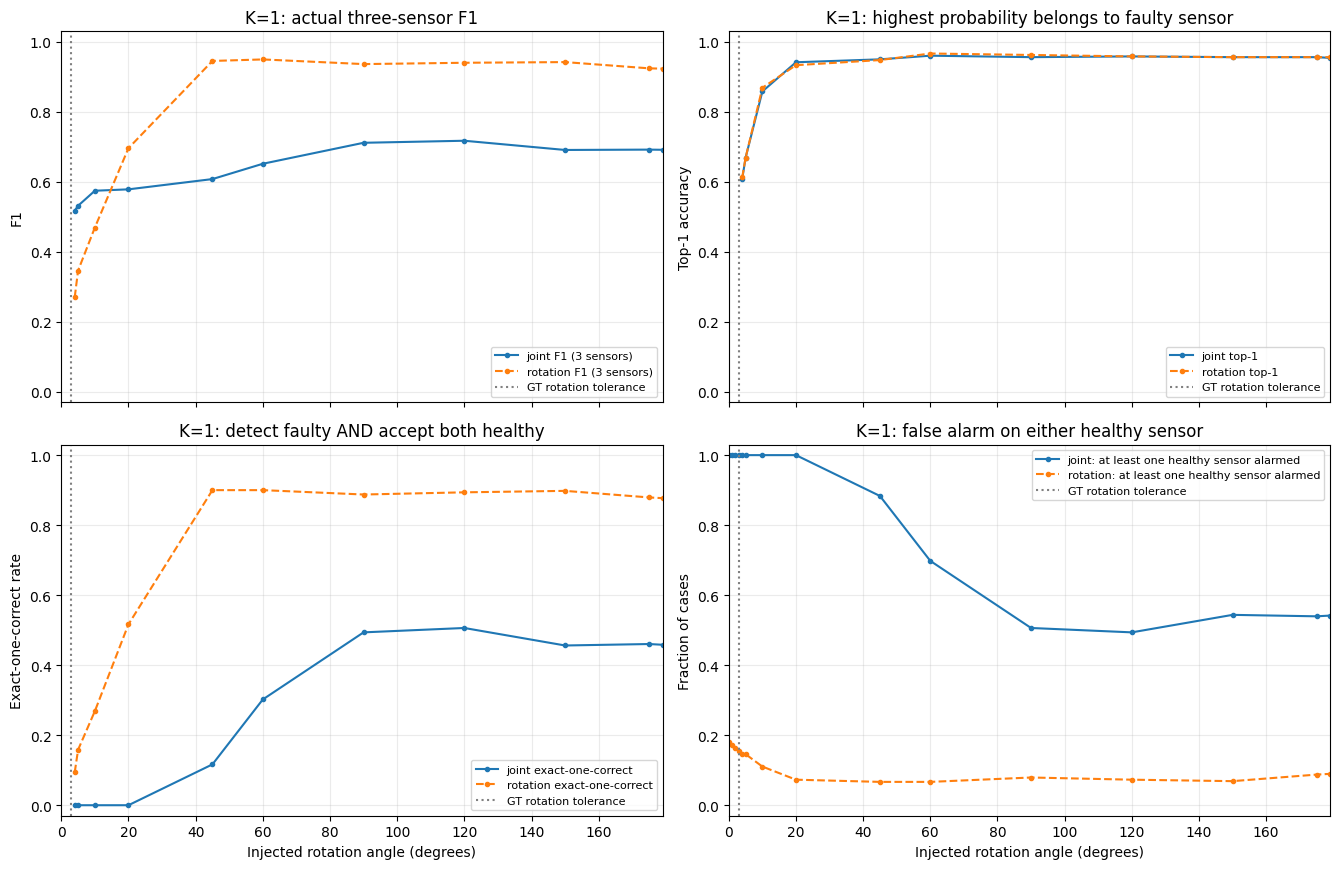

In [57]:
def summarize_controlled_k1(df, *, task, sweep, value_field):
    """Compute three-sensor F1, threshold-free top-1, and exact-one-correct for each injected magnitude."""
    rows = []
    values = sorted(df.loc[df.sweep == sweep, value_field].unique().tolist())
    for value in values:
        part = df[(df.sweep == sweep) & np.isclose(df[value_field], value)]
        if part.empty:
            continue
        threshold = APPENDIX_THRESHOLDS[task]
        truth = part[f'target_{task}'].to_numpy(dtype=bool)
        pred = part[f'prob_{task}'].to_numpy(dtype=float) >= threshold
        tp = int(np.count_nonzero(truth & pred))
        fp = int(np.count_nonzero(~truth & pred))
        fn = int(np.count_nonzero(truth & ~pred))
        f1 = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else np.nan
        scores = []
        for cid, group in part.groupby('case_id', sort=False):
            chosen = group[group.sensor == group.selected_sensor.iloc[0]].iloc[0]
            others = group[group.sensor != chosen.sensor]
            p_selected = float(chosen[f'prob_{task}'])
            p_other = others[f'prob_{task}'].to_numpy(dtype=float)
            positive = bool(chosen[f'target_{task}'])
            scores.append(dict(positive=positive, top1=int(p_selected > p_other.max()),
                               recall=int(p_selected >= threshold), exact=int(positive and p_selected >= threshold and not np.any(p_other >= threshold)),
                               any_fp=int(np.any(p_other >= threshold)), p_selected=p_selected, p_other_max=float(p_other.max())))
        vals = pd.DataFrame(scores)
        active = vals[vals.positive]
        rows.append(dict(task=task, sweep=sweep, value=value, n_cases=len(vals), n_positive_cases=len(active),
                         f1=f1, selected_recall=float(active.recall.mean()) if not active.empty else np.nan,
                         top1=float(active.top1.mean()) if not active.empty else np.nan,
                         exact=float(active.exact.mean()) if not active.empty else np.nan,
                         healthy_any_false_alarm=float(vals.any_fp.mean()),
                         p_selected_mean=float(vals.p_selected.mean()), p_other_max_mean=float(vals.p_other_max.mean())))
    return pd.DataFrame(rows)

appendix_rotation_curves = {task: summarize_controlled_k1(appendix_probe_df, task=task, sweep='rotation', value_field='angle_deg')
                            for task in ('joint', 'rotation')}
rotation_table = appendix_rotation_curves['rotation']
print('Rotation-only controlled K=1: selected sensor versus both healthy sensors')
display(rotation_table[['value','n_cases','n_positive_cases','selected_recall','top1','exact','healthy_any_false_alarm','f1']].round(3))

fig, axes = plt.subplots(2, 2, figsize=(13.5, 8.8), sharex=True)
for task, style in (('joint','-'), ('rotation','--')):
    curve = appendix_rotation_curves[task]
    active = curve[curve.n_positive_cases > 0]
    axes[0,0].plot(active.value, active.f1, linestyle=style, marker='o', markersize=3, label=f'{task} F1 (3 sensors)')
    axes[0,1].plot(active.value, active.top1, linestyle=style, marker='o', markersize=3, label=f'{task} top-1')
    axes[1,0].plot(active.value, active.exact, linestyle=style, marker='o', markersize=3, label=f'{task} exact-one-correct')
    axes[1,1].plot(curve.value, curve.healthy_any_false_alarm, linestyle=style, marker='o', markersize=3,
                   label=f'{task}: at least one healthy sensor alarmed')
axes[0,0].set(title='K=1: actual three-sensor F1', ylabel='F1')
axes[0,1].set(title='K=1: highest probability belongs to faulty sensor', ylabel='Top-1 accuracy')
axes[1,0].set(title='K=1: detect faulty AND accept both healthy', ylabel='Exact-one-correct rate')
axes[1,1].set(title='K=1: false alarm on either healthy sensor', ylabel='Fraction of cases')
for ax in axes.flat:
    ax.axvline(GT_ROT_TOL_DEG, color='gray', linestyle=':', label='GT rotation tolerance')
    ax.set_ylim(-0.03, 1.03)
    ax.set_xlim(min(APPENDIX_ANGLES_DEG), max(APPENDIX_ANGLES_DEG))
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
for ax in axes[1]:
    ax.set_xlabel('Injected rotation angle (degrees)')
fig.tight_layout()
if SAVE_PLOTS: fig.savefig(APPENDIX_DIR / 'controlled_k1_angle_metrics.png', dpi=PLOT_DPI, bbox_inches='tight')
if SHOW_PLOTS: plt.show()
else: plt.close(fig)

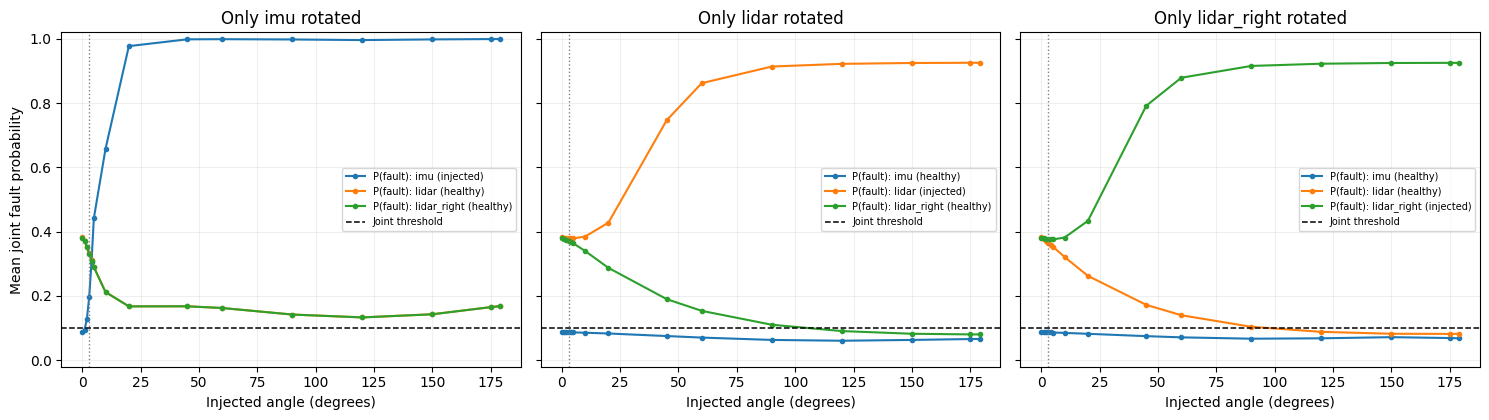

In [58]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharey=True)
rot = appendix_probe_df[appendix_probe_df.sweep == 'rotation']
for ax, selected_sensor in zip(axes, CALIBRATION_KEYS):
    group = rot[rot.selected_sensor == selected_sensor]
    for predicted_sensor in CALIBRATION_KEYS:
        series = group[group.sensor == predicted_sensor].groupby('angle_deg').prob_joint.agg(['mean','std'])
        ax.plot(series.index, series['mean'], marker='.', linewidth=1.5,
                label=f'P(fault): {predicted_sensor}' + (' (injected)' if predicted_sensor == selected_sensor else ' (healthy)'))
    ax.axhline(APPENDIX_THRESHOLDS['joint'], color='black', linestyle='--', linewidth=1.1, label='Joint threshold')
    ax.axvline(GT_ROT_TOL_DEG, color='gray', linestyle=':', linewidth=1)
    ax.set(xlabel='Injected angle (degrees)', title=f'Only {selected_sensor} rotated', ylim=(-0.02,1.02))
    ax.grid(alpha=0.2)
    ax.legend(fontsize=7)
axes[0].set_ylabel('Mean joint fault probability')
fig.tight_layout()
if SAVE_PLOTS: fig.savefig(APPENDIX_DIR / 'controlled_k1_angle_probability_by_sensor.png', dpi=PLOT_DPI, bbox_inches='tight')
if SHOW_PLOTS: plt.show()
else: plt.close(fig)

Representative controlled validation windows (weakest then strongest 90° top-1): [(172, 0.333), (35, 1.0)]


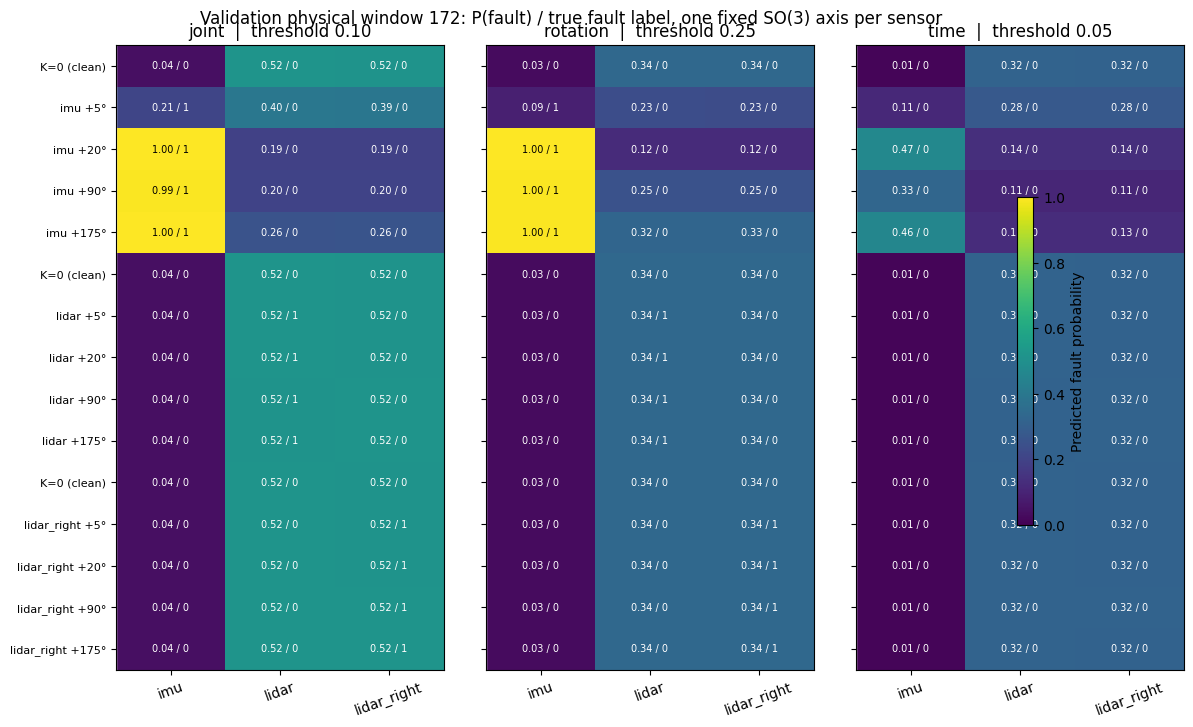

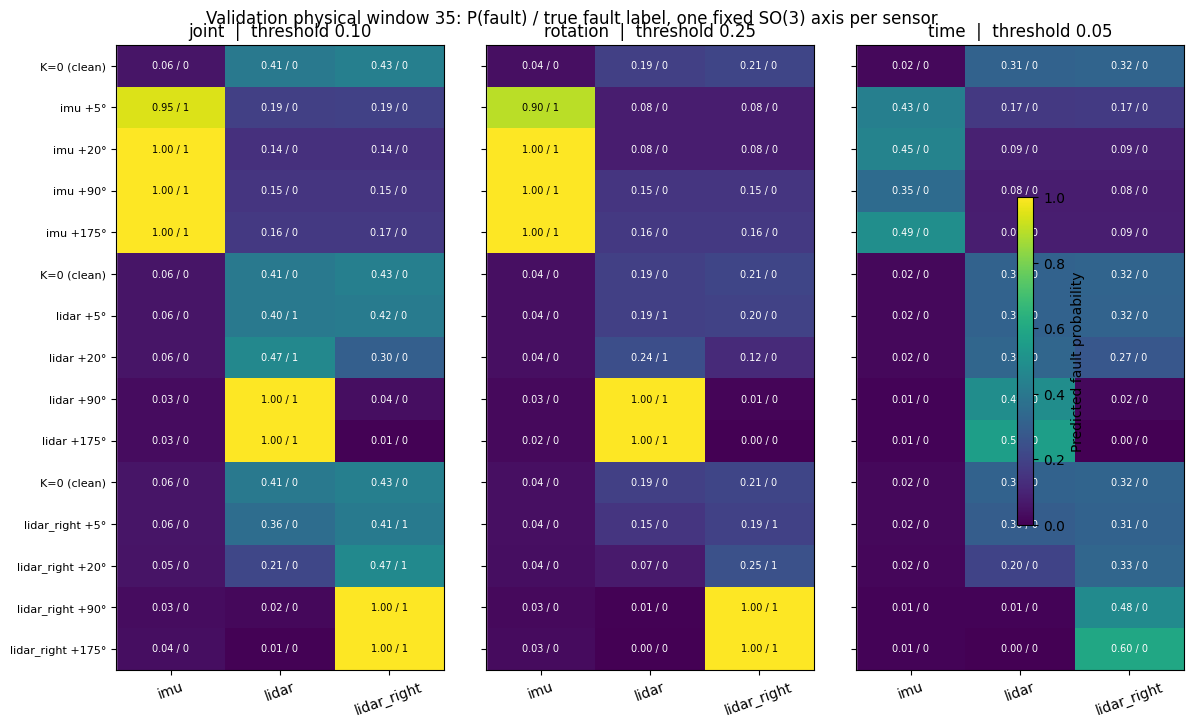

In [59]:
def appendix_example_heatmap(df, physical_index, *, angles=(0., 5., 20., 90., 175.), axis_id=0):
    base = df[(df.physical_index == physical_index) & (df.sweep == 'rotation') & (df.axis_id == axis_id)]
    if base.empty:
        return
    selected = base[base.angle_deg.isin(angles)].copy()
    combos = [(sensor, angle) for sensor in CALIBRATION_KEYS for angle in angles]
    labels = [f'{sensor} +{angle:g}°' if angle else 'K=0 (clean)' for sensor, angle in combos]
    fig, axes = plt.subplots(1, 3, figsize=(15.7, max(5.2, 0.38 * len(combos) + 1.4)), sharey=True)
    for ax, task in zip(axes, ('joint','rotation','time')):
        mat = np.full((len(combos), len(CALIBRATION_KEYS)), np.nan)
        tgt = np.full_like(mat, np.nan)
        for ri, (selected_sensor, angle) in enumerate(combos):
            part = selected[(selected.selected_sensor == selected_sensor) & np.isclose(selected.angle_deg, angle)]
            for ci, sensor in enumerate(CALIBRATION_KEYS):
                matches = part[part.sensor == sensor]
                if len(matches) == 1:
                    mat[ri,ci] = float(matches.iloc[0][f'prob_{task}'])
                    tgt[ri,ci] = int(matches.iloc[0][f'target_{task}'])
        image = ax.imshow(mat, vmin=0, vmax=1, cmap='viridis', aspect='auto')
        for (ri, ci), value in np.ndenumerate(mat):
            if np.isfinite(value):
                ax.text(ci,ri,f'{value:.2f} / {int(tgt[ri,ci])}',ha='center',va='center',fontsize=7,
                        color='black' if value > 0.65 else 'white')
        ax.set_xticks(np.arange(3), CALIBRATION_KEYS, rotation=20)
        ax.set_yticks(np.arange(len(combos)), labels, fontsize=8)
        ax.axvline(-0.5, color='white', linewidth=1)
        ax.set_title(f'{task}  |  threshold {APPENDIX_THRESHOLDS[task]:.2f}')
    fig.colorbar(image, ax=axes.tolist(), shrink=0.6, pad=0.015, label='Predicted fault probability')
    fig.suptitle(f'Validation physical window {physical_index}: P(fault) / true fault label, one fixed SO(3) axis per sensor', y=0.99)
    fig.subplots_adjust(left=0.21, right=0.89, top=0.94, bottom=0.06, wspace=0.13)
    if SAVE_PLOTS: fig.savefig(APPENDIX_DIR / f'window_{physical_index}_angle_setup_heatmap.png', dpi=PLOT_DPI, bbox_inches='tight')
    if SHOW_PLOTS: plt.show()
    else: plt.close(fig)

# Select illustrative validation windows by ability to RANK the actual 90-degree faulty sensor.
example = appendix_probe_df[(appendix_probe_df.sweep == 'rotation') & (appendix_probe_df.axis_id == 0) & np.isclose(appendix_probe_df.angle_deg, 90.)]
case_ranks = []
for cid, group in example.groupby('case_id',sort=False):
    selected_sensor = group.selected_sensor.iloc[0]
    p_selected = float(group[group.sensor == selected_sensor].iloc[0].prob_rotation)
    p_other = group[group.sensor != selected_sensor].prob_rotation.max()
    case_ranks.append(dict(physical_index=int(group.physical_index.iloc[0]), top1=int(p_selected > p_other)))
rank_df = pd.DataFrame(case_ranks)
rank_by_window = rank_df.groupby('physical_index').top1.mean().sort_values()
if rank_by_window.empty:
    raise AssertionError('The 90-degree angle is required for representative example selection')
example_indices = [int(rank_by_window.index[0]), int(rank_by_window.index[-1])]
print('Representative controlled validation windows (weakest then strongest 90° top-1):',
      [(idx, round(float(rank_by_window.loc[idx]),3)) for idx in example_indices])
for index in dict.fromkeys(example_indices):
    appendix_example_heatmap(appendix_probe_df, index)

Controlled time-only K=1 (signed offset ms):


,value,n_cases,n_positive_cases,selected_recall,top1,exact,healthy_any_false_alarm,f1
0,-300.0,240,240,1.000,0.425,0.0,1.0,0.539
1,-150.0,240,240,1.000,0.429,0.0,1.0,0.571
2,-100.0,240,240,1.000,0.442,0.0,1.0,0.573
3,-50.0,240,240,0.988,0.521,0.0,1.0,0.569
4,-30.0,240,240,0.983,0.575,0.0,1.0,0.571
5,-15.0,240,240,0.904,0.346,0.0,1.0,0.539
6,-10.0,240,0,NaN,NaN,NaN,1.0,0.000
7,-5.0,240,0,NaN,NaN,NaN,1.0,0.000
8,0.0,240,0,NaN,NaN,NaN,1.0,0.000
9,5.0,240,0,NaN,NaN,NaN,1.0,0.000


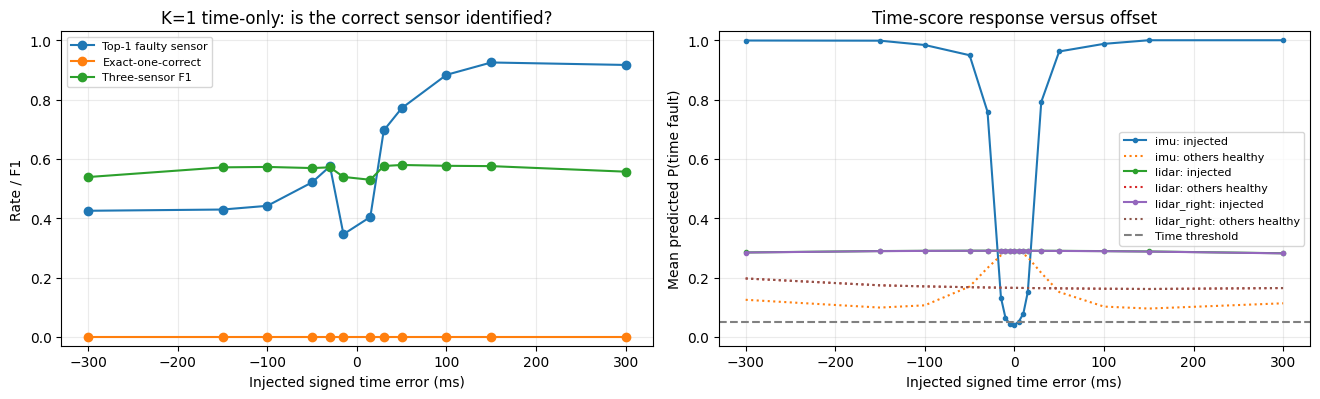

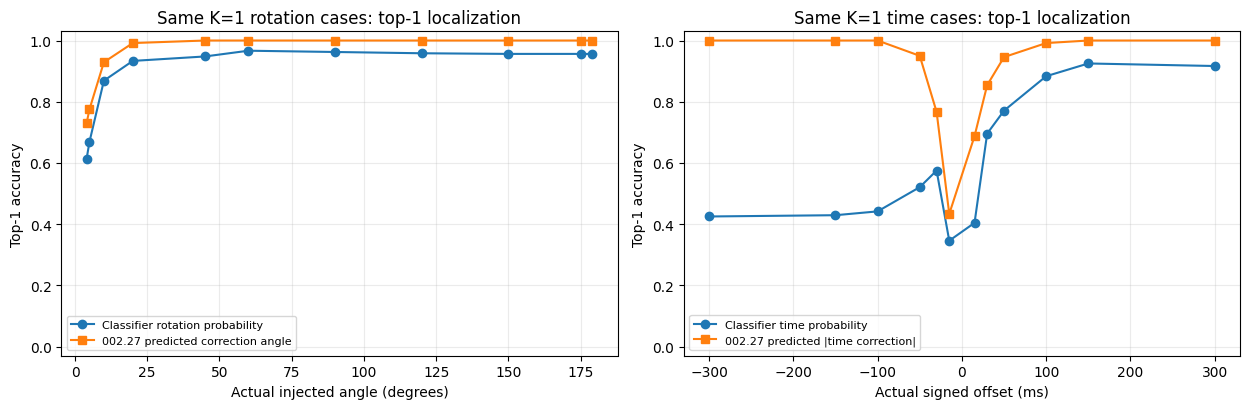

Appendix saved to: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_classifier_005.1_joint_weighted_k/appendix_k1_fault_localization
Interpretation guide:
  High selected-sensor recall, low exact-one-correct => excessive healthy-sensor alarms.
  High top-1, low exact-one-correct => probability thresholds/calibration may help.
  Low top-1 even at 90–179° => architecture/input features not reliably localizing the fault.
  Stable high LiDAR score at zero injection => sensor-specific bias or input/GT mismatch worth auditing.


In [60]:
if APPENDIX_RUN_TIME_SWEEP and (appendix_probe_df.sweep == 'time').any():
    appendix_time_curve = summarize_controlled_k1(appendix_probe_df, task='time', sweep='time', value_field='tau_ms')
    print('Controlled time-only K=1 (signed offset ms):')
    display(appendix_time_curve[['value','n_cases','n_positive_cases','selected_recall','top1','exact','healthy_any_false_alarm','f1']].round(3))
    fig, axes = plt.subplots(1, 2, figsize=(13.3, 4.1))
    active = appendix_time_curve[appendix_time_curve.n_positive_cases > 0]
    for col, label in (('top1','Top-1 faulty sensor'), ('exact','Exact-one-correct'), ('f1','Three-sensor F1')):
        axes[0].plot(active.value, active[col], marker='o', label=label)
    axes[0].set(xlabel='Injected signed time error (ms)', ylabel='Rate / F1', title='K=1 time-only: is the correct sensor identified?', ylim=(-0.03,1.03))
    times = appendix_probe_df[appendix_probe_df.sweep == 'time']
    for sensor in CALIBRATION_KEYS:
        source = times[times.selected_sensor == sensor]
        selected_scores = source[source.sensor == sensor].groupby('tau_ms').prob_time.mean()
        healthy_scores = source[source.sensor != sensor].groupby('tau_ms').prob_time.mean()
        axes[1].plot(selected_scores.index, selected_scores.values, marker='.', label=f'{sensor}: injected')
        axes[1].plot(healthy_scores.index, healthy_scores.values, linestyle=':', label=f'{sensor}: others healthy')
    axes[1].axhline(APPENDIX_THRESHOLDS['time'], color='gray', linestyle='--', label='Time threshold')
    axes[1].set(xlabel='Injected signed time error (ms)', ylabel='Mean predicted P(time fault)', title='Time-score response versus offset', ylim=(-0.03,1.03))
    for ax in axes:
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)
    fig.tight_layout()
    if SAVE_PLOTS: fig.savefig(APPENDIX_DIR / 'controlled_k1_signed_time_metrics.png', dpi=PLOT_DPI, bbox_inches='tight')
    if SHOW_PLOTS: plt.show()
    else: plt.close(fig)

def appendix_top1_curve(df, *, sweep, score_field, value_field, positive_threshold):
    """Threshold-independent 3-way localization of a true K=1 fault."""
    rows = []
    part = df[(df.sweep == sweep) & (df[value_field].abs() > positive_threshold)]
    for value, group in part.groupby(value_field, sort=True):
        found = []
        for _, case in group.groupby('case_id', sort=False):
            expected = case.selected_sensor.iloc[0]
            selected_score = case.loc[case.sensor == expected, score_field].iloc[0]
            other_score = case.loc[case.sensor != expected, score_field].max()
            found.append(float(selected_score > other_score))
        rows.append(dict(value=value, n=len(found), top1=float(np.mean(found))))
    return pd.DataFrame(rows)

if APPENDIX_COMPARE_REGRESSOR:
    if 'reg_rotation_deg' not in appendix_probe_df:
        raise RuntimeError('No regressor scores cached. Set APPENDIX_RUN_INFERENCE=True and APPENDIX_COMPARE_REGRESSOR=True')
    clf_rot = appendix_top1_curve(appendix_probe_df, sweep='rotation', score_field='prob_rotation', value_field='angle_deg', positive_threshold=GT_ROT_TOL_DEG)
    reg_rot = appendix_top1_curve(appendix_probe_df, sweep='rotation', score_field='reg_rotation_deg', value_field='angle_deg', positive_threshold=GT_ROT_TOL_DEG)
    fig, axes = plt.subplots(1, 2, figsize=(12.6, 4.2))
    axes[0].plot(clf_rot.value, clf_rot.top1, marker='o', label='Classifier rotation probability')
    axes[0].plot(reg_rot.value, reg_rot.top1, marker='s', label='002.27 predicted correction angle')
    axes[0].set(title='Same K=1 rotation cases: top-1 localization', xlabel='Actual injected angle (degrees)', ylabel='Top-1 accuracy', ylim=(-0.03,1.03))
    if APPENDIX_RUN_TIME_SWEEP:
        clf_t = appendix_top1_curve(appendix_probe_df, sweep='time', score_field='prob_time', value_field='tau_ms', positive_threshold=GT_TAU_TOL_MS)
        reg_t = appendix_top1_curve(appendix_probe_df, sweep='time', score_field='reg_abs_tau_ms', value_field='tau_ms', positive_threshold=GT_TAU_TOL_MS)
        axes[1].plot(clf_t.value, clf_t.top1, marker='o', label='Classifier time probability')
        axes[1].plot(reg_t.value, reg_t.top1, marker='s', label='002.27 predicted |time correction|')
        axes[1].set(title='Same K=1 time cases: top-1 localization', xlabel='Actual signed offset (ms)', ylabel='Top-1 accuracy', ylim=(-0.03,1.03))
    else:
        axes[1].axis('off')
    for ax in axes:
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)
    fig.tight_layout()
    if SAVE_PLOTS: fig.savefig(APPENDIX_DIR / 'classifier_vs_00227_same_cases_top1.png', dpi=PLOT_DPI, bbox_inches='tight')
    if SHOW_PLOTS: plt.show()
    else: plt.close(fig)

print('Appendix saved to:', APPENDIX_DIR)
print('Interpretation guide:')
print('  High selected-sensor recall, low exact-one-correct => excessive healthy-sensor alarms.')
print('  High top-1, low exact-one-correct => probability thresholds/calibration may help.')
print('  Low top-1 even at 90–179° => architecture/input features not reliably localizing the fault.')
print('  Stable high LiDAR score at zero injection => sensor-specific bias or input/GT mismatch worth auditing.')


## Canonical K=1 F1 versus injected rotation angle
The existing PDF's A2 controlled sweep was run with APPENDIX_COMPARE_REGRESSOR = False, so no regression scores exist there. Turn it on and rerun A2 to obtain the reg_rotation_deg column. Then execute 77_fair_k1_rotation_f1_comparison_cell.py in a Jupyter cell.

Important split bug in the current appendix: APPENDIX_REPORT_SPLIT selects the dataset for A1 summary tables only. A2 controlled-sweep code still always reads val_dataset and VAL_NAMES. To perform final test evaluation, make these replacements in A2 before rerunning inference:

In [77]:
# %% Appendix: one canonical K=1 rotation-only comparison with 002.27
# Prerequisites:
#   1. APPENDIX_COMPARE_REGRESSOR = True; rerun controlled sweep inference (section A2).
#   2. Both models scored exactly the same augmented physical windows / fault cases.
#   3. Thresholds below are fixed BEFORE evaluation; tune on separate validation cases.
#   4. The original appendix's controlled sweep ALWAYS uses val_dataset unless its
#      dataset selection is patched separately (see 77_appendix_comparison_notes.md).

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

COMPARISON_SPLIT = 'validation'  # Change to 'test' only AFTER patching A2 data selection and rerunning inference.
ROT_GT_TOLERANCE_DEG = float(GT_ROT_TOL_DEG)
CLASSIFIER_ROT_THRESHOLDS = {sensor: float(APPENDIX_THRESHOLDS['rotation']) for sensor in CALIBRATION_KEYS}
REGRESSOR_ROT_THRESHOLDS_DEG = {sensor: float(GT_ROT_TOL_DEG) for sensor in CALIBRATION_KEYS}

required_columns = {'case_id', 'physical_index', 'sweep', 'selected_sensor', 'sensor', 'angle_deg',
                    'target_rotation', 'prob_rotation', 'reg_rotation_deg'}
missing = required_columns.difference(appendix_probe_df.columns)
if missing:
    raise RuntimeError(f'Missing columns {sorted(missing)}. Set APPENDIX_COMPARE_REGRESSOR=True and rerun the controlled sweep.')

rotation_cases = appendix_probe_df.loc[appendix_probe_df['sweep'] == 'rotation'].copy()

In [78]:
# -------------------------------------------------------------------------
# Multi-window score aggregation
# -------------------------------------------------------------------------

WINDOWS_PER_DECISION = 40

if WINDOWS_PER_DECISION < 1:
    raise ValueError('WINDOWS_PER_DECISION must be positive.')

if 'axis_id' not in rotation_cases.columns:
    raise ValueError('Controlled sweep must contain axis_id.')

# Keep the original single-window predictions for further analysis.
single_window_rotation_cases = rotation_cases.copy()

comparison_dataset = val_dataset if COMPARISON_SPLIT == 'validation' else test_dataset
comparison_names = VAL_NAMES if COMPARISON_SPLIT == 'validation' else TEST_NAMES

# Create non-overlapping groups of N physical windows.
# Never combine windows belonging to different sequences.
window_to_group = {}
next_group_id = 0

Urban26: 94 available, 40 evaluated.
Urban28: 324 available, 40 evaluated.
Evaluating N=1, repeats=100...
Evaluating N=2, repeats=100...
Evaluating N=4, repeats=100...
Evaluating N=8, repeats=100...
Evaluating N=16, repeats=100...
Evaluating N=20, repeats=100...
Evaluating N=40, repeats=100...
Repeated evaluation finished.


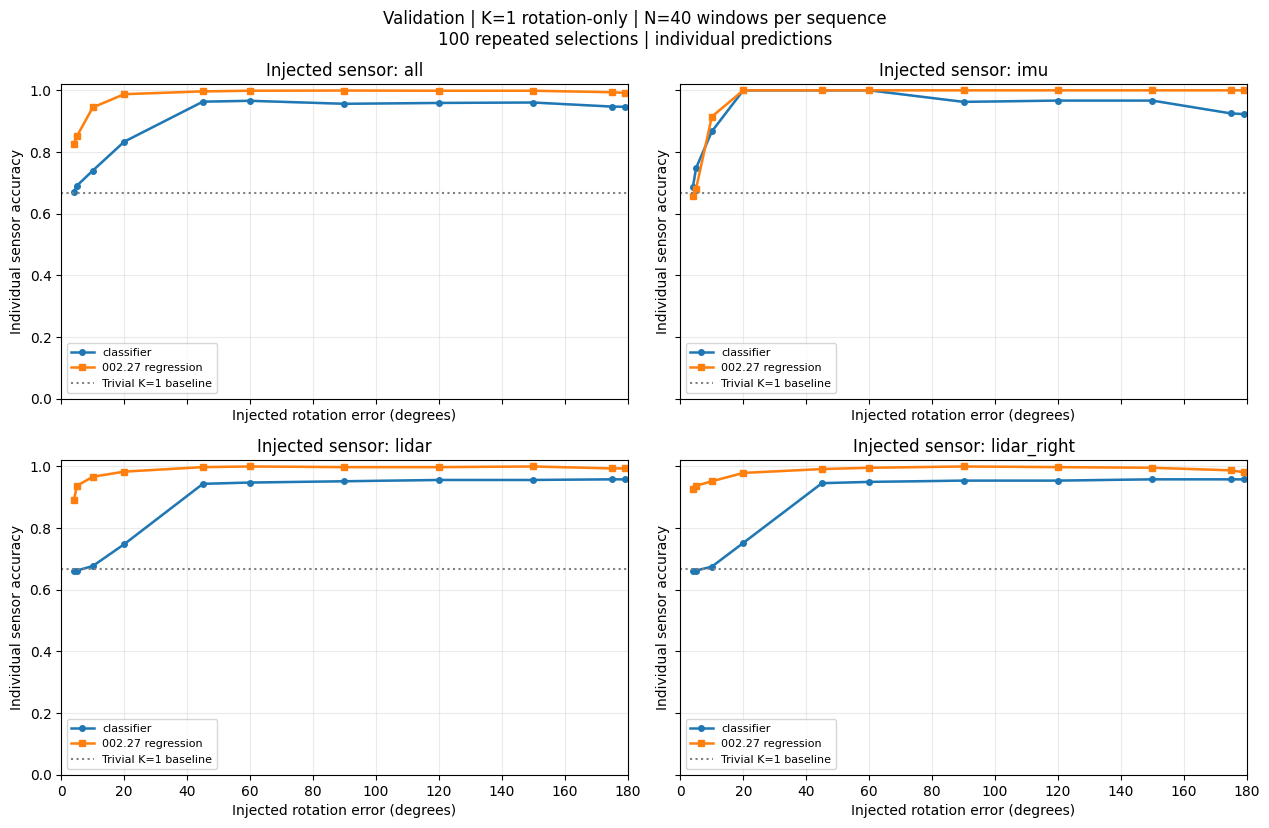

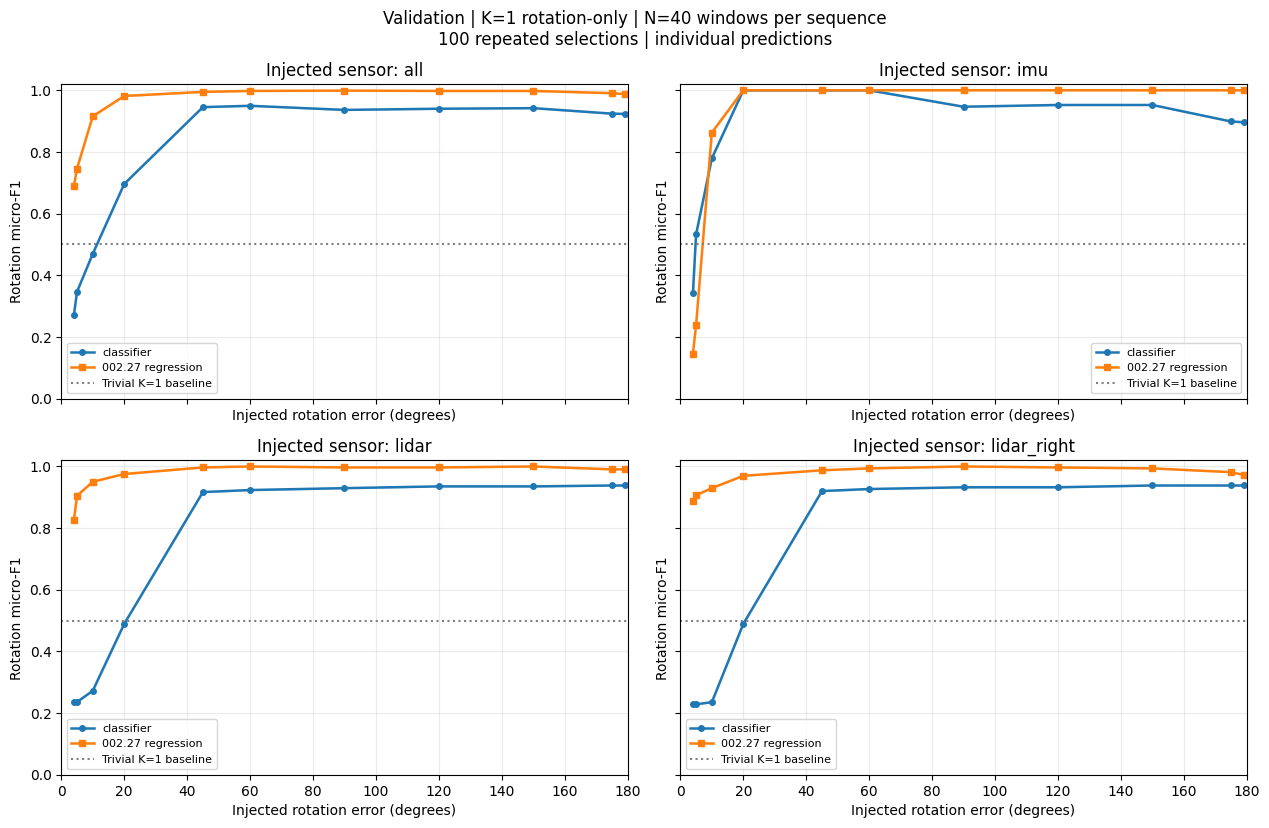

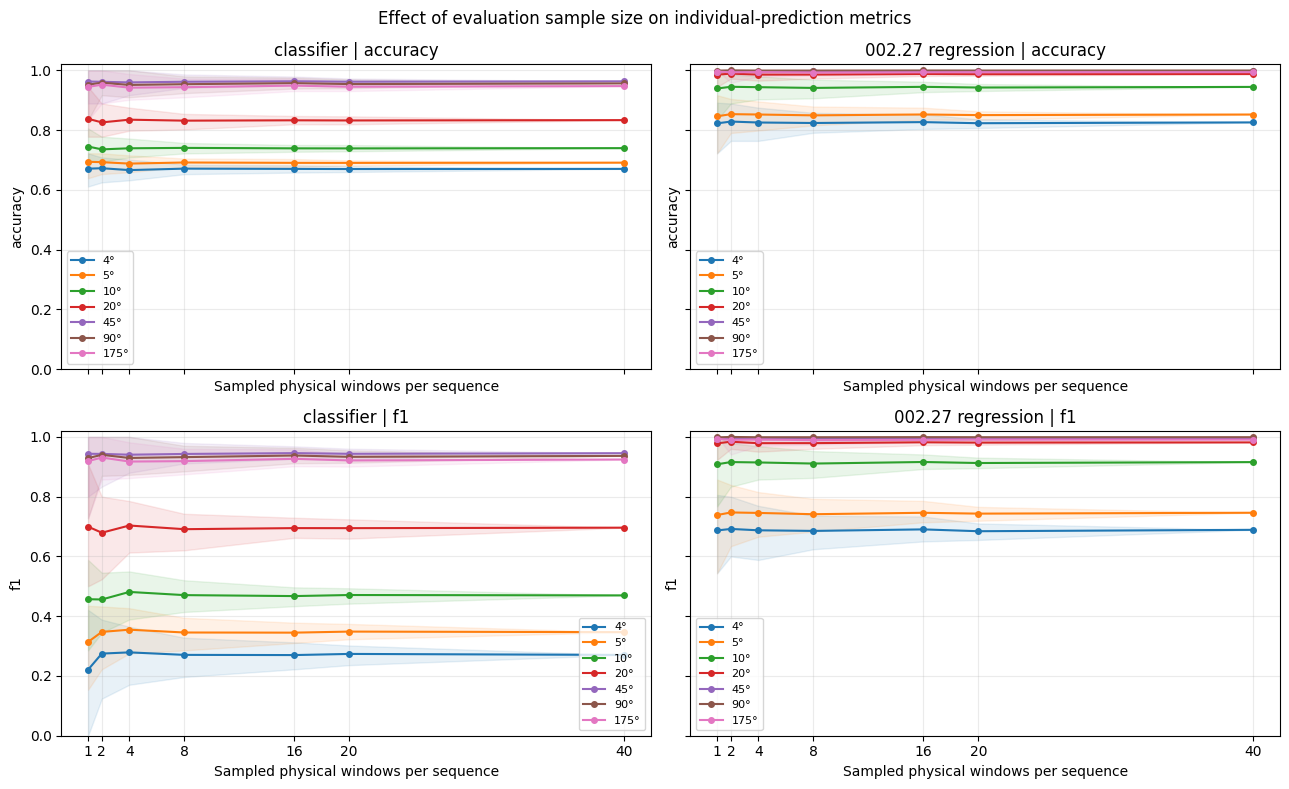


K=0 false-alarm rates:


,sensor,method,false_alarms,n_predictions,false_alarm_rate
0,imu,classifier,12,480,0.025
1,imu,002.27 regression,18,480,0.038
2,lidar,classifier,78,480,0.162
3,lidar,002.27 regression,36,480,0.075
4,lidar_right,classifier,78,480,0.162
5,lidar_right,002.27 regression,18,480,0.038



Reference metrics: ALL evaluated physical windows, each prediction counted once:


,angle_deg,method,n_predictions,n_correct,tp,fp,fn,tn,accuracy,precision,recall,specificity,f1
0,4.0,002.27 regression,1440,1189,278,49,202,911,0.826,0.850,0.579,0.949,0.689
1,4.0,classifier,1440,965,88,83,392,877,0.670,0.515,0.183,0.914,0.270
2,5.0,002.27 regression,1440,1227,313,46,167,914,0.852,0.872,0.652,0.952,0.746
3,5.0,classifier,1440,995,118,83,362,877,0.691,0.587,0.246,0.914,0.347
4,10.0,002.27 regression,1440,1360,434,34,46,926,0.944,0.927,0.904,0.965,0.916
5,10.0,classifier,1440,1065,166,61,314,899,0.740,0.731,0.346,0.936,0.470
6,20.0,002.27 regression,1440,1422,480,18,0,942,0.988,0.964,1.000,0.981,0.982
7,20.0,classifier,1440,1200,275,35,205,925,0.833,0.887,0.573,0.964,0.696
8,45.0,002.27 regression,1440,1435,480,5,0,955,0.997,0.990,1.000,0.995,0.995
9,45.0,classifier,1440,1387,459,32,21,928,0.963,0.935,0.956,0.967,0.945



Repeated sampling results:


,N,angle_deg,method,accuracy,accuracy_p10,accuracy_p90,f1,f1_p10,f1_p90
0,1,4.0,002.27 regression,0.822,0.722,0.892,0.687,0.544,0.806
1,1,4.0,classifier,0.671,0.611,0.722,0.221,0.000,0.421
2,1,5.0,002.27 regression,0.846,0.722,0.917,0.738,0.544,0.857
3,1,5.0,classifier,0.694,0.639,0.722,0.314,0.154,0.435
4,1,10.0,002.27 regression,0.939,0.833,1.000,0.908,0.767,1.000
...,...,...,...,...,...,...,...,...,...
545,40,150.0,classifier,0.960,0.960,0.960,0.942,0.942,0.942
546,40,175.0,002.27 regression,0.994,0.994,0.994,0.991,0.991,0.991
547,40,175.0,classifier,0.947,0.947,0.947,0.924,0.924,0.924
548,40,179.0,002.27 regression,0.992,0.992,0.992,0.988,0.988,0.988


In [81]:
# %% Appendix: repeated multi-window evaluation of individual predictions

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -------------------------------------------------------------------------
# Configuration
# -------------------------------------------------------------------------

COMPARISON_SPLIT = 'validation'

WINDOW_COUNTS = (1, 2, 4, 8, 16, 20, 40)
NUM_REPEATS = 100
COMPARISON_SEED = 12345

# N denotes the number of sampled physical windows PER sequence.
PLOT_N = 40
PLOT_ANGLES_DEG = (4., 5., 10., 20., 45., 90., 175.)

ROT_GT_TOLERANCE_DEG = float(GT_ROT_TOL_DEG)

CLASSIFIER_ROT_THRESHOLDS = {
    sensor: float(APPENDIX_THRESHOLDS['rotation'])
    for sensor in CALIBRATION_KEYS
}

REGRESSOR_ROT_THRESHOLDS_DEG = {
    sensor: float(GT_ROT_TOL_DEG)
    for sensor in CALIBRATION_KEYS
}

METHODS = {
    'classifier': 'clf_predicted_fault',
    '002.27 regression': 'reg_predicted_fault',
}

# -------------------------------------------------------------------------
# Prepare original individual-window predictions
# -------------------------------------------------------------------------

required_columns = {
    'case_id', 'physical_index', 'sweep', 'selected_sensor',
    'sensor', 'angle_deg', 'target_rotation',
    'prob_rotation', 'reg_rotation_deg',
}

missing = required_columns.difference(appendix_probe_df.columns)

if missing:
    raise RuntimeError(f'Missing columns: {sorted(missing)}')

rotation_cases = appendix_probe_df.loc[
    appendix_probe_df['sweep'] == 'rotation'
].copy()

if rotation_cases.empty:
    raise ValueError('No controlled rotation cases available.')

case_sizes = rotation_cases.groupby('case_id')['sensor'].agg(['size', 'nunique'])

if not case_sizes.eq(len(CALIBRATION_KEYS)).all().all():
    raise AssertionError('Every case must contain exactly three distinct sensor decisions.')

expected_truth = (
    (rotation_cases['sensor'] == rotation_cases['selected_sensor']) &
    (rotation_cases['angle_deg'] > ROT_GT_TOLERANCE_DEG)
)

if not np.array_equal(rotation_cases['target_rotation'].to_numpy(bool), expected_truth.to_numpy(bool)):
    raise AssertionError('Incorrect ground-truth rotation labels.')

# Threshold EVERY prediction individually.
rotation_cases['clf_predicted_fault'] = (
    rotation_cases['prob_rotation'].to_numpy(float) >=
    rotation_cases['sensor'].map(CLASSIFIER_ROT_THRESHOLDS).to_numpy(float)
)

rotation_cases['reg_predicted_fault'] = (
    rotation_cases['reg_rotation_deg'].to_numpy(float) >=
    rotation_cases['sensor'].map(REGRESSOR_ROT_THRESHOLDS_DEG).to_numpy(float)
)

# -------------------------------------------------------------------------
# Identify available physical windows
# -------------------------------------------------------------------------

comparison_dataset = val_dataset if COMPARISON_SPLIT == 'validation' else test_dataset
comparison_names = VAL_NAMES if COMPARISON_SPLIT == 'validation' else TEST_NAMES

evaluated_indices = set(rotation_cases['physical_index'].unique())

indices_by_sequence = {}

for sequence in comparison_names:
    available = set(comparison_dataset.window_indices_for_sequence(sequence))
    evaluated = sorted(available.intersection(evaluated_indices))

    if not evaluated:
        raise ValueError(f'No evaluated physical windows for {sequence}.')

    indices_by_sequence[sequence] = np.asarray(evaluated, dtype=int)

    print(f'{sequence}: {len(available)} available, {len(evaluated)} evaluated.')

max_n = min(len(indices) for indices in indices_by_sequence.values())

valid_window_counts = tuple(n for n in WINDOW_COUNTS if 1 <= n <= max_n)

if not valid_window_counts:
    raise ValueError('Not enough evaluated windows.')

if valid_window_counts != WINDOW_COUNTS:
    print(f'Some N values exceed available windows. Using {valid_window_counts}.')

# -------------------------------------------------------------------------
# Compute confusion counts for individual predictions
# -------------------------------------------------------------------------

COUNT_COLUMNS = ['tp', 'fp', 'fn', 'tn']
GROUP_COLUMNS = ['selected_sensor', 'angle_deg', 'method']


def add_metrics_from_counts(frame):
    """Compute metrics from accumulated individual prediction counts."""
    frame = frame.copy()

    tp, fp, fn, tn = (frame[col] for col in COUNT_COLUMNS)

    frame['n_predictions'] = tp + fp + fn + tn
    frame['n_correct'] = tp + tn

    frame['accuracy'] = (
        frame['n_correct'] /
        frame['n_predictions'].replace(0, np.nan)
    )

    frame['precision'] = tp / (tp + fp).replace(0, np.nan)
    frame['recall'] = tp / (tp + fn).replace(0, np.nan)
    frame['specificity'] = tn / (tn + fp).replace(0, np.nan)

    frame['f1'] = (
        2 * tp /
        (2 * tp + fp + fn).replace(0, np.nan)
    )

    return frame


positive_cases = rotation_cases.loc[
    rotation_cases['angle_deg'] > ROT_GT_TOLERANCE_DEG
].copy()

window_count_tables = []

for method, prediction_column in METHODS.items():
    truth = positive_cases['target_rotation'].to_numpy(bool)
    pred = positive_cases[prediction_column].to_numpy(bool)

    frame = positive_cases[
        ['physical_index', 'selected_sensor', 'angle_deg']
    ].copy()

    frame['method'] = method
    frame['tp'] = (pred & truth).astype(int)
    frame['fp'] = (pred & ~truth).astype(int)
    frame['fn'] = (~pred & truth).astype(int)
    frame['tn'] = (~pred & ~truth).astype(int)

    # Count decisions within each physical window.
    # No probability or correction magnitude averaging.
    counts = frame.groupby(
        ['physical_index', *GROUP_COLUMNS],
        as_index=False,
    )[COUNT_COLUMNS].sum()

    # Additional aggregate across injected sensors.
    all_counts = counts.groupby(
        ['physical_index', 'angle_deg', 'method'],
        as_index=False,
    )[COUNT_COLUMNS].sum()

    all_counts['selected_sensor'] = 'all'

    window_count_tables.extend([counts, all_counts])

window_counts = pd.concat(window_count_tables, ignore_index=True)

# -------------------------------------------------------------------------
# Reference: evaluate ALL available individual predictions exactly once
# -------------------------------------------------------------------------

full_metrics = add_metrics_from_counts(
    window_counts.groupby(
        GROUP_COLUMNS,
        as_index=False,
    )[COUNT_COLUMNS].sum()
)

full_metrics.to_csv(
    APPENDIX_DIR / f'{COMPARISON_SPLIT}_all_window_metrics.csv',
    index=False,
)

# -------------------------------------------------------------------------
# Repeated random sampling of N windows per sequence
# -------------------------------------------------------------------------

rng = np.random.default_rng(COMPARISON_SEED)
repeat_results = []

for n_windows in valid_window_counts:
    print(f'Evaluating N={n_windows}, repeats={NUM_REPEATS}...')

    for repeat in range(NUM_REPEATS):

        # Draw the SAME physical windows for both models,
        # all injected sensors and all angles.
        chosen_indices = np.concatenate([
            rng.choice(indices, size=n_windows, replace=False)
            for indices in indices_by_sequence.values()
        ])

        subset = window_counts.loc[
            window_counts['physical_index'].isin(chosen_indices)
        ]

        # Sum individual TP, FP, FN and TN counts.
        counts = subset.groupby(
            GROUP_COLUMNS,
            as_index=False,
        )[COUNT_COLUMNS].sum()

        metrics = add_metrics_from_counts(counts)

        metrics['N'] = n_windows
        metrics['repeat'] = repeat
        metrics['n_physical_windows'] = len(chosen_indices)

        repeat_results.append(metrics)

repeat_df = pd.concat(repeat_results, ignore_index=True)

repeat_df.to_csv(
    APPENDIX_DIR / f'{COMPARISON_SPLIT}_repeated_window_metrics.csv',
    index=False,
)

# -------------------------------------------------------------------------
# Pool all individual prediction counts across repeated selections
# -------------------------------------------------------------------------

summary_keys = ['N', *GROUP_COLUMNS]

comparison_summary = add_metrics_from_counts(
    repeat_df.groupby(
        summary_keys,
        as_index=False,
    )[COUNT_COLUMNS].sum()
)

# Variability between randomly selected sets of physical windows.
# These bands are descriptive, not independent-sample confidence intervals.
variability = repeat_df.groupby(summary_keys, as_index=False).agg(
    accuracy_p10=('accuracy', lambda x: x.quantile(0.10)),
    accuracy_p90=('accuracy', lambda x: x.quantile(0.90)),
    f1_p10=('f1', lambda x: x.quantile(0.10)),
    f1_p90=('f1', lambda x: x.quantile(0.90)),
)

comparison_summary = comparison_summary.merge(
    variability,
    on=summary_keys,
    validate='one_to_one',
)

comparison_summary.to_csv(
    APPENDIX_DIR / f'{COMPARISON_SPLIT}_window_count_summary.csv',
    index=False,
)

print('Repeated evaluation finished.')

# -------------------------------------------------------------------------
# Plot 1: accuracy and F1 versus injected angle for selected N
# -------------------------------------------------------------------------

plot_n = PLOT_N if PLOT_N in valid_window_counts else max(valid_window_counts)

for metric, ylabel, baseline in [
    ('accuracy', 'Individual sensor accuracy', 2 / 3),
    ('f1', 'Rotation micro-F1', 0.5),
]:
    fig, axes = plt.subplots(2, 2, figsize=(12.8, 8.4), sharex=True, sharey=True)

    for ax, selected_sensor in zip(axes.flat, ('all', *CALIBRATION_KEYS)):

        subset = comparison_summary.loc[
            (comparison_summary['N'] == plot_n) &
            (comparison_summary['selected_sensor'] == selected_sensor)
        ]

        for method, marker in [('classifier', 'o'), ('002.27 regression', 's')]:

            curve = subset.loc[
                subset['method'] == method
            ].sort_values('angle_deg')

            x = curve['angle_deg'].to_numpy(float)
            y = curve[metric].to_numpy(float)

            line, = ax.plot(
                x, y, marker=marker, markersize=4,
                linewidth=1.8, label=method,
            )

            ax.fill_between(
                x,
                curve[f'{metric}_p10'].to_numpy(float),
                curve[f'{metric}_p90'].to_numpy(float),
                color=line.get_color(),
                alpha=0.15,
            )

        ax.axhline(
            baseline,
            color='gray',
            linestyle=':',
            label='Trivial K=1 baseline',
        )

        ax.set(
            title=f'Injected sensor: {selected_sensor}',
            xlabel='Injected rotation error (degrees)',
            ylabel=ylabel,
            xlim=(0, 180),
            ylim=(0, 1.02),
        )

        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)

    fig.suptitle(
        f'{COMPARISON_SPLIT.title()} | K=1 rotation-only | '
        f'N={plot_n} windows per sequence\n'
        f'{NUM_REPEATS} repeated selections | individual predictions',
        fontsize=12,
    )

    fig.tight_layout()

    if SAVE_PLOTS:
        fig.savefig(
            APPENDIX_DIR / f'{COMPARISON_SPLIT}_{metric}_vs_angle_N{plot_n}.png',
            dpi=PLOT_DPI,
            bbox_inches='tight',
        )

    if SHOW_PLOTS:
        plt.show()
    else:
        plt.close(fig)

# -------------------------------------------------------------------------
# Plot 2: dependence of accuracy and F1 on N
# -------------------------------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True, sharey=True)

for row, metric in enumerate(('accuracy', 'f1')):
    for col, method in enumerate(METHODS):

        ax = axes[row, col]

        subset = comparison_summary.loc[
            (comparison_summary['method'] == method) &
            (comparison_summary['selected_sensor'] == 'all')
        ]

        for angle in PLOT_ANGLES_DEG:

            curve = subset.loc[
                np.isclose(subset['angle_deg'], angle)
            ].sort_values('N')

            if curve.empty:
                continue

            x = curve['N'].to_numpy(float)
            y = curve[metric].to_numpy(float)

            line, = ax.plot(
                x, y, '-o',
                markersize=4,
                label=f'{angle:g}°',
            )

            ax.fill_between(
                x,
                curve[f'{metric}_p10'].to_numpy(float),
                curve[f'{metric}_p90'].to_numpy(float),
                color=line.get_color(),
                alpha=0.10,
            )

        ax.set(
            title=f'{method} | {metric}',
            xlabel='Sampled physical windows per sequence',
            ylabel=metric,
            ylim=(0, 1.02),
        )

        ax.set_xticks(valid_window_counts)
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)

fig.suptitle(
    'Effect of evaluation sample size on individual-prediction metrics',
    fontsize=12,
)

fig.tight_layout()

if SAVE_PLOTS:
    fig.savefig(
        APPENDIX_DIR / f'{COMPARISON_SPLIT}_metrics_vs_number_of_windows.png',
        dpi=PLOT_DPI,
        bbox_inches='tight',
    )

if SHOW_PLOTS:
    plt.show()
else:
    plt.close(fig)

# -------------------------------------------------------------------------
# Clean sensor false alarms
# -------------------------------------------------------------------------

clean = rotation_cases.loc[np.isclose(rotation_cases['angle_deg'], 0)].copy()

clean_fpr = pd.DataFrame([
    {
        'sensor': sensor,
        'method': method,
        'false_alarms': int(group[prediction].sum()),
        'n_predictions': len(group),
        'false_alarm_rate': float(group[prediction].mean()),
    }
    for sensor, group in clean.groupby('sensor')
    for method, prediction in METHODS.items()
])

print('\nK=0 false-alarm rates:')
display(clean_fpr.round(3))

print('\nReference metrics: ALL evaluated physical windows, each prediction counted once:')

display(
    full_metrics.loc[
        full_metrics['selected_sensor'] == 'all',
        [
            'angle_deg', 'method', 'n_predictions', 'n_correct',
            'tp', 'fp', 'fn', 'tn',
            'accuracy', 'precision', 'recall', 'specificity', 'f1',
        ],
    ].round(3)
)

print('\nRepeated sampling results:')

display(
    comparison_summary.loc[
        comparison_summary['selected_sensor'] == 'all',
        [
            'N', 'angle_deg', 'method',
            'accuracy', 'accuracy_p10', 'accuracy_p90',
            'f1', 'f1_p10', 'f1_p90',
        ],
    ].round(3)
)

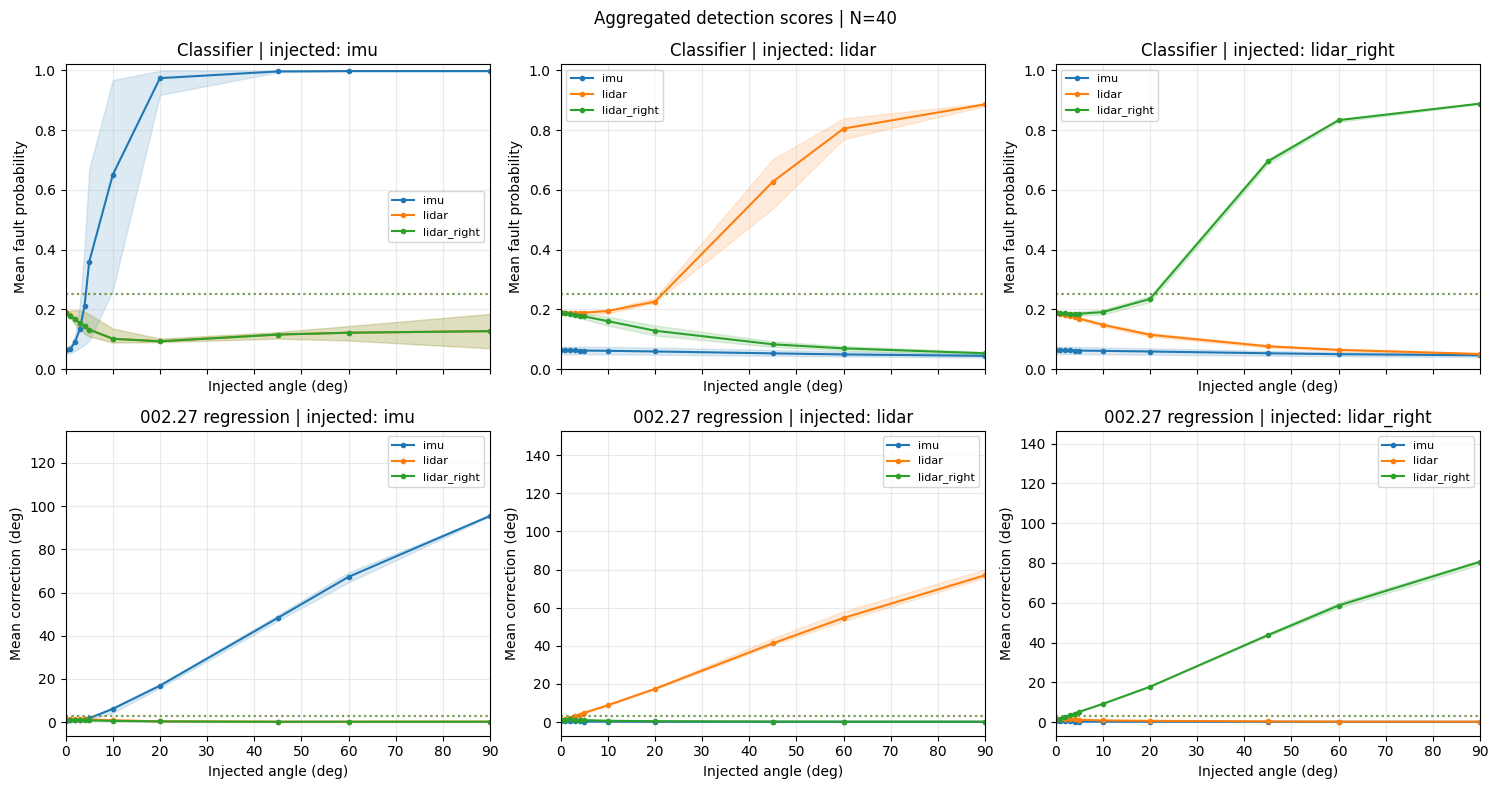

In [80]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)

for col, selected_sensor in enumerate(CALIBRATION_KEYS):
    subset = rotation_cases.loc[rotation_cases.selected_sensor == selected_sensor]

    for row, (field, thresholds, title) in enumerate([
        ('prob_rotation', CLASSIFIER_ROT_THRESHOLDS, 'Classifier'),
        ('reg_rotation_deg', REGRESSOR_ROT_THRESHOLDS_DEG, '002.27 regression'),
    ]):
        ax = axes[row, col]

        for sensor in CALIBRATION_KEYS:
            part = subset.loc[subset.sensor == sensor]

            q = part.groupby('angle_deg')[field].quantile([0.1, 0.5, 0.9]).unstack()
            x = q.index.to_numpy(float)

            line, = ax.plot(x, q[0.5], '-o', markersize=3, label=sensor)
            ax.fill_between(x, q[0.1], q[0.9], color=line.get_color(), alpha=0.15)

            ax.axhline(thresholds[sensor], color=line.get_color(), linestyle=':', alpha=0.5)

        ax.set(
            title=f'{title} | injected: {selected_sensor}',
            xlabel='Injected angle (deg)',
            ylabel='Mean fault probability' if row == 0 else 'Mean correction (deg)',
            xlim=(0, 90),
        )

        if row == 0:
            ax.set_ylim(0, 1.02)

        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)

fig.suptitle(f'Aggregated detection scores | N={WINDOWS_PER_DECISION}')
fig.tight_layout()

if SAVE_PLOTS:
    fig.savefig(APPENDIX_DIR / f'aggregated_scores_N{WINDOWS_PER_DECISION}.png', dpi=PLOT_DPI, bbox_inches='tight')

if SHOW_PLOTS:
    plt.show()
else:
    plt.close(fig)

In [ ]:
rotation_probe = appendix_probe_df.loc[
    appendix_probe_df['sweep'] == 'rotation'
]

for sequence in VAL_NAMES:
    available = set(val_dataset.window_indices_for_sequence(sequence))
    evaluated = set(rotation_probe['physical_index'].unique())
    used = available.intersection(evaluated)

    print(f'{sequence}: {len(available)} available, {len(used)} evaluated')

Urban26: 94 available, 40 evaluated
Urban28: 324 available, 40 evaluated
